<a href="https://colab.research.google.com/github/timotheysski/Quantum-Time-of-Arrival-Papers/blob/main/TOA_Quantum_Gas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Final figures paper

## Fig 1: TOA plots

Fig 1 done.  mean(Tc-)=0.9004  std(Tc-)=0.9489
Fig 2 done.  sharp ratio (eps->0) = 2.5679  R_inf = 2.5556


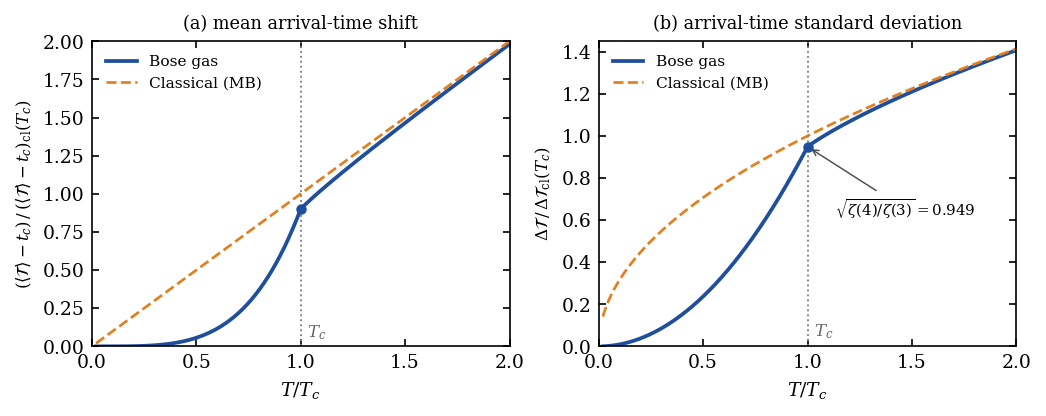

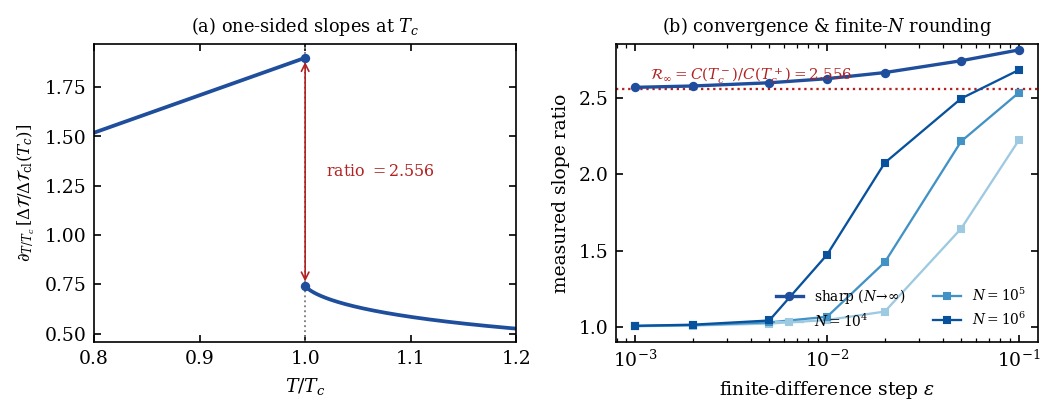

In [ ]:
#!/usr/bin/env python3
"""
Figures for "A universal dynamical signature of Bose-Einstein condensation
revealed through time-of-arrival statistics".

Produces:
  fig_TOA_fluctuations.pdf  - (a) mean arrival-time shift, (b) TOA std dev vs T/Tc
  fig_TOA_kink_ratio.pdf    - (a) one-sided slopes at Tc, (b) convergence + finite-N

Physics (sharp thermodynamic limit, units kB = m = Tc = 1):
  velocity variance  sigma_V^2(T) = (kB T/m) R(T),  R = Li_4(z)/Li_3(z)   [T > Tc]
  with z(T) from   Li_3(z) = zeta(3) (Tc/T)^3
  below Tc (z=1, condensate variance neglected): sigma_V^2 = (T/Tc)^4 * zeta(4)/zeta(3)

  std dev:        DeltaT      ~ sqrt(sigma_V^2)          -> normalized: sqrt(R1) at Tc
  mean shift:     <T> - t_c   ~ sigma_V^2  (Eq. <T>-t_c = DeltaT^2/2t_c) -> R1 at Tc
  cusp ratio of BOTH = C(Tc-)/C(Tc+) = 2.5556 (specific-heat ratio)
"""
import numpy as np, mpmath as mp
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.optimize import brentq
mp.mp.dps = 20
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.linewidth": 0.8,
    "mathtext.fontset": "dejavuserif", "figure.dpi": 150,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})
z2, z3, z4 = float(mp.zeta(2)), float(mp.zeta(3)), float(mp.zeta(4))
R1 = z4 / z3                                   # 0.9004
RINF = 4 * z4 / (4 * z4 - 3 * z3**2 / z2)      # 2.55561  (= C-/C+)

def zfug(TT):
    if TT <= 1.0:
        return 1.0
    tgt = z3 * TT**-3
    return brentq(lambda z: float(mp.polylog(3, z)) - tgt, 1e-14, 1 - 1e-14)

def sigmaV2(TT):                               # reduced sigma_V^2 in units kB Tc / m
    if TT <= 1.0:
        return (TT**4) * R1                    # (T/Tc)^4 * zeta(4)/zeta(3)
    z = zfug(TT)
    return TT * float(mp.polylog(4, z) / mp.polylog(3, z))   # (T/Tc) R(T)

# normalized observables (both = 1 for MB at Tc would be the ref; here Bose):
mean_norm = lambda TT: sigmaV2(TT)             # (<T>-tc)/(<T>-tc)_cl(Tc)  ∝ sigma_V^2
std_norm  = lambda TT: np.sqrt(sigmaV2(TT))    # DeltaT/DeltaT_cl(Tc)       ∝ sqrt
mb_mean   = lambda TT: TT                       # MB reference for the mean (∝ T)
mb_std    = lambda TT: np.sqrt(TT)              # MB reference for the std  (∝ sqrt T)

# ───────────────────────── Figure 1 : mean & std vs T/Tc ─────────────────────────
Tg = np.linspace(0.02, 2.0, 800)
fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.9, 2.7))

axa.plot(Tg, [mean_norm(t) for t in Tg], '-', color="#1f4e9c", lw=1.8,
         label=r"Bose gas")
axa.plot(Tg, mb_mean(Tg), '--', color="#e08020", lw=1.3, label="Classical (MB)")
axa.axvline(1, ls=":", color="0.5", lw=0.9)
axa.plot([1], [R1], 'o', color="#1f4e9c", ms=4, zorder=5)
axa.set_xlabel(r"$T/T_c$")
axa.set_ylabel(r"$(\langle\mathcal{T}\rangle - t_c)\,/\,(\langle\mathcal{T}\rangle - t_c)_{\rm cl}(T_c)$",
               fontsize=8)
axa.set_title(r"(a) mean arrival-time shift", fontsize=8.5)
axa.set_xlim(0, 2); axa.set_ylim(0, 2.0)
axa.legend(fontsize=7.4, frameon=False, loc="upper left")
axa.text(1.03, 0.06, r"$T_c$", color="0.4", fontsize=8)

axb.plot(Tg, [std_norm(t) for t in Tg], '-', color="#1f4e9c", lw=1.8,
         label=r"Bose gas")
axb.plot(Tg, mb_std(Tg), '--', color="#e08020", lw=1.3, label="Classical (MB)")
axb.axvline(1, ls=":", color="0.5", lw=0.9)
axb.plot([1], [np.sqrt(R1)], 'o', color="#1f4e9c", ms=4, zorder=5)
axb.annotate(r"$\sqrt{\zeta(4)/\zeta(3)}=0.949$", xy=(1, np.sqrt(R1)),
             xytext=(1.13, 0.62), fontsize=7.2,
             arrowprops=dict(arrowstyle="->", lw=0.7, color="0.3"))
axb.set_xlabel(r"$T/T_c$")
axb.set_ylabel(r"$\Delta\mathcal{T}\,/\,\Delta\mathcal{T}_{\rm cl}(T_c)$", fontsize=8)
axb.set_title(r"(b) arrival-time standard deviation", fontsize=8.5)
axb.set_xlim(0, 2); axb.set_ylim(0, 1.45)
axb.legend(fontsize=7.4, frameon=False, loc="upper left")
axb.text(1.03, 0.05, r"$T_c$", color="0.4", fontsize=8)

fig.tight_layout(pad=0.5)
fig.savefig("fig_TOA_fluctuations.pdf", bbox_inches="tight")
fig.savefig("fig_TOA_fluctuations.png", bbox_inches="tight", dpi=200)
print("Fig 1 done.  mean(Tc-)=%.4f  std(Tc-)=%.4f" % (R1, np.sqrt(R1)))

# ───────────── Figure 2 : kink ratio — sharp 2.5556 + finite-N rounding ─────────────
Tl = np.linspace(0.80, 0.999, 200); Tr = np.linspace(1.001, 1.20, 200)
dl = np.array([(std_norm(t) - std_norm(t - 1e-4)) / 1e-4 for t in Tl])
dr = np.array([(std_norm(t + 1e-4) - std_norm(t)) / 1e-4 for t in Tr])
sL = 2 * np.sqrt(R1); sR = sL / RINF

def fd_ratio_sharp(eps):
    f0, fm, fp = std_norm(1.0), std_norm(1 - eps), std_norm(1 + eps)
    return ((f0 - fm) / eps) / ((fp - f0) / eps)

eps_g = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1])
rat_sharp = np.array([fd_ratio_sharp(e) for e in eps_g])

def ratio_finiteN(N, nmax, eps):
    n = np.arange(0, nmax + 1.0); g = (n + 1) * (n + 2) / 2
    tcu = (N / z3)**(1 / 3)
    def mu(t):
        lo, hi = -60.0, -1e-9
        for _ in range(200):
            mid = .5 * (lo + hi)
            (lo, hi) = (mid, hi) if np.sum(g / np.expm1((n - mid) / t)) < N else (lo, mid)
        return .5 * (lo + hi)
    def s(TT):
        t = TT * tcu
        return np.sqrt(np.sum(g / np.expm1((n - mu(t)) / t) * (n / 3 + 0.5)) / N)
    s0, sm, sp = s(1.0), s(1 - eps), s(1 + eps)
    return ((s0 - sm) / eps) / ((sp - s0) / eps)

Ncases = [(1e4, 400, "#9ecae1"), (1e5, 900, "#4292c6"), (1e6, 2200, "#08519c")]
ratN = {N: np.array([ratio_finiteN(int(N), nmax, e) for e in eps_g]) for N, nmax, _ in Ncases}

fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.9, 2.7))
axa.plot(Tl, dl, color="#1f4e9c", lw=1.8); axa.plot(Tr, dr, color="#1f4e9c", lw=1.8)
axa.axvline(1, ls=":", color="0.5", lw=0.9)
axa.annotate("", xy=(1, sL), xytext=(1, sR),
             arrowprops=dict(arrowstyle="<->", lw=0.8, color="#b22222"))
axa.text(1.02, 0.5 * (sL + sR), r"ratio $=2.556$", color="#b22222", fontsize=7.6, va="center")
axa.plot([1], [sL], 'o', [1], [sR], 'o', color="#1f4e9c", ms=3.5)
axa.set_xlabel(r"$T/T_c$")
axa.set_ylabel(r"$\partial_{T/T_c}\,[\Delta\mathcal{T}/\Delta\mathcal{T}_{\rm cl}(T_c)]$", fontsize=8)
axa.set_xlim(0.8, 1.2); axa.set_title("(a) one-sided slopes at $T_c$", fontsize=8.5)

axb.axhline(RINF, ls=":", color="#b22222", lw=1.1)
axb.text(0.0012, RINF + 0.06, r"$\mathcal{R}_\infty=C(T_c^-)/C(T_c^+)=2.556$",
         color="#b22222", fontsize=7.2)
axb.plot(eps_g, rat_sharp, '-o', color="#1f4e9c", lw=1.6, ms=3.5, label=r"sharp ($N\!\to\!\infty$)")
for N, nmax, c in Ncases:
    axb.plot(eps_g, ratN[N], '-s', color=c, lw=1.1, ms=3, label=rf"$N=10^{{{int(np.log10(N))}}}$")
axb.set_xscale("log"); axb.set_xlabel(r"finite-difference step $\varepsilon$")
axb.set_ylabel(r"measured slope ratio")
axb.set_ylim(0.9, 2.85); axb.set_title("(b) convergence & finite-$N$ rounding", fontsize=8.5)
axb.legend(fontsize=6.6, frameon=False, loc="lower right", ncol=2)
fig.tight_layout(pad=0.5)
fig.savefig("fig_TOA_kink_ratio.pdf", bbox_inches="tight")
fig.savefig("fig_TOA_kink_ratio.png", bbox_inches="tight", dpi=200)
print("Fig 2 done.  sharp ratio (eps->0) =", round(rat_sharp[0], 4), " R_inf =", round(RINF, 4))

## Fig 2: Universality


Finite-N Bose-statistical TOA calculation
System: ideal Bose gas in a 3D isotropic harmonic trap
Spatial dimension d = 3
n = shell index n_x+n_y+n_z, not particle number
zeta(4)/zeta(3) = 0.90039268
sqrt[zeta(4)/zeta(3)] = 0.94889023
Thermodynamic kink ratio R_inf = 2.55560719
Include zero-point velocity width: True

Spectral cutoffs:
  N=1e+03: tau_c=9.4050, nmax=709, number of shells=710
  N=1e+04: tau_c=20.2624, nmax=1469, number of shells=1470
  N=1e+05: tau_c=43.6541, nmax=3106, number of shells=3107
  N=1e+06: tau_c=94.0499, nmax=6634, number of shells=6635

Computing full finite-N TOA curves for N=1e+03

Computing full finite-N TOA curves for N=1e+04

Computing full finite-N TOA curves for N=1e+05

Computing full finite-N TOA curves for N=1e+06

Computing finite-N slope ratios

N=1e+03
  eps=0.00100   ratio_mean=1.0023   ratio_std=1.0031
  eps=0.00129   ratio_mean=1.0030   ratio_std=1.0040
  eps=0.00167   ratio_mean=1.0039   ratio_std=1.0052
  eps=0.00217   ratio_mean=1.0051   

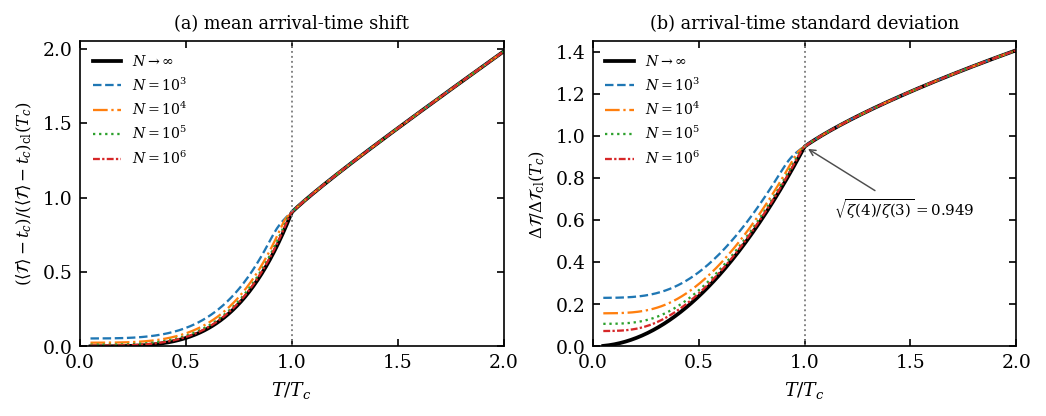

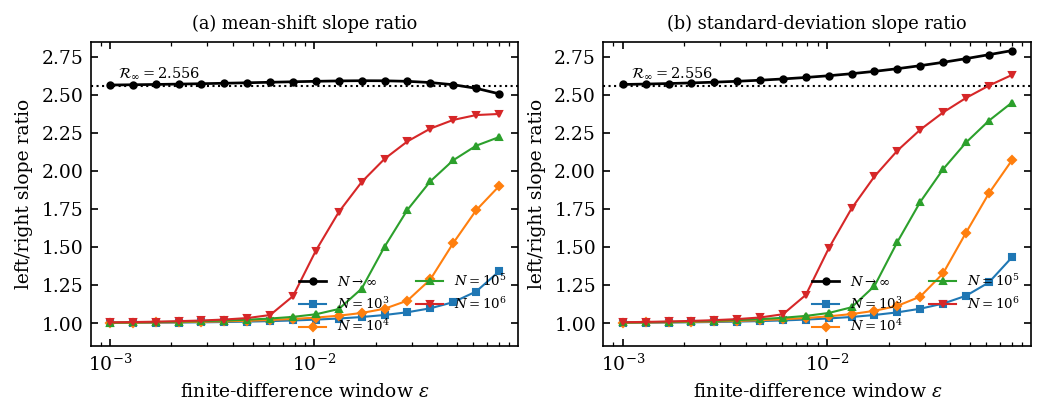

In [ ]:
#!/usr/bin/env python3
"""
Paper-ready finite-N Bose-statistical TOA figures
=================================================

System
------
Ideal Bose gas in a 3D isotropic harmonic trap.

Single-particle spectrum:
    E_n = hbar omega (n + 3/2),      n = 0,1,2,...
    g_n = (n+1)(n+2)/2.

Important notation:
    N  = total atom number.
    n  = 3D harmonic-oscillator shell index, n = n_x+n_y+n_z.
         It is dimensionless and is NOT the particle number.
    g_n = degeneracy of shell n in three spatial dimensions.
    d  = 3 spatial dimensions.

We shift the zero of energy to the oscillator ground state and define
    tau = k_B T/(hbar omega),
    mu  = [mu_phys - (3/2) hbar omega]/(hbar omega) <= 0.

For each T and N, the shifted chemical potential mu is found from
    N = sum_{n=0}^{nmax} g_n / (exp[(n-mu)/tau] - 1).

The one-dimensional velocity variance of shell n is
    <v_x^2>_n = (hbar omega/m) (n/3 + 1/2).

The finite-N dimensionless variance is
    sigma_v^2 / (k_B T_c/m)
      = (1/tau_c) (1/N) sum_n N_n (n/3 + 1/2),

where
    tau_c = (N/zeta(3))^(1/3)

is the harmonic-trap thermodynamic critical temperature in units
hbar omega/k_B.

TOA normalization
-----------------
Small-velocity expansion:
    Delta T_TOA ∝ sqrt(sigma_v^2),
    <T> - t_c = Delta T_TOA^2/(2 t_c) ∝ sigma_v^2.

Therefore:
    mean_shift_norm = sigma_v^2/(k_B T_c/m),
    std_norm        = sqrt[sigma_v^2/(k_B T_c/m)].

This script computes:
  1. Full finite-N Bose curves by solving mu(T,N).
  2. The sharp thermodynamic-limit polylog curve.
  3. Finite-N rounding of the one-sided slope ratio at T_c.

Outputs
-------
  fig_TOA_finiteN_curves.pdf
  fig_TOA_finiteN_curves.png
  fig_TOA_kink_finiteN.pdf
  fig_TOA_kink_finiteN.png
  finiteN_TOA_curves.csv
  finiteN_slope_ratios.csv
  finiteN_eps_star.csv
"""

from __future__ import annotations

import math
import time
from dataclasses import dataclass
from functools import lru_cache

import numpy as np
import pandas as pd
import mpmath as mp
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import brentq


# ───────────────────────── User parameters ─────────────────────────

# Atom numbers used in the figures.
N_CURVES = [10**3, 10**4, 10**5, 10**6]
N_RATIOS = [10**3, 10**4, 10**5, 10**6]

# Temperature grid in theta = T/Tc.
THETA_MIN = 0.05
THETA_MAX = 2.00
N_THETA = 300

# Finite-difference windows epsilon for slope ratios around theta=1.
EPS_GRID = np.logspace(np.log10(1e-3), np.log10(8e-2), 18)

# For the finite-size scale epsilon*(N), define the target ratio.
EPS_STAR_TARGET = 1.5

# Include the physical ground-state momentum width +1/2.
# True is physical finite-N. False gives the purely thermal part n/3 only.
INCLUDE_ZERO_POINT = True

# Cutoff control for the harmonic spectrum:
# nmax ≈ TAIL_CUT * tau_max + 50.
TAIL_CUT = 35.0


# ───────────────────────── Plot style ─────────────────────────

mp.mp.dps = 30

mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.linewidth": 0.8,
    "mathtext.fontset": "dejavuserif",
    "figure.dpi": 150,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": False,
})


# ───────────────────────── Constants ─────────────────────────

ZETA2 = float(mp.zeta(2))
ZETA3 = float(mp.zeta(3))
ZETA4 = float(mp.zeta(4))

R1 = ZETA4 / ZETA3

# Thermodynamic-limit one-sided slope ratio.
RINF = 4.0 * ZETA4 / (4.0 * ZETA4 - 3.0 * ZETA3**2 / ZETA2)


# ───────────────────── Thermodynamic-limit formulas ─────────────────────

@lru_cache(maxsize=4096)
def fugacity_thermo(theta_key: float) -> float:
    """
    Fugacity z for theta = T/Tc > 1:
        Li_3(z) = zeta(3) theta^{-3}.

    theta_key is rounded before caching.
    """
    theta = float(theta_key)
    if theta <= 1.0:
        return 1.0

    target = ZETA3 * theta**(-3)

    def f(z: float) -> float:
        return float(mp.polylog(3, z)) - target

    return brentq(f, 1e-15, 1.0 - 1e-14, xtol=1e-14, rtol=1e-14, maxiter=100)


def sigma_v2_thermo(theta: float) -> float:
    """
    Thermodynamic-limit dimensionless variance:
        sigma_v^2/(k_B T_c/m).

    Below Tc:
        theta^4 zeta(4)/zeta(3).

    Above Tc:
        theta Li_4(z)/Li_3(z).
    """
    theta = float(theta)

    if theta <= 1.0:
        return R1 * theta**4

    z = fugacity_thermo(round(theta, 12))
    return theta * float(mp.polylog(4, z) / mp.polylog(3, z))


def mean_norm_thermo(theta: float) -> float:
    return sigma_v2_thermo(theta)


def std_norm_thermo(theta: float) -> float:
    return math.sqrt(sigma_v2_thermo(theta))


# ───────────────────── Finite-N Bose calculation ─────────────────────

@dataclass
class Spectrum:
    """
    Discrete 3D harmonic oscillator spectrum.

    N:
        Total atom number.
    tau_c:
        Thermodynamic critical temperature in units hbar omega/k_B.
    n:
        Shell index array, n = 0,1,2,...,nmax.
    g:
        Degeneracy of shell n in 3D, g_n=(n+1)(n+2)/2.
    q:
        Dimensionless one-dimensional velocity factor, n/3+1/2.
    """
    N: int
    tau_c: float
    n: np.ndarray
    g: np.ndarray
    q: np.ndarray


def choose_nmax(N: int, theta_max: float, tail_cut: float = TAIL_CUT) -> int:
    """
    Conservative cutoff for the harmonic shell sum.

    tau_max = theta_max * tau_c.
    Since the high-energy Bose tail decays roughly as exp(-n/tau),
    nmax ≈ tail_cut * tau_max is safe for the plotted range.
    """
    tau_c = (N / ZETA3)**(1.0 / 3.0)
    tau_max = theta_max * tau_c
    return max(300, int(math.ceil(tail_cut * tau_max + 50.0)))


def make_spectrum(N: int, theta_max: float = THETA_MAX) -> Spectrum:
    N = int(N)
    tau_c = (N / ZETA3)**(1.0 / 3.0)
    nmax = choose_nmax(N, theta_max)

    n = np.arange(nmax + 1, dtype=np.float64)
    g = 0.5 * (n + 1.0) * (n + 2.0)
    q = n / 3.0 + 0.5

    return Spectrum(N=N, tau_c=tau_c, n=n, g=g, q=q)


def bose_occupations(mu: float, tau: float, spec: Spectrum) -> np.ndarray:
    """
    Bose occupations including degeneracy:
        N_n = g_n/[exp((n-mu)/tau)-1].
    """
    x = (spec.n - mu) / tau

    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        occ = spec.g / np.expm1(x)

    # expm1 may overflow at very large x, giving occupation 0.
    occ = np.where(np.isfinite(occ), occ, 0.0)
    return occ


def number_at_mu(mu: float, tau: float, spec: Spectrum) -> float:
    return float(np.sum(bose_occupations(mu, tau, spec)))


def solve_mu(tau: float, spec: Spectrum) -> float:
    """
    Solve the finite-N Bose number equation for the shifted chemical potential:
        N = sum_n g_n/[exp((n-mu)/tau)-1].

    The shifted mu is always negative and approaches 0 from below
    in the condensed regime.
    """
    N_target = float(spec.N)

    # Upper endpoint very close to 0 from below. This gives very large
    # ground-state occupation, so N(mu=hi) should exceed N_target.
    hi = -1e-13 * max(1.0, tau)

    # Lower endpoint: negative enough that occupations are nearly empty.
    lo = -max(100.0, 10.0 * tau)

    def f(mu: float) -> float:
        return number_at_mu(mu, tau, spec) - N_target

    flo = f(lo)
    fhi = f(hi)

    # Make lower bracket more negative if necessary.
    for _ in range(50):
        if flo < 0.0:
            break
        lo *= 2.0
        flo = f(lo)

    if not (flo < 0.0 and fhi > 0.0):
        raise RuntimeError(
            f"Failed to bracket mu: N={spec.N}, tau={tau}, "
            f"lo={lo}, f(lo)={flo}, hi={hi}, f(hi)={fhi}"
        )

    return brentq(
        f,
        lo,
        hi,
        xtol=1e-12 * max(1.0, tau),
        rtol=1e-12,
        maxiter=120,
    )


def finiteN_observables(theta: float, spec: Spectrum, include_zero_point: bool = True):
    """
    Full finite-N Bose-statistical observables at theta=T/Tc.

    Returns:
        mean_norm, std_norm, mu, N0_fraction, Nex_fraction.
    """
    tau = float(theta) * spec.tau_c
    mu = solve_mu(tau, spec)

    occ = bose_occupations(mu, tau, spec)

    if include_zero_point:
        q_eff = spec.q               # n/3 + 1/2
    else:
        q_eff = spec.n / 3.0         # thermal part only

    sigma_v2_reduced = float(np.sum(occ * q_eff) / spec.N / spec.tau_c)
    sigma_v2_reduced = max(sigma_v2_reduced, 0.0)

    mean_norm = sigma_v2_reduced
    std_norm = math.sqrt(sigma_v2_reduced)

    N0_fraction = float(occ[0] / spec.N)
    Nex_fraction = 1.0 - N0_fraction

    return mean_norm, std_norm, mu, N0_fraction, Nex_fraction


# ───────────────────── Slope ratio and FSS tools ─────────────────────

def finite_difference_ratio(f, eps: float) -> float:
    """
    Left/right finite-difference slope ratio around theta=1:
        [(f(1)-f(1-eps))/eps] / [(f(1+eps)-f(1))/eps].
    """
    f0 = f(1.0)
    fm = f(1.0 - eps)
    fp = f(1.0 + eps)

    left = (f0 - fm) / eps
    right = (fp - f0) / eps

    return left / right


def finiteN_slope_ratios(spec: Spectrum, eps: float, include_zero_point: bool = True):
    """
    Finite-N left/right slope ratios for mean shift and standard deviation.
    """
    m_minus, s_minus, *_ = finiteN_observables(1.0 - eps, spec, include_zero_point)
    m_0,     s_0,     *_ = finiteN_observables(1.0,       spec, include_zero_point)
    m_plus,  s_plus,  *_ = finiteN_observables(1.0 + eps, spec, include_zero_point)

    r_mean = ((m_0 - m_minus) / eps) / ((m_plus - m_0) / eps)
    r_std  = ((s_0 - s_minus) / eps) / ((s_plus - s_0) / eps)

    return r_mean, r_std


def find_eps_star(eps_arr, ratio_arr, target: float = EPS_STAR_TARGET) -> float:
    """
    Find epsilon where ratio crosses target.
    Interpolation is linear in log(epsilon).
    """
    eps_arr = np.asarray(eps_arr, dtype=float)
    ratio_arr = np.asarray(ratio_arr, dtype=float)

    mask = np.isfinite(eps_arr) & np.isfinite(ratio_arr) & (eps_arr > 0)
    eps_v = eps_arr[mask]
    ratio_v = ratio_arr[mask]

    if len(eps_v) < 2:
        return np.nan

    order = np.argsort(eps_v)
    eps_v = eps_v[order]
    ratio_v = ratio_v[order]

    for i in range(len(eps_v) - 1):
        r0, r1 = ratio_v[i], ratio_v[i + 1]
        if (r0 - target) * (r1 - target) <= 0:
            if r1 == r0:
                return float(eps_v[i])

            le0 = np.log(eps_v[i])
            le1 = np.log(eps_v[i + 1])
            alpha = (target - r0) / (r1 - r0)

            return float(np.exp(le0 + alpha * (le1 - le0)))

    return np.nan


# ───────────────────────── Main calculation ─────────────────────────

def main() -> None:
    t0 = time.time()

    print("\nFinite-N Bose-statistical TOA calculation")
    print("System: ideal Bose gas in a 3D isotropic harmonic trap")
    print(f"Spatial dimension d = 3")
    print(f"n = shell index n_x+n_y+n_z, not particle number")
    print(f"zeta(4)/zeta(3) = {R1:.8f}")
    print(f"sqrt[zeta(4)/zeta(3)] = {math.sqrt(R1):.8f}")
    print(f"Thermodynamic kink ratio R_inf = {RINF:.8f}")
    print(f"Include zero-point velocity width: {INCLUDE_ZERO_POINT}")

    # Build spectra.
    all_N = sorted(set(N_CURVES + N_RATIOS))
    spectra = {}

    print("\nSpectral cutoffs:")
    for N in all_N:
        spec = make_spectrum(N, theta_max=THETA_MAX)
        spectra[N] = spec
        print(
            f"  N={N:.0e}: tau_c={spec.tau_c:.4f}, "
            f"nmax={int(spec.n[-1])}, number of shells={len(spec.n)}"
        )

    # ─── Full finite-N curves ───
    theta_grid = np.linspace(THETA_MIN, THETA_MAX, N_THETA)

    curve_rows = []

    for N in N_CURVES:
        spec = spectra[N]
        print(f"\nComputing full finite-N TOA curves for N={N:.0e}")

        for theta in theta_grid:
            mean_norm, std_norm, mu, N0_frac, Nex_frac = finiteN_observables(
                theta,
                spec,
                include_zero_point=INCLUDE_ZERO_POINT,
            )

            curve_rows.append({
                "N": N,
                "theta_T_over_Tc": theta,
                "mean_shift_norm": mean_norm,
                "std_norm": std_norm,
                "mu_shifted": mu,
                "N0_fraction": N0_frac,
                "Nex_fraction": Nex_frac,
            })

    df_curves = pd.DataFrame(curve_rows)
    df_curves.to_csv("finiteN_TOA_curves.csv", index=False)

    # Thermodynamic reference curve.
    mean_th = np.array([mean_norm_thermo(theta) for theta in theta_grid])
    std_th = np.sqrt(mean_th)

    # Figure 1: finite-N curves plus thermodynamic limit.
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.9, 2.7))

    ax1.plot(theta_grid, mean_th, color="black", lw=1.8, label=r"$N\to\infty$")
    ax2.plot(theta_grid, std_th, color="black", lw=1.8, label=r"$N\to\infty$")

    linestyles = ["--", "-.", ":", (0, (3, 1, 1, 1))]

    for ls, N in zip(linestyles, N_CURVES):
        dN = df_curves[df_curves["N"] == N]
        label = rf"$N=10^{{{int(np.log10(N))}}}$"

        ax1.plot(
            dN["theta_T_over_Tc"],
            dN["mean_shift_norm"],
            ls=ls,
            lw=1.1,
            label=label,
        )
        ax2.plot(
            dN["theta_T_over_Tc"],
            dN["std_norm"],
            ls=ls,
            lw=1.1,
            label=label,
        )

    for ax in (ax1, ax2):
        ax.axvline(1.0, ls=":", color="0.5", lw=0.9)
        ax.set_xlim(0.0, THETA_MAX)
        ax.set_xlabel(r"$T/T_c$")
        ax.legend(fontsize=6.8, loc="upper left")

    ax1.set_ylim(0.0, 2.05)
    ax2.set_ylim(0.0, 1.45)

    ax1.set_title(r"(a) mean arrival-time shift", fontsize=8.5)
    ax2.set_title(r"(b) arrival-time standard deviation", fontsize=8.5)

    ax1.set_ylabel(
        r"$(\langle\mathcal{T}\rangle-t_c)/(\langle\mathcal{T}\rangle-t_c)_{\rm cl}(T_c)$",
        fontsize=8,
    )
    ax2.set_ylabel(
        r"$\Delta\mathcal{T}/\Delta\mathcal{T}_{\rm cl}(T_c)$",
        fontsize=8,
    )

    ax2.annotate(
        r"$\sqrt{\zeta(4)/\zeta(3)}=0.949$",
        xy=(1.0, math.sqrt(R1)),
        xytext=(1.14, 0.62),
        fontsize=7.2,
        arrowprops=dict(arrowstyle="->", lw=0.7, color="0.3"),
    )

    fig.tight_layout(pad=0.5)
    fig.savefig("fig_TOA_finiteN_curves.pdf", bbox_inches="tight")
    fig.savefig("fig_TOA_finiteN_curves.png", bbox_inches="tight", dpi=250)

    # ─── Finite-N slope ratios ───
    ratio_rows = []

    print("\nComputing finite-N slope ratios")
    for N in N_RATIOS:
        spec = spectra[N]
        print(f"\nN={N:.0e}")

        for eps in EPS_GRID:
            r_mean, r_std = finiteN_slope_ratios(
                spec,
                float(eps),
                include_zero_point=INCLUDE_ZERO_POINT,
            )

            ratio_rows.append({
                "N": N,
                "epsilon": eps,
                "ratio_mean": r_mean,
                "ratio_std": r_std,
            })

            print(
                f"  eps={eps:.5f}   "
                f"ratio_mean={r_mean:.4f}   ratio_std={r_std:.4f}"
            )

    df_ratios = pd.DataFrame(ratio_rows)
    df_ratios.to_csv("finiteN_slope_ratios.csv", index=False)

    # Thermodynamic finite-difference ratios.
    r_mean_sharp = np.array([
        finite_difference_ratio(mean_norm_thermo, float(eps)) for eps in EPS_GRID
    ])
    r_std_sharp = np.array([
        finite_difference_ratio(std_norm_thermo, float(eps)) for eps in EPS_GRID
    ])

    # Extract epsilon-star.
    eps_star_rows = []
    for N in N_RATIOS:
        dN = df_ratios[df_ratios["N"] == N].sort_values("epsilon")

        eps_star_rows.append({
            "N": N,
            "eps_star_mean": find_eps_star(
                dN["epsilon"].values,
                dN["ratio_mean"].values,
                target=EPS_STAR_TARGET,
            ),
            "eps_star_std": find_eps_star(
                dN["epsilon"].values,
                dN["ratio_std"].values,
                target=EPS_STAR_TARGET,
            ),
        })

    df_eps_star = pd.DataFrame(eps_star_rows)
    df_eps_star.to_csv("finiteN_eps_star.csv", index=False)

    print("\nEpsilon-star table:")
    print(df_eps_star.to_string(index=False))

    # Figure 2: slope-ratio convergence.
    fig2, (bx1, bx2) = plt.subplots(1, 2, figsize=(6.9, 2.7))

    bx1.axhline(RINF, ls=":", color="black", lw=1.0)
    bx2.axhline(RINF, ls=":", color="black", lw=1.0)

    bx1.plot(
        EPS_GRID,
        r_mean_sharp,
        "o-",
        color="black",
        lw=1.3,
        ms=3.0,
        label=r"$N\to\infty$",
    )
    bx2.plot(
        EPS_GRID,
        r_std_sharp,
        "o-",
        color="black",
        lw=1.3,
        ms=3.0,
        label=r"$N\to\infty$",
    )

    markers = ["s", "D", "^", "v"]

    for marker, N in zip(markers, N_RATIOS):
        dN = df_ratios[df_ratios["N"] == N].sort_values("epsilon")
        label = rf"$N=10^{{{int(np.log10(N))}}}$"

        bx1.plot(
            dN["epsilon"],
            dN["ratio_mean"],
            marker + "-",
            lw=1.0,
            ms=3.0,
            label=label,
        )
        bx2.plot(
            dN["epsilon"],
            dN["ratio_std"],
            marker + "-",
            lw=1.0,
            ms=3.0,
            label=label,
        )

    for ax, title in [
        (bx1, r"(a) mean-shift slope ratio"),
        (bx2, r"(b) standard-deviation slope ratio"),
    ]:
        ax.set_xscale("log")
        ax.set_xlabel(r"finite-difference window $\varepsilon$")
        ax.set_ylabel(r"left/right slope ratio")
        ax.set_ylim(0.85, 2.85)
        ax.set_title(title, fontsize=8.5)
        ax.legend(fontsize=6.4, loc="lower right", ncol=2)
        ax.text(
            EPS_GRID[0] * 1.1,
            RINF + 0.06,
            r"$\mathcal{R}_\infty=2.556$",
            fontsize=7.0,
        )

    fig2.tight_layout(pad=0.5)
    fig2.savefig("fig_TOA_kink_finiteN.pdf", bbox_inches="tight")
    fig2.savefig("fig_TOA_kink_finiteN.png", bbox_inches="tight", dpi=250)

    print("\nDONE")
    print("Figures:")
    print("  fig_TOA_finiteN_curves.pdf/png")
    print("  fig_TOA_kink_finiteN.pdf/png")
    print("CSV:")
    print("  finiteN_TOA_curves.csv")
    print("  finiteN_slope_ratios.csv")
    print("  finiteN_eps_star.csv")
    print(f"Runtime: {time.time() - t0:.1f} s")


if __name__ == "__main__":
    main()

## Fig 0

Fig 1 done.  mean(Tc-)=0.9004  std(Tc-)=0.9489
Fig 2 done.  sharp ratio (eps->0) = 2.5679  R_inf = 2.5556
Fig S1 done.  exact-vs-semiclassical comparison written.


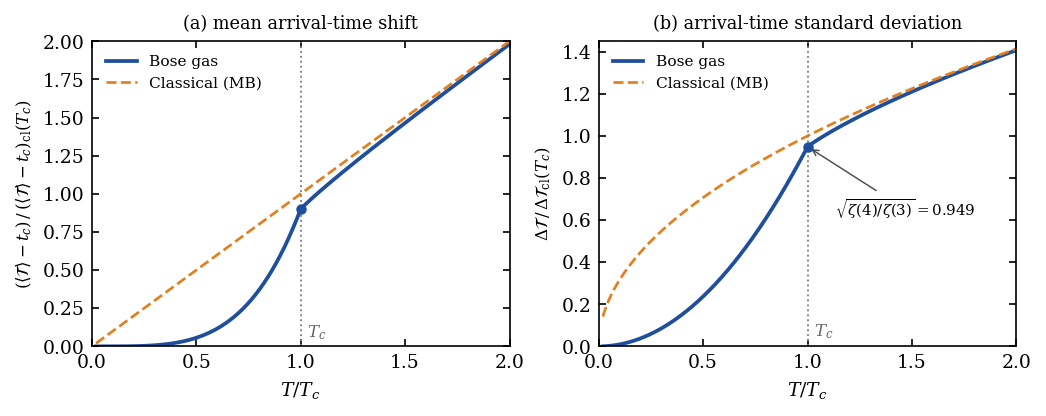

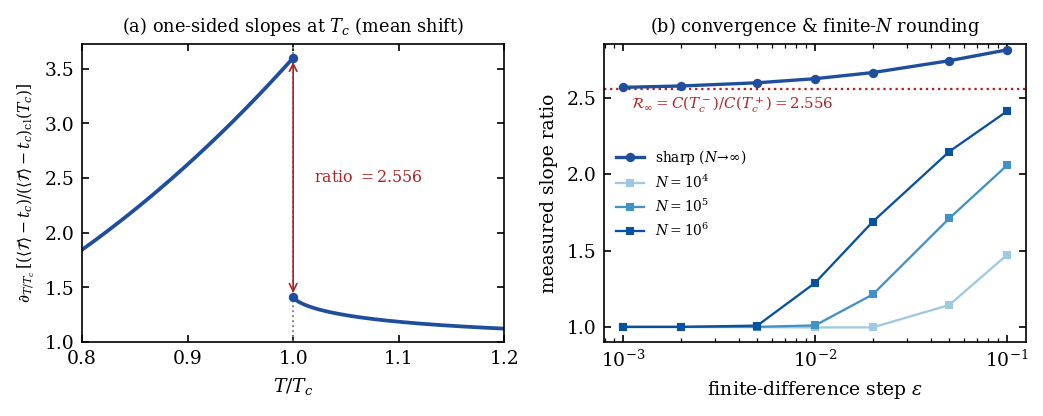

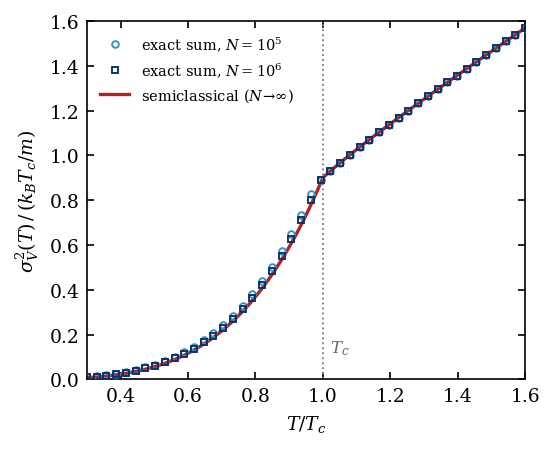

In [ ]:
#!/usr/bin/env python3
"""
Figures for "A universal dynamical signature of Bose-Einstein condensation
revealed through time-of-arrival statistics".

Produces:
  fig_TOA_fluctuations.pdf  - (a) mean arrival-time shift, (b) TOA std dev vs T/Tc
  fig_TOA_kink_ratio.pdf    - (a) one-sided slopes at Tc, (b) convergence + finite-N

Physics (sharp thermodynamic limit, units kB = m = Tc = 1):
  velocity variance  sigma_V^2(T) = (kB T/m) R(T),  R = Li_4(z)/Li_3(z)   [T > Tc]
  with z(T) from   Li_3(z) = zeta(3) (Tc/T)^3
  below Tc (z=1, condensate variance neglected): sigma_V^2 = (T/Tc)^4 * zeta(4)/zeta(3)

  std dev:        DeltaT      ~ sqrt(sigma_V^2)          -> normalized: sqrt(R1) at Tc
  mean shift:     <T> - t_c   ~ sigma_V^2  (Eq. <T>-t_c = DeltaT^2/2t_c) -> R1 at Tc
  cusp ratio of BOTH = C(Tc-)/C(Tc+) = 2.5556 (specific-heat ratio)
"""
import numpy as np, mpmath as mp
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.optimize import brentq
mp.mp.dps = 20
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.linewidth": 0.8,
    "mathtext.fontset": "dejavuserif", "figure.dpi": 150,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})
z2, z3, z4 = float(mp.zeta(2)), float(mp.zeta(3)), float(mp.zeta(4))
R1 = z4 / z3                                   # 0.9004
RINF = 4 * z4 / (4 * z4 - 3 * z3**2 / z2)      # 2.55561  (= C-/C+)

def zfug(TT):
    if TT <= 1.0:
        return 1.0
    tgt = z3 * TT**-3
    return brentq(lambda z: float(mp.polylog(3, z)) - tgt, 1e-14, 1 - 1e-14)

def sigmaV2(TT):                               # reduced sigma_V^2 in units kB Tc / m
    if TT <= 1.0:
        return (TT**4) * R1                    # (T/Tc)^4 * zeta(4)/zeta(3)
    z = zfug(TT)
    return TT * float(mp.polylog(4, z) / mp.polylog(3, z))   # (T/Tc) R(T)

# normalized observables (both = 1 for MB at Tc would be the ref; here Bose):
mean_norm = lambda TT: sigmaV2(TT)             # (<T>-tc)/(<T>-tc)_cl(Tc)  ∝ sigma_V^2
std_norm  = lambda TT: np.sqrt(sigmaV2(TT))    # DeltaT/DeltaT_cl(Tc)       ∝ sqrt
mb_mean   = lambda TT: TT                       # MB reference for the mean (∝ T)
mb_std    = lambda TT: np.sqrt(TT)              # MB reference for the std  (∝ sqrt T)

# ───────────────────────── Figure 1 : mean & std vs T/Tc ─────────────────────────
Tg = np.linspace(0.02, 2.0, 800)
fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.9, 2.7))

axa.plot(Tg, [mean_norm(t) for t in Tg], '-', color="#1f4e9c", lw=1.8,
         label=r"Bose gas")
axa.plot(Tg, mb_mean(Tg), '--', color="#e08020", lw=1.3, label="Classical (MB)")
axa.axvline(1, ls=":", color="0.5", lw=0.9)
axa.plot([1], [R1], 'o', color="#1f4e9c", ms=4, zorder=5)
axa.set_xlabel(r"$T/T_c$")
axa.set_ylabel(r"$(\langle\mathcal{T}\rangle - t_c)\,/\,(\langle\mathcal{T}\rangle - t_c)_{\rm cl}(T_c)$",
               fontsize=8)
axa.set_title(r"(a) mean arrival-time shift", fontsize=8.5)
axa.set_xlim(0, 2); axa.set_ylim(0, 2.0)
axa.legend(fontsize=7.4, frameon=False, loc="upper left")
axa.text(1.03, 0.06, r"$T_c$", color="0.4", fontsize=8)

axb.plot(Tg, [std_norm(t) for t in Tg], '-', color="#1f4e9c", lw=1.8,
         label=r"Bose gas")
axb.plot(Tg, mb_std(Tg), '--', color="#e08020", lw=1.3, label="Classical (MB)")
axb.axvline(1, ls=":", color="0.5", lw=0.9)
axb.plot([1], [np.sqrt(R1)], 'o', color="#1f4e9c", ms=4, zorder=5)
axb.annotate(r"$\sqrt{\zeta(4)/\zeta(3)}=0.949$", xy=(1, np.sqrt(R1)),
             xytext=(1.13, 0.62), fontsize=7.2,
             arrowprops=dict(arrowstyle="->", lw=0.7, color="0.3"))
axb.set_xlabel(r"$T/T_c$")
axb.set_ylabel(r"$\Delta\mathcal{T}\,/\,\Delta\mathcal{T}_{\rm cl}(T_c)$", fontsize=8)
axb.set_title(r"(b) arrival-time standard deviation", fontsize=8.5)
axb.set_xlim(0, 2); axb.set_ylim(0, 1.45)
axb.legend(fontsize=7.4, frameon=False, loc="upper left")
axb.text(1.03, 0.05, r"$T_c$", color="0.4", fontsize=8)

fig.tight_layout(pad=0.5)
fig.savefig("fig_TOA_fluctuations.pdf", bbox_inches="tight")
fig.savefig("fig_TOA_fluctuations.png", bbox_inches="tight", dpi=200)
print("Fig 1 done.  mean(Tc-)=%.4f  std(Tc-)=%.4f" % (R1, np.sqrt(R1)))

# ───────────── Figure 2 : kink ratio — sharp 2.5556 + finite-N rounding ─────────────
# Panel (a): MEAN TOA one-sided slopes (sharper kink; same ratio as the std dev)
Tl = np.linspace(0.80, 0.999, 200); Tr = np.linspace(1.001, 1.20, 200)
dl = np.array([(mean_norm(t) - mean_norm(t - 1e-4)) / 1e-4 for t in Tl])
dr = np.array([(mean_norm(t + 1e-4) - mean_norm(t)) / 1e-4 for t in Tr])
sL = 4 * R1; sR = sL / RINF

def fd_ratio_sharp(eps):
    f0, fm, fp = std_norm(1.0), std_norm(1 - eps), std_norm(1 + eps)
    return ((f0 - fm) / eps) / ((fp - f0) / eps)

eps_g = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1])
rat_sharp = np.array([fd_ratio_sharp(e) for e in eps_g])

# ---- exact discrete-level (anisotropic, finite-N) cluster sum, SI units ----
kB_ = 1.380649e-23; hbar_ = 1.054571817e-34; m_ = 6.64e-27
wz_ = 2*np.pi*100.0; wx_ = 2*np.pi*1000.0; wy_ = 2*np.pi*1000.0
wbar_ = (wx_*wy_*wz_)**(1/3)
Tc_sc = lambda N: hbar_*wbar_/kB_*(N/z3)**(1/3)

def exact_sV2_z(T, N, kmax=4000):
    b = 1.0/(kB_*T); k = np.arange(1, kmax+1)
    ax = np.exp(-k*b*hbar_*wx_); ay = np.exp(-k*b*hbar_*wy_); az = np.exp(-k*b*hbar_*wz_)
    P = 1.0/((1-ax)*(1-ay)*(1-az))
    Qz = 1.0/np.tanh(0.5*k*b*hbar_*wz_)/(2*(1-az))/((1-ax)*(1-ay))
    z = brentq(lambda zz: np.sum(zz**k*P) + (zz**(kmax+1)/(1-zz) if zz < 1 else 0) - N,
               1e-12, 1-1e-15, rtol=1e-12)
    St = np.sum(z**k*P) + z**(kmax+1)/(1-z)
    Sp = np.sum(z**k*Qz) + 0.5*z**(kmax+1)/(1-z)
    return hbar_*m_*wz_*Sp/St/m_**2, z

def Tc_exact(N):
    # finite-N transition = inflection (steepest descent) of condensate fraction n0(T)
    Tc0 = Tc_sc(N); TTs = np.linspace(0.84, 1.04, 120)
    n0 = np.array([exact_sV2_z(TT*Tc0, N)[1] for TT in TTs])
    n0 = n0/((1-n0)*N)
    return TTs[np.argmin(np.gradient(n0, TTs))]*Tc0

def ratio_exact(N, eps):
    Tc = Tc_exact(N)
    f = lambda T: np.sqrt(exact_sV2_z(T, N)[0])
    f0, fm, fp = f(Tc), f(Tc-eps*Tc), f(Tc+eps*Tc)
    return ((f0-fm)/eps)/((fp-f0)/eps)

Ncases = [(1e4, "#9ecae1"), (1e5, "#4292c6"), (1e6, "#08519c")]
ratN = {N: np.array([ratio_exact(int(N), e) for e in eps_g]) for N, _ in Ncases}

fig, (axa, axb) = plt.subplots(1, 2, figsize=(6.9, 2.7))
axa.plot(Tl, dl, color="#1f4e9c", lw=1.8); axa.plot(Tr, dr, color="#1f4e9c", lw=1.8)
axa.axvline(1, ls=":", color="0.5", lw=0.9)
axa.annotate("", xy=(1, sL), xytext=(1, sR),
             arrowprops=dict(arrowstyle="<->", lw=0.8, color="#b22222"))
axa.text(1.02, 0.5 * (sL + sR), r"ratio $=2.556$", color="#b22222", fontsize=7.6, va="center")
axa.plot([1], [sL], 'o', [1], [sR], 'o', color="#1f4e9c", ms=3.5)
axa.set_xlabel(r"$T/T_c$")
axa.set_ylabel(r"$\partial_{T/T_c}\,[(\langle\mathcal{T}\rangle - t_c)/(\langle\mathcal{T}\rangle - t_c)_{\rm cl}(T_c)]$", fontsize=7.5)
axa.set_xlim(0.8, 1.2); axa.set_title("(a) one-sided slopes at $T_c$ (mean shift)", fontsize=8.5)

axb.axhline(RINF, ls=":", color="#b22222", lw=1.1)
axb.text(0.0011, RINF - 0.03, r"$\mathcal{R}_\infty=C(T_c^-)/C(T_c^+)=2.556$",
         color="#b22222", fontsize=7.2, va="top")
axb.plot(eps_g, rat_sharp, '-o', color="#1f4e9c", lw=1.6, ms=3.5, label=r"sharp ($N\!\to\!\infty$)")
for N, c in Ncases:
    axb.plot(eps_g, ratN[N], '-s', color=c, lw=1.1, ms=3, label=rf"$N=10^{{{int(np.log10(N))}}}$")
axb.set_xscale("log"); axb.set_xlabel(r"finite-difference step $\varepsilon$")
axb.set_ylabel(r"measured slope ratio")
axb.set_ylim(0.9, 2.85); axb.set_title("(b) convergence & finite-$N$ rounding", fontsize=8.5)
axb.legend(fontsize=6.6, frameon=False, loc="center left", ncol=1)
fig.tight_layout(pad=0.5)
fig.savefig("fig_TOA_kink_ratio.pdf", bbox_inches="tight")
fig.savefig("fig_TOA_kink_ratio.png", bbox_inches="tight", dpi=200)
print("Fig 2 done.  sharp ratio (eps->0) =", round(rat_sharp[0], 4), " R_inf =", round(RINF, 4))

# ============================================================================
# Figure S1 (Supplemental Material): exact discrete-level sum vs semiclassical.
# Reuses exact_sV2_z(), Tc_sc(), sigmaV2() defined above.
# ============================================================================
figS, axS = plt.subplots(figsize=(3.6, 2.9))
TT_line = np.linspace(0.3, 1.6, 260)
TT_mark = np.linspace(0.3, 1.6, 46)
Tcs_ref = Tc_sc(int(1e6))
norm_ref = kB_ * Tcs_ref / m_
for N, c, mk in [(1e5, "#3690c0", 'o'), (1e6, "#08306b", 's')]:
    N = int(N); TcN = Tc_sc(N); nrm = kB_ * TcN / m_
    axS.plot(TT_mark, [exact_sV2_z(t * TcN, N)[0] / nrm for t in TT_mark],
             ls='none', marker=mk, ms=3.2, mfc='none', mec=c, mew=0.9,
             label=rf"exact sum, $N=10^{{{int(np.log10(N))}}}$", zorder=3)
# semiclassical sharp curve (reduced-unit sigmaV2 already = sigma_V^2/(kB Tc/m))
axS.plot(TT_line, [sigmaV2(t) for t in TT_line], '-', color="#b22222", lw=1.6,
         label=r"semiclassical ($N\!\to\!\infty$)", zorder=2)
axS.axvline(1, ls=":", color="0.5", lw=0.9); axS.text(1.02, 0.12, r"$T_c$", color="0.4", fontsize=8)
axS.set_xlabel(r"$T/T_c$"); axS.set_ylabel(r"$\sigma_V^2(T)\,/\,(k_BT_c/m)$")
axS.set_xlim(0.3, 1.6); axS.set_ylim(0, 1.6)
axS.legend(fontsize=7, frameon=False, loc="upper left")
figS.tight_layout(pad=0.4)
figS.savefig("fig_exact_vs_sc.pdf", bbox_inches="tight")
figS.savefig("fig_exact_vs_sc.png", bbox_inches="tight", dpi=200)
print("Fig S1 done.  exact-vs-semiclassical comparison written.")

## Fig SM: Exact versus SC

In [ ]:
#!/usr/bin/env python3
"""
Exact discrete-level (anisotropic, finite-N) sigma_V^2(T)  vs  semiclassical sharp limit.

Exact ideal-gas result for a 3D harmonic trap via the cluster (cycle) sum, which is
the EXACT discrete-level sum resummed -- it includes the ground state, zero-point
motion (condensate variance hw_z/2m), anisotropy, and finite N, with no continuum
approximation:

   N            = sum_{k>=1} z^k / [ (1-a_x^k)(1-a_y^k)(1-a_z^k) ],   a_i=e^{-b h w_i}
   <p_z^2> N    = hbar m w_z sum_{k>=1} z^k coth(k b hw_z/2) / [ 2 (1-a_x^k)(1-a_y^k)(1-a_z^k) ]

Semiclassical (continuum / thermodynamic-limit) used in Figs 1-2a:
   N ~ (kT/hbar wbar)^3 Li_3(z),   sigma_V^2 = (kT/m) Li_4(z)/Li_3(z)
"""
import numpy as np, mpmath as mp
from scipy.optimize import brentq
mp.mp.dps = 18
kB = 1.380649e-23; hbar = 1.054571817e-34
m = 6.64e-27
wz = 2*np.pi*100.0; wx = 2*np.pi*1000.0; wy = 2*np.pi*1000.0
wbar = (wx*wy*wz)**(1/3)
z3 = float(mp.zeta(3)); z4 = float(mp.zeta(4))

def Tc_sc(N):
    return hbar*wbar/kB*(N/z3)**(1/3)

# ---------- exact cluster sum (discrete levels, anisotropic, finite N) ----------
def exact_sigmaV2(T, N, kmax=4000):
    b = 1.0/(kB*T)
    k = np.arange(1, kmax+1)
    ax = np.exp(-k*b*hbar*wx); ay = np.exp(-k*b*hbar*wy); az = np.exp(-k*b*hbar*wz)
    P  = 1.0/((1-ax)*(1-ay)*(1-az))                       # product over transverse+axial
    cothz = 1.0/np.tanh(0.5*k*b*hbar*wz)
    Qz = cothz/(2.0*(1-az))*(1.0/((1-ax)*(1-ay)))         # axial <p_z^2>-weight
    def Nz(z):
        zk = z**k
        tail = z**(kmax+1)/(1-z) if z < 1 else 0.0        # P_k -> 1 for large k
        return np.sum(zk*P) + tail
    # solve N(z)=N for z in (0,1)
    z = brentq(lambda zz: Nz(zz)-N, 1e-12, 1-1e-15, rtol=1e-12)
    zk = z**k
    tailN = z**(kmax+1)/(1-z)
    tailP = 0.5*z**(kmax+1)/(1-z)                         # Q_k -> 1/2 (zero-point) for large k
    Stot  = np.sum(zk*P) + tailN
    Sp    = np.sum(zk*Qz) + tailP
    pz2 = hbar*m*wz*Sp/Stot
    return pz2/m**2, z

# semiclassical sharp sigma_V^2 in SI (units: (kT/m) Li4/Li3 above, T^4 below)
def sc_sigmaV2(T, Tc):
    TT = T/Tc
    if TT <= 1.0:
        return (kB*Tc/m)*(TT**4)*(z4/z3)
    tgt = z3*TT**-3
    z = brentq(lambda x: float(mp.polylog(3,x))-tgt, 1e-14, 1-1e-14)
    return (kB*T/m)*float(mp.polylog(4,z)/mp.polylog(3,z))

print(f"trap: wz/2pi=100, wx=wy/2pi=1000 Hz,  wbar/2pi={wbar/2/np.pi:.1f} Hz")
for N in (1e5, 1e6):
    N=int(N); Tc=Tc_sc(N)
    print(f"\nN={N:.0e}  Tc_sc={Tc*1e9:.2f} nK   (hbar wz / kB Tc = {hbar*wz/(kB*Tc):.4f})")
    print(f"  {'T/Tc':>6} {'exact sV2':>12} {'SC sV2':>12} {'exact/SC':>9}")
    for TT in (0.5, 0.8, 0.95, 1.0, 1.05, 1.2, 1.5):
        T = TT*Tc
        ex,_ = exact_sigmaV2(T, N)
        sc   = sc_sigmaV2(T, Tc)
        print(f"  {TT:>6.2f} {ex:>12.4e} {sc:>12.4e} {ex/sc:>9.4f}")

# finite-size Tc shift (Dalfovo RMP / Ketterle-van Druten)
wa = (wx+wy+wz)/3
for N in (1e5,1e6):
    dTc = -float(mp.zeta(2))/(2*z3**(2/3))*(wa/wbar)*N**(-1/3)
    print(f"\nN={N:.0e}: finite-size Tc shift  dTc/Tc = {dTc:+.4f}  ({100*dTc:+.2f}%)")

trap: wz/2pi=100, wx=wy/2pi=1000 Hz,  wbar/2pi=464.2 Hz

N=1e+05  Tc_sc=972.44 nK   (hbar wz / kB Tc = 0.0049)
    T/Tc    exact sV2       SC sV2  exact/SC
    0.50   1.3199e-04   1.1379e-04    1.1600
    0.80   8.0364e-04   7.4571e-04    1.0777
    0.95   1.5758e-03   1.4829e-03    1.0627
    1.00   1.8213e-03   1.8206e-03    1.0004
    1.05   1.9526e-03   1.9524e-03    1.0001
    1.20   2.3072e-03   2.3071e-03    1.0000
    1.50   2.9616e-03   2.9616e-03    1.0000

N=1e+06  Tc_sc=2095.07 nK   (hbar wz / kB Tc = 0.0023)
    T/Tc    exact sV2       SC sV2  exact/SC
    0.50   2.6294e-04   2.4515e-04    1.0726
    0.80   1.6635e-03   1.6066e-03    1.0354
    0.95   3.2865e-03   3.1948e-03    1.0287
    1.00   3.9228e-03   3.9223e-03    1.0001
    1.05   4.2063e-03   4.2062e-03    1.0000
    1.20   4.9705e-03   4.9705e-03    1.0000
    1.50   6.3805e-03   6.3805e-03    1.0000

N=1e+05: finite-size Tc shift  dTc/Tc = -0.0236  (-2.36%)

N=1e+06: finite-size Tc shift  dTc/Tc = -0.0110  (-1.

## Robustness with interactions

wrote fig_interaction_robust.pdf / .png
  R(0.05)/R0-1 = -2.07%   dTc(0.05)/Tc0 = -5.98%


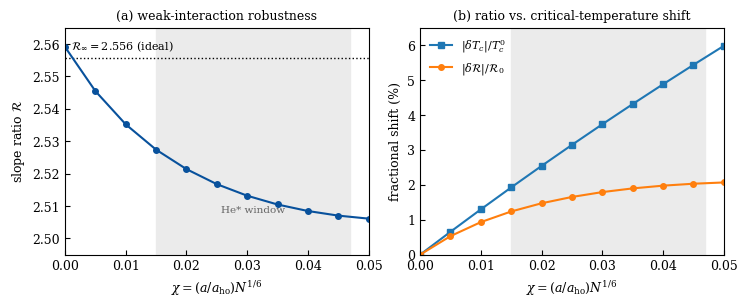

In [ ]:
#!/usr/bin/env python3
"""
Self-contained: HF-LDA weak-interaction robustness of the TOA cusp ratio + figure.
No external imports beyond numpy / scipy / mpmath / matplotlib. Runs in a notebook cell.

Panel (a): slope ratio R(chi) vs ideal 2.5556.
Panel (b): |dR/R0| (percent level) vs |dTc/Tc0| (several percent).
"""
import numpy as np, mpmath as mp
from math import factorial
from scipy.optimize import brentq
from scipy.integrate import simpson
import matplotlib as mpl, matplotlib.pyplot as plt

mp.mp.dps = 25
z3=float(mp.zeta(3)); z4=float(mp.zeta(4)); g32_1=float(mp.zeta(1.5)); SQPI=np.sqrt(np.pi)
Gm12=float(mp.gamma(-0.5)); Gm32=float(mp.gamma(-1.5))
zc32=[float(mp.zeta(1.5-k)) for k in range(8)]
zc52=[float(mp.zeta(2.5-k)) for k in range(8)]

def g32(a):                                  # Li_{3/2}(e^{-a}) via Robinson expansion
    a=np.asarray(a,float); o=np.empty_like(a); s=a<1.2; x=a[s]
    o[s]=Gm12*np.sqrt(x)+sum(zc32[k]*(-x)**k/factorial(k) for k in range(8))
    y=a[~s]; k=np.arange(1,200); o[~s]=np.sum(np.exp(-np.outer(y,k))/k**1.5,axis=1); return o
def g52(a):                                  # Li_{5/2}(e^{-a})
    a=np.asarray(a,float); o=np.empty_like(a); s=a<1.2; x=a[s]
    o[s]=Gm32*x**1.5+sum(zc52[k]*(-x)**k/factorial(k) for k in range(8))
    y=a[~s]; k=np.arange(1,200); o[~s]=np.sum(np.exp(-np.outer(y,k))/k**2.5,axis=1); return o

XI=np.linspace(0,7.5,4000)
def simp(y): return simpson(y,XI)
def kappa_c_of_chi(chi): return 4*chi/(np.sqrt(2*np.pi)*z3**(1/6))

def alpha_field(mu_bar,kappa):               # HF self-consistency by monotone bisection
    base=XI**2-mu_bar
    lo=np.full_like(XI,1e-13); hi=np.maximum(base,0.0)+kappa*g32_1+1e-9
    for _ in range(90):
        mid=0.5*(lo+hi); F=mid-base-kappa*g32(mid)
        hi=np.where(F>0,mid,hi); lo=np.where(F>0,lo,mid)
    return 0.5*(lo+hi)
def sV2(al,th): return 4*th**4/(SQPI*z3)*simp(XI**2*g52(al))
def above(kc,th):
    k=kc*np.sqrt(th)
    mb=brentq(lambda m: th**3*simp(XI**2*g32(alpha_field(m,k)))-SQPI*z3/4,-40,k*g32_1-1e-12,rtol=1e-12)
    return sV2(alpha_field(mb,k),th)
def below(kc,th):
    k=kc*np.sqrt(th); return sV2(alpha_field(k*g32_1,k),th)
def theta_c(kc):
    return brentq(lambda t:(lambda k:t**3*simp(XI**2*g32(alpha_field(k*g32_1,k)))-SQPI*z3/4)(kc*np.sqrt(t)),0.7,1.1,rtol=1e-12)
def cusp(kc,e=1e-3):                          # Richardson one-sided slopes -> R
    tc=theta_c(kc); k=kc*np.sqrt(tc); sVc=sV2(alpha_field(k*g32_1,k),tc)
    sa=2*((above(kc,tc+e)-sVc)/e)-((above(kc,tc+2*e)-sVc)/(2*e))
    sb=2*((sVc-below(kc,tc-e))/e)-((sVc-below(kc,tc-2*e))/(2*e))
    return tc,sb,sa,sb/sa

# ---- compute grid ----
chi=np.linspace(0.0,0.05,11); R=np.empty_like(chi); tc=np.empty_like(chi)
for i,c in enumerate(chi):
    th,sb,sa,ratio=cusp(kappa_c_of_chi(c) if c>0 else 0.0); R[i]=ratio; tc[i]=th
Rid=R[0]

# ---- plot ----
mpl.rcParams.update({"font.family":"serif","font.size":9,"mathtext.fontset":"dejavuserif",
    "xtick.direction":"in","ytick.direction":"in","axes.linewidth":0.8})
fig,(a1,a2)=plt.subplots(1,2,figsize=(7.4,3.0))
for ax in (a1,a2): ax.axvspan(0.015,0.047,color="0.92",zorder=0)
a1.axhline(2.5556,ls=":",color="k",lw=1.0)
a1.plot(chi,R,"-o",color="#08519c",ms=4,lw=1.5)
a1.text(0.001,2.557,r"$\mathcal{R}_\infty=2.556$ (ideal)",fontsize=8,va="bottom")
a1.text(0.031,2.508,"He* window",color="0.4",fontsize=7.5,ha="center")
a1.set_xlabel(r"$\chi=(a/a_{\rm ho})N^{1/6}$"); a1.set_ylabel(r"slope ratio $\mathcal{R}$")
a1.set_xlim(0,0.05); a1.set_ylim(2.495,2.565); a1.set_title("(a) weak-interaction robustness",fontsize=9)
a2.plot(chi,100*np.abs(tc-1),"-s",color="#1f77b4",ms=4,lw=1.5,label=r"$|\delta T_c|/T_c^0$")
a2.plot(chi,100*np.abs(R/Rid-1),"-o",color="#ff7f0e",ms=4,lw=1.5,label=r"$|\delta\mathcal{R}|/\mathcal{R}_0$")
a2.set_xlabel(r"$\chi=(a/a_{\rm ho})N^{1/6}$"); a2.set_ylabel("fractional shift (%)")
a2.set_xlim(0,0.05); a2.set_ylim(0,6.5); a2.legend(fontsize=8,frameon=False,loc="upper left")
a2.set_title("(b) ratio vs. critical-temperature shift",fontsize=9)
fig.tight_layout(pad=0.5)
fig.savefig("fig_interaction_robust.pdf",bbox_inches="tight")
fig.savefig("fig_interaction_robust.png",bbox_inches="tight",dpi=150)
print("wrote fig_interaction_robust.pdf / .png")
print(f"  R(0.05)/R0-1 = {100*(R[-1]/Rid-1):+.2f}%   dTc(0.05)/Tc0 = {100*(tc[-1]-1):+.2f}%")

# Old codes



  EXTRACTION ε*(N) — scaling FSS
  N values: [100.0, 1000.0, 10000.0, 100000.0, 1000000.0]
  Plage ε   : [0.00050, 0.05000] (20 pts log)
  N=10⁶ utilise une grille plus grossière (10 pts) pour gagner du temps

  Analytic Tc estimate: 97.2 nK

─ N=1e+02 | Tc=69.08 nK | 20 ε ─
  Point central T=Tc : <T>=319.27382 ms  ΔT=0.99666 ms  (0.0s)
    ε=0.00050  r_<T>=1.001  r_ΔT=1.000  (0.0s)
    ε=0.00064  r_<T>=1.001  r_ΔT=1.001  (0.0s)
    ε=0.00081  r_<T>=1.002  r_ΔT=1.001  (0.0s)
    ε=0.00103  r_<T>=1.002  r_ΔT=1.001  (0.0s)
    ε=0.00132  r_<T>=1.003  r_ΔT=1.001  (0.0s)
    ε=0.00168  r_<T>=1.003  r_ΔT=1.001  (0.0s)
    ε=0.00214  r_<T>=1.004  r_ΔT=1.002  (0.0s)
    ε=0.00273  r_<T>=1.006  r_ΔT=1.002  (0.0s)
    ε=0.00348  r_<T>=1.007  r_ΔT=1.003  (0.0s)
    ε=0.00443  r_<T>=1.009  r_ΔT=1.004  (0.0s)
    ε=0.00564  r_<T>=1.012  r_ΔT=1.005  (0.0s)
    ε=0.00719  r_<T>=1.015  r_ΔT=1.006  (0.0s)
    ε=0.00916  r_<T>=1.019  r_ΔT=1.007  (0.0s)
    ε=0.01168  r_<T>=1.025  r_ΔT=1.009  (0.0s)
  

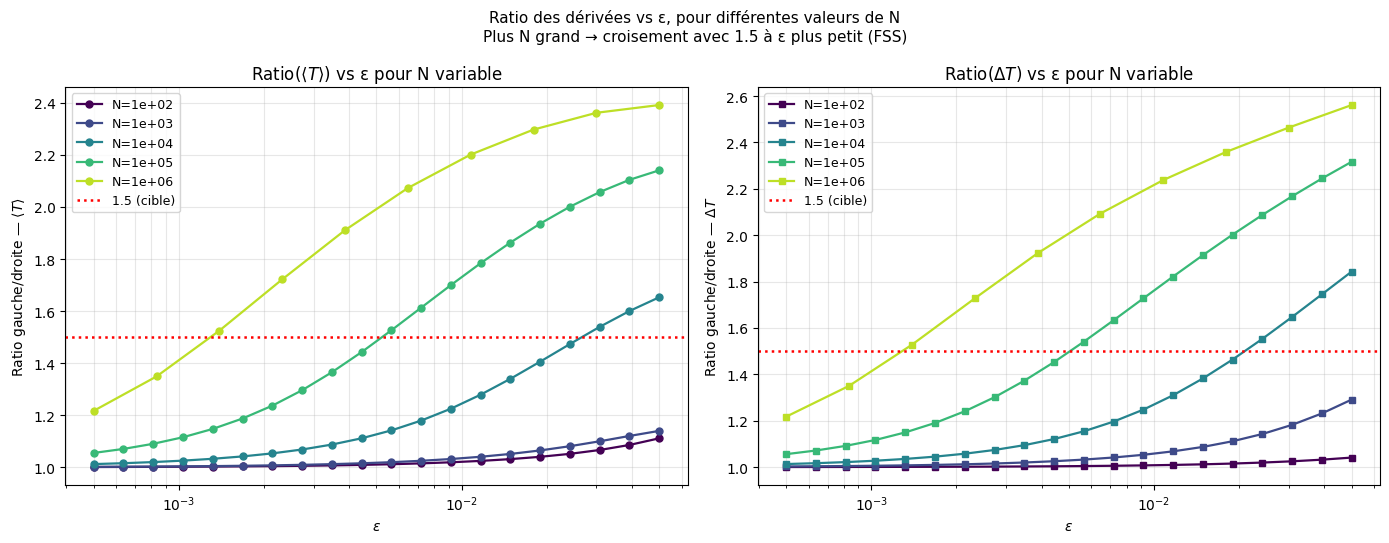

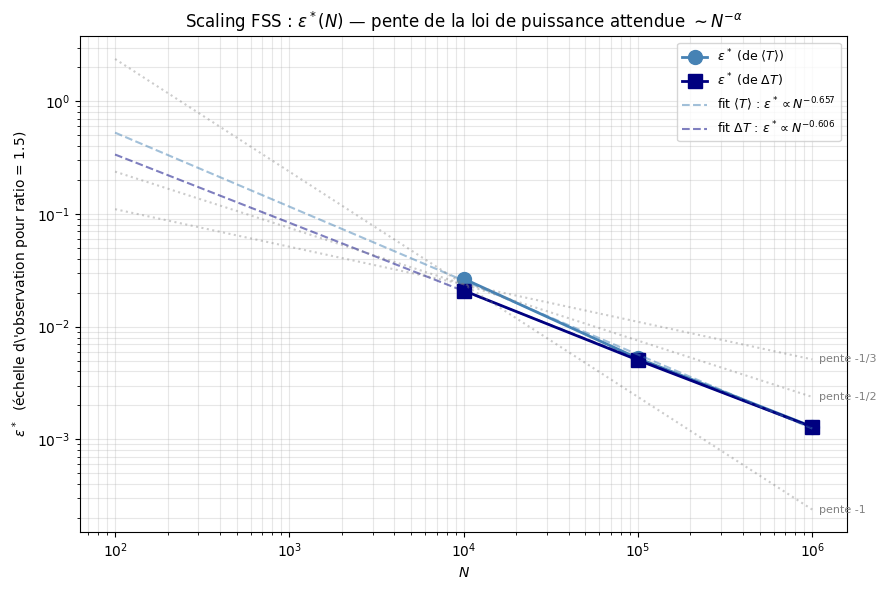


DONE.
  - CSV : fss_ratio_curves.csv, fss_eps_star_vs_N.csv
  - figures : fss_ratio_curves.png, fss_eps_star_scaling.png

  Exposant FSS extrait :
    α (de <T>) = 0.657
    α (de ΔT)  = 0.606


In [ ]:
#!/usr/bin/env python3
"""
================================================================================
 CELL 6 — Extraction de ε*(N) et scaling de taille finie (FSS)
================================================================================

Hypothèse : cells 1-3 (au moins 1 et 3) déjà exécutées, set_params, REF,
toa_moments, semiclassical_moments, compute_Tc disponibles.

Objectif : trouver ε*(N) défini par "ratio des dérivées gauche/droite à T_c
mesuré par différence finie sur fenêtre ±ε·Tc = 1.5".

Prédiction FSS : ε*(N) ~ N^(-α). Pour BEC dans piège harmonique on attend
typiquement α ∈ [1/3, 1]. Une droite en log-log confirmerait l'image FSS.

Stratégie :
  - Pour chaque N, balayer ε en log de 5e-4 à 5e-2 (~20 points)
  - Calculer ratio_DT(ε) et ratio_<T>(ε) à T=Tc
  - Optimisation : <T>(Tc) et ΔT(Tc) sont calculés une seule fois par N,
    réutilisés pour tous les ε
  - Interpoler ε*(N) tel que ratio = 1.5
  - Plot ratio vs ε (5 courbes, une par N) et ε* vs N en log-log
"""

import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration
N_VALUES = [1e2, 1e3, 1e4, 1e5, 1e6]

# Plage d'ε en log : plus de points pour bien interpoler
EPS_FINE = np.logspace(np.log10(5e-4), np.log10(5e-2), 20)
EPS_COARSE = np.logspace(np.log10(5e-4), np.log10(5e-2), 10)  # pour N=10⁶

print(f"\n{'='*70}\n  EXTRACTION ε*(N) — scaling FSS\n{'='*70}")
print(f"  N values: {N_VALUES}")
print(f"  Plage ε   : [{EPS_FINE[0]:.5f}, {EPS_FINE[-1]:.5f}] (20 pts log)")
print(f"  N=10⁶ utilise une grille plus grossière (10 pts) pour gagner du temps\n")


def ratios_at_eps(Tc, mean_C, std_C, eps):
    """
    Calcule (ratio_<T>, ratio_ΔT) pour un eps donné, en réutilisant
    mean_C/std_C déjà calculés au point T=Tc.
    """
    dT = eps * Tc
    mean_L, std_L, _, _, _ = toa_moments(Tc - dT, Tc, N_target)
    mean_R, std_R, _, _, _ = toa_moments(Tc + dT, Tc, N_target)
    sl_m = (mean_C - mean_L) / dT;  sr_m = (mean_R - mean_C) / dT
    sl_s = (std_C  - std_L)  / dT;  sr_s = (std_R  - std_C)  / dT
    r_m = sl_m / sr_m if sr_m != 0 else np.nan
    r_s = sl_s / sr_s if sr_s != 0 else np.nan
    return r_m, r_s


# Stockage : pour chaque N, on garde toute la courbe ratio vs ε
all_curves = {}   # N -> DataFrame(eps, r_mean, r_std)
eps_star  = {}    # N -> dict(eps_star_mean, eps_star_std)

t_total = time.time()

for N_val in N_VALUES:
    set_params(**REF)
    set_params(N=N_val)

    # Tc et point central
    Tc_local = compute_Tc(N_target)
    eps_grid = EPS_COARSE if N_val >= 1e6 else EPS_FINE

    print(f"\n─ N={N_val:.0e} | Tc={Tc_local*1e9:.2f} nK | {len(eps_grid)} ε ─")

    t0 = time.time()
    mean_C, std_C, _, _, _ = toa_moments(Tc_local, Tc_local, N_target)
    print(f"  Point central T=Tc : <T>={mean_C*1e3:.5f} ms  ΔT={std_C*1e3:.5f} ms  ({time.time()-t0:.1f}s)")

    # Boucle sur ε
    rows = []
    for eps in eps_grid:
        t_pt = time.time()
        try:
            r_m, r_s = ratios_at_eps(Tc_local, mean_C, std_C, eps)
            rows.append(dict(eps=eps, r_mean=r_m, r_std=r_s,
                             runtime_s=time.time()-t_pt))
            print(f"    ε={eps:.5f}  r_<T>={r_m:.3f}  r_ΔT={r_s:.3f}  ({time.time()-t_pt:.1f}s)")
        except Exception as e:
            print(f"    ε={eps:.5f}  FAILED: {e}")
            rows.append(dict(eps=eps, r_mean=np.nan, r_std=np.nan,
                             runtime_s=time.time()-t_pt))

    df = pd.DataFrame(rows).sort_values('eps').reset_index(drop=True)
    all_curves[N_val] = df

    # Extraction de ε* par interpolation : on cherche eps tel que ratio = 1.5
    # On utilise interpolation linéaire en (log eps, ratio).
    def find_eps_star(eps_arr, ratio_arr, target=1.5):
        # On part des plus petits ε (ratio < target en général) vers les plus
        # grands (ratio > target). On trouve la première traversée de target.
        mask = ~np.isnan(ratio_arr)
        eps_v   = np.array(eps_arr)[mask]
        ratio_v = np.array(ratio_arr)[mask]
        if len(eps_v) < 2:
            return np.nan
        # Cherche segments où la fonction traverse target
        for i in range(len(eps_v) - 1):
            r0, r1 = ratio_v[i], ratio_v[i+1]
            if (r0 - target) * (r1 - target) <= 0:
                # interpolation linéaire en log(eps) vs ratio
                le0, le1 = np.log(eps_v[i]), np.log(eps_v[i+1])
                if r1 == r0:
                    return eps_v[i]
                t = (target - r0) / (r1 - r0)
                return float(np.exp(le0 + t * (le1 - le0)))
        return np.nan

    eps_star_mean = find_eps_star(df['eps'].values, df['r_mean'].values)
    eps_star_std  = find_eps_star(df['eps'].values, df['r_std'].values)
    eps_star[N_val] = dict(mean=eps_star_mean, std=eps_star_std)
    print(f"  → ε*_<T> = {eps_star_mean:.5f}    ε*_ΔT = {eps_star_std:.5f}")

# Restauration
set_params(**REF)
print(f"\n  TOTAL: {time.time()-t_total:.1f} s")


# ─── Sauvegarde ───────────────────────────────────────────────────────────
all_long = []
for N_val, df in all_curves.items():
    df2 = df.copy()
    df2['N'] = N_val
    all_long.append(df2)
df_all = pd.concat(all_long, ignore_index=True)
df_all.to_csv('fss_ratio_curves.csv', index=False)

eps_star_df = pd.DataFrame([
    {'N': N, 'eps_star_mean': v['mean'], 'eps_star_std': v['std']}
    for N, v in eps_star.items()
]).sort_values('N')
eps_star_df.to_csv('fss_eps_star_vs_N.csv', index=False)
print(f"\n  ε*(N) :\n{eps_star_df.to_string(index=False)}")


# ─── Plot 1 : ratio vs ε pour chaque N (courbes superposées) ───────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cmap = plt.cm.viridis(np.linspace(0.0, 0.9, len(N_VALUES)))

for color, N_val in zip(cmap, N_VALUES):
    df = all_curves[N_val]
    axes[0].plot(df['eps'], df['r_mean'], 'o-', color=color, lw=1.6, ms=5,
                 label=f"N={N_val:.0e}")
    axes[1].plot(df['eps'], df['r_std'],  's-', color=color, lw=1.6, ms=5,
                 label=f"N={N_val:.0e}")

for ax, qty in zip(axes, [r"$\langle T \rangle$", r"$\Delta T$"]):
    ax.axhline(1.5, ls=':', color='red', lw=1.8, label='1.5 (cible)')
    ax.set_xscale('log')
    ax.set_xlabel(r'$\varepsilon$')
    ax.set_ylabel(f'Ratio gauche/droite — {qty}')
    ax.set_title(f'Ratio({qty}) vs ε pour N variable')
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=9)

fig.suptitle("Ratio des dérivées vs ε, pour différentes valeurs de N\n"
             "Plus N grand → croisement avec 1.5 à ε plus petit (FSS)", fontsize=11)
fig.tight_layout()
plt.savefig('fss_ratio_curves.png', dpi=150, bbox_inches='tight')
plt.show()


# ─── Plot 2 : ε*(N) vs N en log-log + fit FSS ──────────────────────────────
fig2, ax2 = plt.subplots(figsize=(9, 6))

N_arr     = eps_star_df['N'].values
eps_m_arr = eps_star_df['eps_star_mean'].values
eps_s_arr = eps_star_df['eps_star_std'].values

ax2.loglog(N_arr, eps_m_arr, 'o-', ms=10, lw=2, color='steelblue',
           label=r'$\varepsilon^*$ (de $\langle T \rangle$)')
ax2.loglog(N_arr, eps_s_arr, 's-', ms=10, lw=2, color='navy',
           label=r'$\varepsilon^*$ (de $\Delta T$)')

# Fit en loi de puissance ε* = A·N^(-α) sur les points valides
def fit_power(N, eps):
    mask = ~np.isnan(eps) & (eps > 0)
    if mask.sum() < 2: return None, None
    logN, logE = np.log(N[mask]), np.log(eps[mask])
    a, b = np.polyfit(logN, logE, 1)
    return a, b   # logE = a·logN + b   ⇒  ε ~ exp(b) · N^a (a < 0)

a_m, b_m = fit_power(N_arr, eps_m_arr)
a_s, b_s = fit_power(N_arr, eps_s_arr)

if a_m is not None:
    Ng = np.logspace(np.log10(N_arr.min()), np.log10(N_arr.max()), 50)
    ax2.loglog(Ng, np.exp(b_m) * Ng**a_m, '--', color='steelblue', alpha=0.5,
               label=fr'fit $\langle T\rangle$ : $\varepsilon^* \propto N^{{{a_m:.3f}}}$')

if a_s is not None:
    Ng = np.logspace(np.log10(N_arr.min()), np.log10(N_arr.max()), 50)
    ax2.loglog(Ng, np.exp(b_s) * Ng**a_s, '--', color='navy', alpha=0.5,
               label=fr'fit $\Delta T$ : $\varepsilon^* \propto N^{{{a_s:.3f}}}$')

# Lignes guides : pentes -1/3, -1/2, -1
N_ref = N_arr[len(N_arr)//2]
eps_ref = np.nanmean([eps_m_arr[len(N_arr)//2], eps_s_arr[len(N_arr)//2]])
for slope, label in [(-1/3, '-1/3'), (-1/2, '-1/2'), (-1, '-1')]:
    Ng = np.logspace(np.log10(N_arr.min()), np.log10(N_arr.max()), 50)
    eps_g = eps_ref * (Ng / N_ref)**slope
    ax2.loglog(Ng, eps_g, ':', color='gray', alpha=0.4)
    # Annotation à droite
    ax2.annotate(f'pente {label}', xy=(Ng[-1], eps_g[-1]),
                 fontsize=8, color='gray',
                 xytext=(5, 0), textcoords='offset points', va='center')

ax2.set_xlabel(r'$N$')
ax2.set_ylabel(r'$\varepsilon^*$  (échelle d\'observation pour ratio = 1.5)')
ax2.set_title(r'Scaling FSS : $\varepsilon^*(N)$ — pente de la loi de puissance attendue $\sim N^{-\alpha}$')
ax2.grid(alpha=0.3, which='both')
ax2.legend(fontsize=9, loc='best')

fig2.tight_layout()
plt.savefig('fss_eps_star_scaling.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDONE.")
print("  - CSV : fss_ratio_curves.csv, fss_eps_star_vs_N.csv")
print("  - figures : fss_ratio_curves.png, fss_eps_star_scaling.png")
print(f"\n  Exposant FSS extrait :")
print(f"    α (de <T>) = {-a_m if a_m else 'n/a':.3f}")
print(f"    α (de ΔT)  = {-a_s if a_s else 'n/a':.3f}")

  Analytic Tc estimate: 2095.1 nK

  ZOOM sur Tc à N=1e6
  Tc = 2071.26 nK
  Plage : [1967.70, 2174.82] nK, 81 points
  Pas : 2589.07 pK

  [  1/81]  T/Tc=0.9500  <T>=319.32657 ms  ΔT=5.71398 ms  norm/N=0.99987  (29.8s)
  [ 11/81]  T/Tc=0.9625  <T>=319.32929 ms  ΔT=5.86409 ms  norm/N=0.99985  (264.0s)
  [ 21/81]  T/Tc=0.9750  <T>=319.33212 ms  ΔT=6.01593 ms  norm/N=0.99992  (437.1s)
  [ 31/81]  T/Tc=0.9875  <T>=319.33505 ms  ΔT=6.16972 ms  norm/N=0.99997  (549.7s)
  [ 41/81]  T/Tc=1.0000  <T>=319.33805 ms  ΔT=6.32291 ms  norm/N=0.99999  (594.1s)
  [ 51/81]  T/Tc=1.0125  <T>=319.33939 ms  ΔT=6.39026 ms  norm/N=0.99999  (596.6s)
  [ 61/81]  T/Tc=1.0250  <T>=319.34058 ms  ΔT=6.44934 ms  norm/N=0.99999  (598.9s)
  [ 71/81]  T/Tc=1.0375  <T>=319.34173 ms  ΔT=6.50593 ms  norm/N=0.99999  (601.4s)
  [ 81/81]  T/Tc=1.0500  <T>=319.34285 ms  ΔT=6.56068 ms  norm/N=0.99999  (603.6s)

  Total: 603.6 s


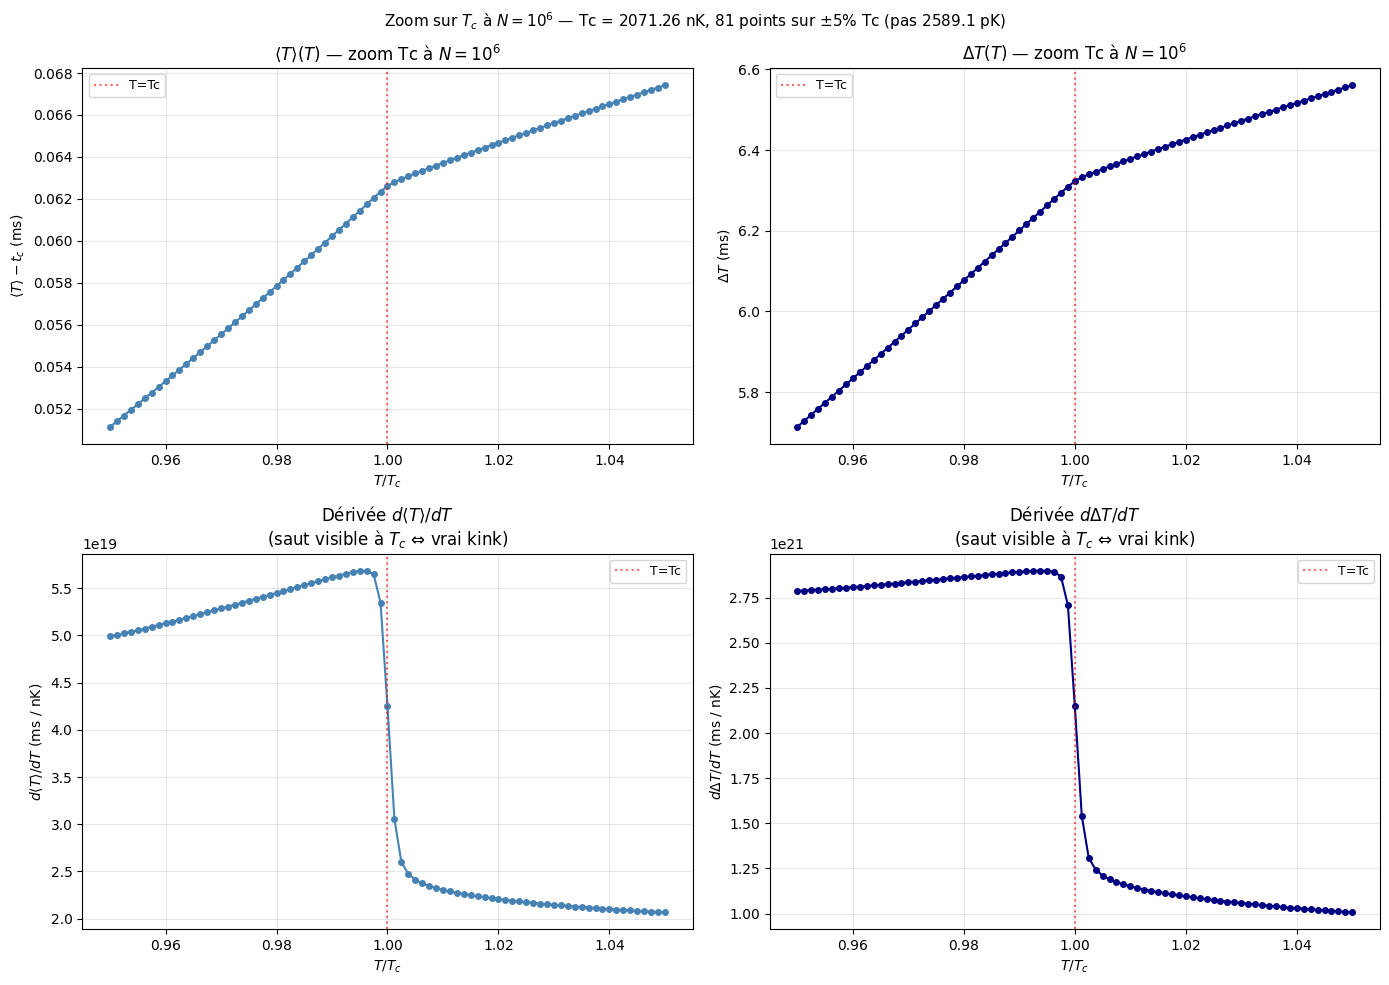


Estimation du ratio à différentes échelles fenêtre :
  centre: i=40, T=1.0000·Tc

  fenêtre ±k·dT  |  ε équiv  |  ratio ΔT  |  ratio <T>
  ─────────────────────────────────────────────────────
  ± 1·dT       |  0.00125  |      1.487  |      1.485
  ± 2·dT       |  0.00250  |      1.756  |      1.750
  ± 5·dT       |  0.00625  |      2.083  |      2.063
  ±10·dT       |  0.01250  |      2.275  |      2.232
  ±20·dT       |  0.02500  |      2.428  |      2.343
  ±40·dT       |  0.05000  |      2.561  |      2.392

DONE.
  - CSV : zoom_Tc_N1e6.csv
  - figure : zoom_Tc_N1e6.png


In [ ]:
#!/usr/bin/env python3
"""
================================================================================
 CELL 5 — Zoom sur Tc à N=10⁶
================================================================================

Objectif : trancher si ⟨T⟩(T) et ΔT(T) ont un vrai kink à T_c (signature
d'un saut dans la dérivée → ratio 1.5 mathématique) ou si c'est un
crossover lisse (fonctions C¹, ratio observé dépend de l'échelle ε).

On balaye T sur ±5% autour de Tc avec ~80 points et on trace :
  - <T>(T) et ΔT(T) (les fonctions elles-mêmes)
  - leurs dérivées numériques d/dT (par différences finies centrées)

Si vrai kink → discontinuité visible dans la dérivée à T=Tc.
Si lisse    → dérivée continue, juste un point d'inflexion.
"""

import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration : N=10⁶
set_params(**REF)
set_params(N=1e6)

Tc_local = compute_Tc(N_target)
print(f"\n{'='*70}\n  ZOOM sur Tc à N=1e6\n{'='*70}")
print(f"  Tc = {Tc_local*1e9:.2f} nK")

# Grille de température : ±5% de Tc, 81 points (impair pour passer par Tc)
delta_rel = 0.05
n_zoom    = 81
T_zoom    = np.linspace(Tc_local*(1 - delta_rel), Tc_local*(1 + delta_rel), n_zoom)
print(f"  Plage : [{T_zoom[0]*1e9:.2f}, {T_zoom[-1]*1e9:.2f}] nK, {n_zoom} points")
print(f"  Pas : {(T_zoom[1]-T_zoom[0])*1e12:.2f} pK\n")

# Sweep
mean_arr = np.zeros(n_zoom)
std_arr  = np.zeros(n_zoom)
norm_arr = np.zeros(n_zoom)

t0 = time.time()
for i, T in enumerate(T_zoom):
    mT, sT, nr, _, _ = toa_moments(float(T), Tc_local, N_target)
    mean_arr[i] = mT
    std_arr[i]  = sT
    norm_arr[i] = nr
    if i % 10 == 0 or i == n_zoom - 1:
        print(f"  [{i+1:>3}/{n_zoom}]  T/Tc={T/Tc_local:.4f}  "
              f"<T>={mT*1e3:.5f} ms  ΔT={sT*1e3:.5f} ms  "
              f"norm/N={nr/N_target:.5f}  ({time.time()-t0:.1f}s)")

print(f"\n  Total: {time.time()-t0:.1f} s")

# Dérivées numériques (différences finies centrées)
dT = T_zoom[1] - T_zoom[0]
dmean_dT = np.gradient(mean_arr, dT)
dstd_dT  = np.gradient(std_arr,  dT)

# Sauvegarde
df_zoom = pd.DataFrame({
    'T': T_zoom, 'T_over_Tc': T_zoom/Tc_local,
    'mean_TOA': mean_arr, 'std_TOA': std_arr,
    'd_mean_dT': dmean_dT, 'd_std_dT': dstd_dT,
    'norm_J_over_N': norm_arr/N_target,
})
df_zoom.to_csv('zoom_Tc_N1e6.csv', index=False)

# Restauration
set_params(**REF)

# ─── Plot 4 panels ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

x = T_zoom / Tc_local

# Top-left : <T>(T)
ax = axes[0, 0]
ax.plot(x, (mean_arr - tc)*1e3, 'o-', ms=4, lw=1.5, color='steelblue')
ax.axvline(1.0, ls=':', color='red', alpha=0.6, label='T=Tc')
ax.set_xlabel(r'$T/T_c$')
ax.set_ylabel(r'$\langle T \rangle - t_c$ (ms)')
ax.set_title(r'$\langle T \rangle(T)$ — zoom Tc à $N=10^6$')
ax.grid(alpha=0.3); ax.legend(fontsize=9)

# Top-right : ΔT(T)
ax = axes[0, 1]
ax.plot(x, std_arr*1e3, 'o-', ms=4, lw=1.5, color='navy')
ax.axvline(1.0, ls=':', color='red', alpha=0.6, label='T=Tc')
ax.set_xlabel(r'$T/T_c$')
ax.set_ylabel(r'$\Delta T$ (ms)')
ax.set_title(r'$\Delta T(T)$ — zoom Tc à $N=10^6$')
ax.grid(alpha=0.3); ax.legend(fontsize=9)

# Bottom-left : d<T>/dT
ax = axes[1, 0]
ax.plot(x, dmean_dT*1e3/Tc_local*1e9, 'o-', ms=4, lw=1.5, color='steelblue')
ax.axvline(1.0, ls=':', color='red', alpha=0.6, label='T=Tc')
ax.set_xlabel(r'$T/T_c$')
ax.set_ylabel(r'$d\langle T \rangle / dT$ (ms / nK)')
ax.set_title(r'Dérivée $d\langle T \rangle / dT$' '\n'
             r'(saut visible à $T_c$ ⇔ vrai kink)')
ax.grid(alpha=0.3); ax.legend(fontsize=9)

# Bottom-right : dΔT/dT
ax = axes[1, 1]
ax.plot(x, dstd_dT*1e3/Tc_local*1e9, 'o-', ms=4, lw=1.5, color='navy')
ax.axvline(1.0, ls=':', color='red', alpha=0.6, label='T=Tc')
ax.set_xlabel(r'$T/T_c$')
ax.set_ylabel(r'$d\Delta T / dT$ (ms / nK)')
ax.set_title(r'Dérivée $d\Delta T / dT$' '\n'
             r'(saut visible à $T_c$ ⇔ vrai kink)')
ax.grid(alpha=0.3); ax.legend(fontsize=9)

fig.suptitle(
    f"Zoom sur $T_c$ à $N=10^6$ — Tc = {Tc_local*1e9:.2f} nK, "
    f"81 points sur ±5% Tc (pas {(T_zoom[1]-T_zoom[0])*1e12:.1f} pK)",
    fontsize=11
)
fig.tight_layout()
plt.savefig('zoom_Tc_N1e6.png', dpi=150, bbox_inches='tight')
plt.show()

# Estimation visuelle du ratio à différentes échelles
# Calculons le ratio gauche/droite à des fenêtres ±k·dT autour du centre
print("\nEstimation du ratio à différentes échelles fenêtre :")
i_c = n_zoom // 2  # index de Tc
print(f"  centre: i={i_c}, T={T_zoom[i_c]/Tc_local:.4f}·Tc")
print(f"\n  fenêtre ±k·dT  |  ε équiv  |  ratio ΔT  |  ratio <T>")
print(f"  ─────────────────────────────────────────────────────")
for k in [1, 2, 5, 10, 20, 40]:
    if i_c - k < 0 or i_c + k >= n_zoom: continue
    eps_eq = k * dT / Tc_local
    sl_m = (mean_arr[i_c]   - mean_arr[i_c-k]) / (k*dT)
    sr_m = (mean_arr[i_c+k] - mean_arr[i_c])   / (k*dT)
    sl_s = (std_arr [i_c]   - std_arr [i_c-k]) / (k*dT)
    sr_s = (std_arr [i_c+k] - std_arr [i_c])   / (k*dT)
    r_m = sl_m / sr_m if sr_m != 0 else np.nan
    r_s = sl_s / sr_s if sr_s != 0 else np.nan
    print(f"  ±{k:>2}·dT       |  {eps_eq:.5f}  |  {r_s:>9.3f}  |  {r_m:>9.3f}")

print("\nDONE.")
print("  - CSV : zoom_Tc_N1e6.csv")
print("  - figure : zoom_Tc_N1e6.png")


  EXTRAPOLATION ε à N=1e6
  Tous autres paramètres : REF = {'m': 6.64e-27, 'g': 9.81, 'H': 0.5, 'omega_z': 628.3185307179587, 'omega_x': 6283.185307179586, 'omega_y': 6283.185307179586, 'N': 100000.0}

  Analytic Tc estimate: 2095.1 nK
  ε=0.00500  |  r_<T>_ex= 1.996  r_DT_ex= 2.011  r_<T>_sc= 1.698  r_DT_sc= 1.711  (14.0s)
  Analytic Tc estimate: 2095.1 nK
  ε=0.00200  |  r_<T>_ex= 1.664  r_DT_ex= 1.669  r_<T>_sc= 1.634  r_DT_sc= 1.639  (4.8s)
  Analytic Tc estimate: 2095.1 nK
  ε=0.00100  |  r_<T>_ex= 1.407  r_DT_ex= 1.409  r_<T>_sc= 1.599  r_DT_sc= 1.601  (4.3s)
  Analytic Tc estimate: 2095.1 nK
  ε=0.00050  |  r_<T>_ex= 1.217  r_DT_ex= 1.217  r_<T>_sc= 1.572  r_DT_sc= 1.574  (4.9s)
  Analytic Tc estimate: 2095.1 nK
  ε=0.00020  |  r_<T>_ex= 1.087  r_DT_ex= 1.087  r_<T>_sc= 1.548  r_DT_sc= 1.549  (3.6s)
  Analytic Tc estimate: 2095.1 nK
  ε=0.00010  |  r_<T>_ex= 1.044  r_DT_ex= 1.044  r_<T>_sc= 1.534  r_DT_sc= 1.534  (3.7s)

  Total time: 35.3 s


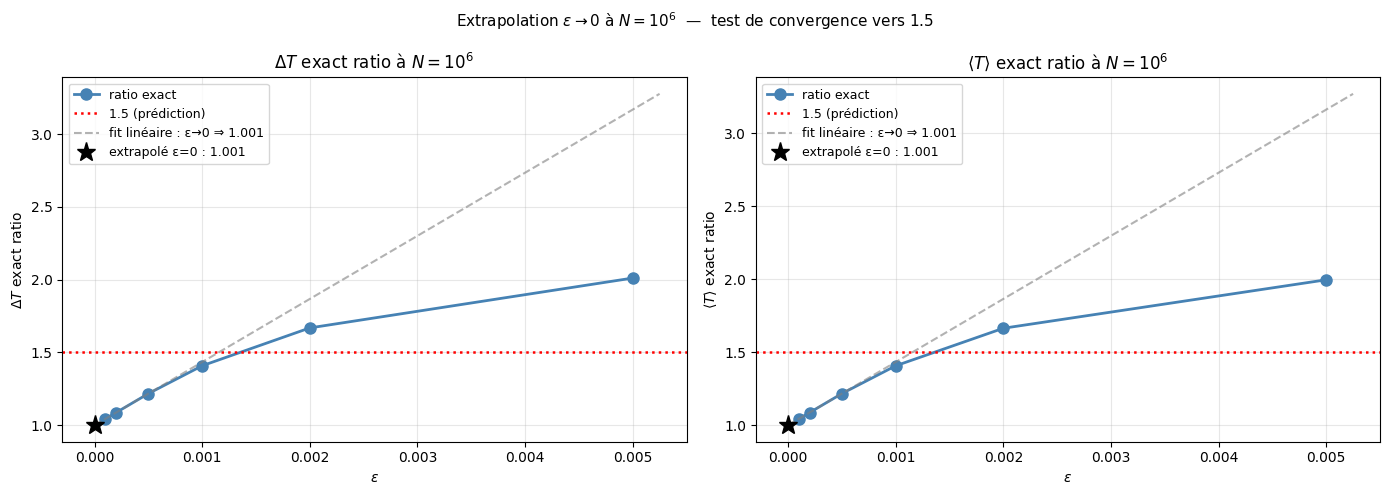


DONE.
  - CSV : extrapolation_eps_N1e6.csv
  - figure : extrapolation_eps_N1e6.png


In [ ]:
#!/usr/bin/env python3
"""
================================================================================
 CELL 4 — Extrapolation ε → 0 à N=10⁶ (test de convergence vers 1.5)
================================================================================

Hypothèse : cells 1-3 déjà exécutées. On réutilise set_params, REF,
compute_ratios_at_Tc, et les fonctions de la cell 1.

Objectif : à N=10⁶ (le plus grand de notre scan), faire converger ε vers 0
pour voir si le ratio extrapolé tend vers 1.5 ou plafonne ailleurs.

Si la limite est ≈ 1.5 → effet de taille finie pur, prédiction de Mathieu
confirmée à la limite thermodynamique.
Si la limite plafonne ailleurs → autre source de finitude à comprendre.
"""

import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration : N=10⁶, autres paramètres = REF
set_params(**REF)
set_params(N=1e6)

# Plage d'ε décroissante
EPS_LIST = [0.005, 0.002, 0.001, 0.0005, 0.0002, 0.0001]

print(f"\n{'='*70}\n  EXTRAPOLATION ε à N=1e6\n{'='*70}")
print(f"  Tous autres paramètres : REF = {REF}\n")

rows = []
t0 = time.time()
for eps in EPS_LIST:
    t_pt = time.time()
    res = compute_ratios_at_Tc(epsilon=eps, verbose=False)
    res['epsilon']   = eps
    res['runtime_s'] = time.time() - t_pt
    rows.append(res)
    print(f"  ε={eps:.5f}  |  "
          f"r_<T>_ex={res['r_mean_ex']:>6.3f}  r_DT_ex={res['r_std_ex']:>6.3f}  "
          f"r_<T>_sc={res['r_mean_sc']:>6.3f}  r_DT_sc={res['r_std_sc']:>6.3f}  "
          f"({res['runtime_s']:.1f}s)")

df_extrap = pd.DataFrame(rows)
print(f"\n  Total time: {time.time() - t0:.1f} s")

# Restauration
set_params(**REF)

# Sauvegarde
df_extrap.to_csv('extrapolation_eps_N1e6.csv', index=False)

# ─── Plot : ratio vs ε en log-log, avec fit linéaire optionnel ─────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

eps_arr = df_extrap['epsilon'].values

for ax, qty, ylabel in zip(
        axes,
        ['r_std_ex', 'r_mean_ex'],
        [r'$\Delta T$ exact ratio', r'$\langle T \rangle$ exact ratio']):

    y = df_extrap[qty].values

    ax.plot(eps_arr, y, 'o-', lw=2, ms=8, color='steelblue',
            label='ratio exact')
    ax.axhline(1.5, ls=':', color='red', lw=1.8, label='1.5 (prédiction)')

    # Extrapolation linéaire en ε (les deux points les plus petits)
    if len(eps_arr) >= 2 and not np.isnan(y).any():
        # Fit linéaire sur les 3 plus petits ε
        idx = np.argsort(eps_arr)[:3]
        slope, intercept = np.polyfit(eps_arr[idx], y[idx], 1)
        eps_fit = np.linspace(0, max(eps_arr)*1.05, 100)
        y_fit = slope * eps_fit + intercept
        ax.plot(eps_fit, y_fit, '--', color='gray', alpha=0.6,
                label=f'fit linéaire : ε→0 ⇒ {intercept:.3f}')
        ax.plot([0], [intercept], 'k*', ms=14,
                label=f'extrapolé ε=0 : {intercept:.3f}')

    ax.set_xlabel(r'$\varepsilon$')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} à $N=10^6$')
    ax.set_xlim(-0.0003, max(eps_arr)*1.1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9, loc='best')

fig.suptitle(r"Extrapolation $\varepsilon \to 0$ à $N=10^6$  —  test de convergence vers 1.5",
             fontsize=11)
fig.tight_layout()
plt.savefig('extrapolation_eps_N1e6.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDONE.")
print("  - CSV : extrapolation_eps_N1e6.csv")
print("  - figure : extrapolation_eps_N1e6.png")

# Universal 1.5


  SCAN ε×N (nombre de particules): 5 pts × 6 ε = 30 configs
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0500  r_<T>_ex= 1.111  r_DT_ex= 1.041  r_<T>_sc= 1.920  r_DT_sc= 2.066  (0.1s)
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0200  r_<T>_ex= 1.043  r_DT_ex= 1.016  r_<T>_sc= 1.833  r_DT_sc= 1.890  (0.2s)
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0100  r_<T>_ex= 1.021  r_DT_ex= 1.008  r_<T>_sc= 1.761  r_DT_sc= 1.788  (0.2s)
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0050  r_<T>_ex= 1.010  r_DT_ex= 1.004  r_<T>_sc= 1.698  r_DT_sc= 1.711  (0.3s)
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0020  r_<T>_ex= 1.004  r_DT_ex= 1.002  r_<T>_sc= 1.634  r_DT_sc= 1.639  (0.3s)
  Analytic Tc estimate: 97.2 nK
  [ 1/5] N=         100  ε=0.0010  r_<T>_ex= 1.002  r_DT_ex= 1.001  r_<T>_sc= 1.599  r_DT_sc= 1.601  (0.2s)
  Analytic Tc estimate: 209.5 nK
  [ 2/5] N=        1000  ε=0.0500  r_<T>_ex= 1.140  r_DT_ex= 1.291

/tmp/ipykernel_6958/112721956.py:450: UserWarning: Glyph 8810 (\N{MUCH LESS-THAN}) missing from font(s) DejaVu Sans Mono.
  fig.tight_layout()
/tmp/ipykernel_6958/112721956.py:451: UserWarning: Glyph 8810 (\N{MUCH LESS-THAN}) missing from font(s) DejaVu Sans Mono.
  plt.savefig('toa_universality_scan.png', dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8810 (\N{MUCH LESS-THAN}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


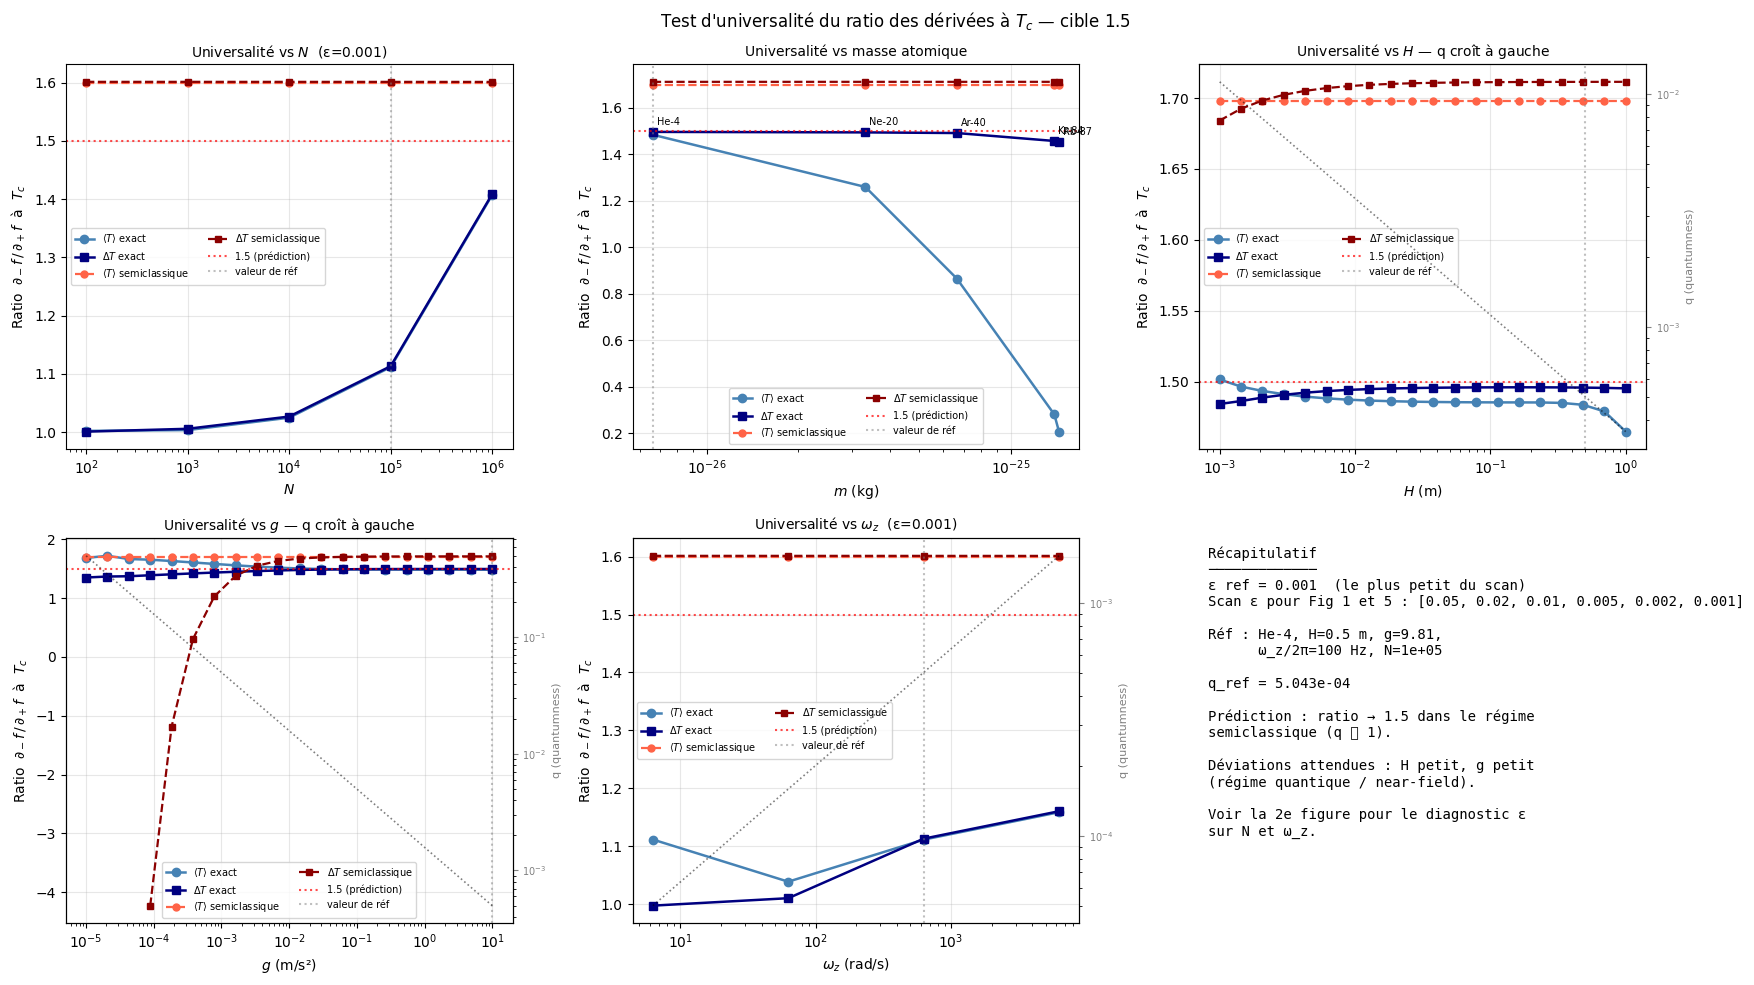

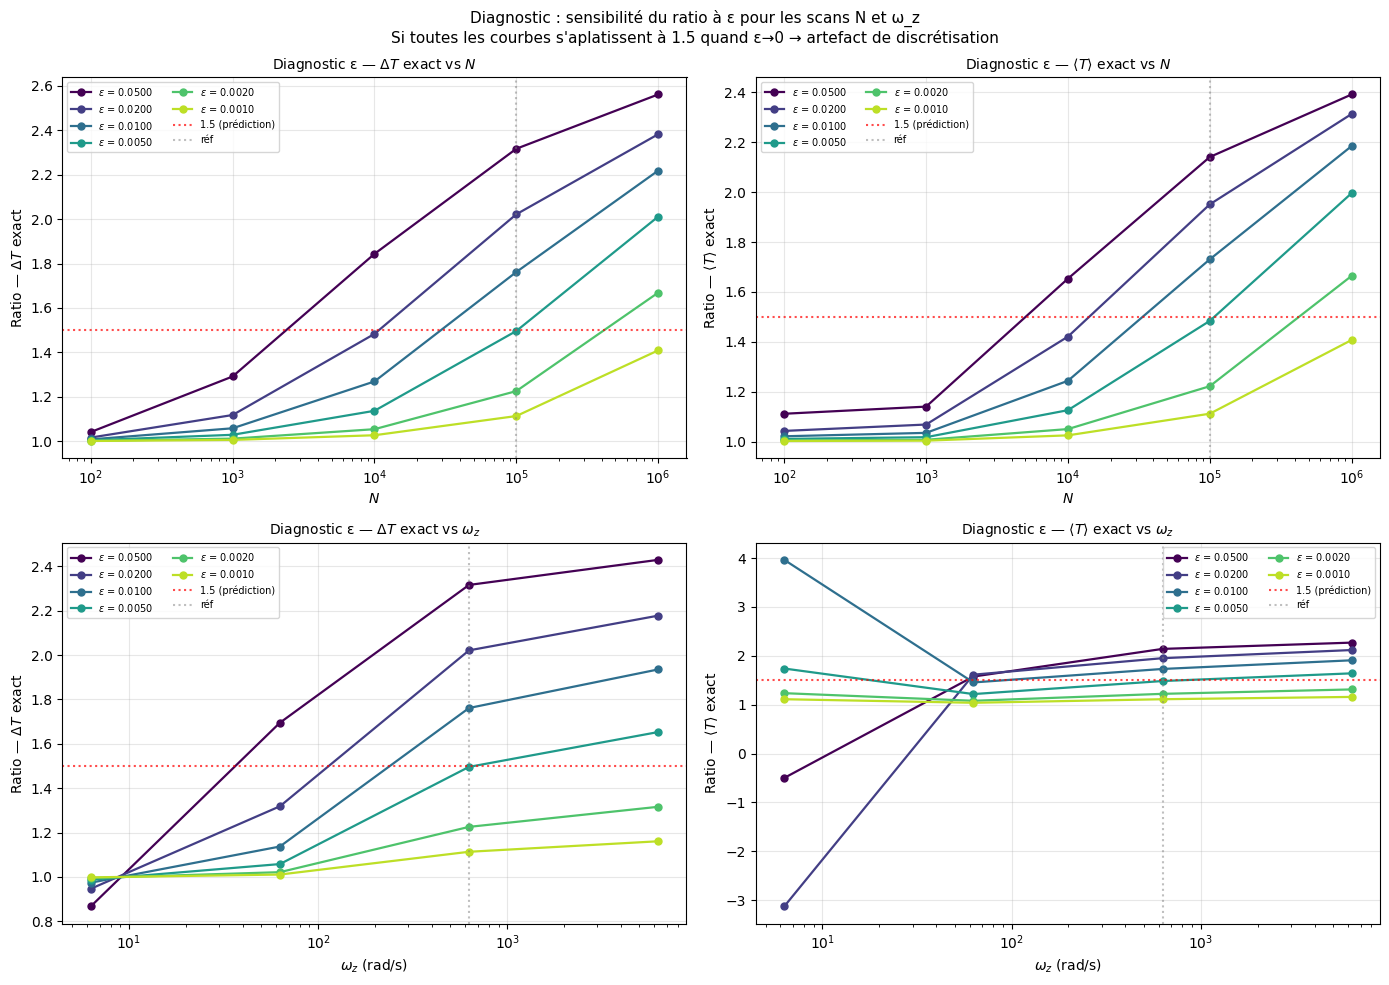


DONE. Outputs:
  - 5 CSV : universality_scan_{N,mass,H,g,omega_z}.csv
  - figure principale : toa_universality_scan.png
  - figure diagnostic ε : toa_universality_diagnostic_eps.png


In [ ]:
#!/usr/bin/env python3
"""
================================================================================
 CELL 3 — Scan d'universalité du ratio des dérivées à T_c
================================================================================

Hypothèse : les cells 1 et 2 ont déjà été exécutées dans le même notebook.
On s'appuie sur les fonctions/globals définies dans la cell 1 :

    kB, hbar, math, np, plt, simpson, brentq, _zeta
    _bose1d, _F_ksum, N_th_max, compute_Tc,
    N_cluster_sum, solve_mu, rho_eq_perp,
    make_time_grid, toa_moments,
    polylog, solve_fugacity, semiclassical_moments,
    mean_TOA_classical, std_TOA_classical, mean_TOA_GS, std_TOA_GS

Le problème : ces fonctions lisent les paramètres physiques (m, g, H,
omega_z, omega_x, omega_y, N_target, tc, sigma_z, dt_cond, sigmaV0_sq,
pref_mean) depuis les globals du module. On va donc muter ces globals
avant chaque appel via `set_params(...)` puis appeler les fonctions
existantes telles quelles.

À la fin, on remet les paramètres de référence pour ne pas casser
l'environnement Colab.
"""

import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import zeta as _zeta

# ────────────────────────────────────────────────────────────────────────────
#  Paramètres de référence (ceux des cells 1-2)
# ────────────────────────────────────────────────────────────────────────────
REF = dict(
    m       = 6.64e-27,
    g       = 9.81,
    H       = 0.50,
    omega_z = 2*math.pi * 100.0,
    omega_x = 2*math.pi * 1000.0,
    omega_y = 2*math.pi * 1000.0,
    N       = 1e5,
)

EPSILON = 0.005   # pas de différence finie pour les dérivées


# ────────────────────────────────────────────────────────────────────────────
#  Mutation des globals + recalcul des constantes dérivées
# ────────────────────────────────────────────────────────────────────────────
def set_params(m=None, g=None, H=None,
               omega_z=None, omega_x=None, omega_y=None, N=None):
    """
    Remplace les globals utilisés par les fonctions de la cell 1
    et recalcule les constantes dérivées.

    Tout argument None garde la valeur courante.
    """
    g_ns = globals()  # globals de cette cell — Colab partage le namespace,
                       # donc cela écrit aussi sur les globals lus par les
                       # fonctions de la cell 1.

    if m       is not None: g_ns['m']        = m
    if g       is not None: g_ns['g']        = g
    if H       is not None: g_ns['H']        = H
    if omega_z is not None: g_ns['omega_z']  = omega_z
    if omega_x is not None: g_ns['omega_x']  = omega_x
    if omega_y is not None: g_ns['omega_y']  = omega_y
    if N       is not None: g_ns['N_target'] = N

    # Constantes dérivées (recopiées telles que définies en haut de la cell 1)
    g_ns['tc']         = math.sqrt(2.0 * g_ns['H'] / g_ns['g'])
    g_ns['sigma_z']    = math.sqrt(hbar / (g_ns['m'] * g_ns['omega_z']))
    g_ns['sigmaV0_sq'] = hbar * g_ns['omega_z'] / (2.0 * g_ns['m'])
    g_ns['pref_mean']  = 1.0 / (2.0 * g_ns['g'] * math.sqrt(2.0 * g_ns['g'] * g_ns['H']))

    _dztdt_tc = g_ns['g'] * g_ns['tc'] / math.sqrt(
        1.0 + g_ns['omega_z']**2 * g_ns['tc']**2
    )
    g_ns['dt_cond'] = g_ns['sigma_z'] / _dztdt_tc


def quantumness():
    """q = hbar / (2 m sigma_z sqrt(2 g H))  — utilise les globals courants."""
    return hbar / (2.0 * m * sigma_z * math.sqrt(2.0 * g * H))


# ────────────────────────────────────────────────────────────────────────────
#  Calcul des 4 ratios à T_c pour la config courante
# ────────────────────────────────────────────────────────────────────────────
def compute_ratios_at_Tc(epsilon=EPSILON, verbose=False):
    """
    Pour la config actuelle (globals m, g, H, omega_z, omega_x, omega_y, N_target),
    calcule :
        - Tc numérique (via N_th_max) et Tc_sc analytique
        - r_mean_ex, r_std_ex : ratios des dérivées de <T> et DeltaT (exact Eq.4)
        - r_mean_sc, r_std_sc : ratios des dérivées de <T> et DeltaT (semiclassique)
        - q = quantumness
    """
    Tc        = compute_Tc(N_target)
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_sc     = (hbar * omega_bar / kB) * (N_target / float(_zeta(3))) ** (1.0/3.0)

    dT    = epsilon * Tc
    dT_sc = epsilon * Tc_sc

    # --- Exact Eq.(4) ---
    mean_L, std_L, _, _, _ = toa_moments(Tc - dT, Tc, N_target)
    mean_C, std_C, _, _, _ = toa_moments(Tc,      Tc, N_target)
    mean_R, std_R, _, _, _ = toa_moments(Tc + dT, Tc, N_target)

    sl_m = (mean_C - mean_L) / dT;  sr_m = (mean_R - mean_C) / dT
    sl_s = (std_C  - std_L)  / dT;  sr_s = (std_R  - std_C)  / dT
    r_mean_ex = sl_m / sr_m if sr_m != 0 else np.nan
    r_std_ex  = sl_s / sr_s if sr_s != 0 else np.nan

    # --- Semiclassique Eqs.(26-27) ---
    sc_L = semiclassical_moments(Tc_sc - dT_sc, Tc_sc)
    sc_C = semiclassical_moments(Tc_sc * (1 - 1e-10), Tc_sc)  # approche par en dessous
    sc_R = semiclassical_moments(Tc_sc + dT_sc, Tc_sc)

    sl_sm = (sc_C[0] - sc_L[0]) / dT_sc;  sr_sm = (sc_R[0] - sc_C[0]) / dT_sc
    sl_ss = (sc_C[1] - sc_L[1]) / dT_sc;  sr_ss = (sc_R[1] - sc_C[1]) / dT_sc
    r_mean_sc = sl_sm / sr_sm if sr_sm != 0 else np.nan
    r_std_sc  = sl_ss / sr_ss if sr_ss != 0 else np.nan

    # Clipping des ratios SC pathologiques (e.g. g=1e-5 -> ratio = -45 à cause
    # d'un effondrement numérique des dérivées SC quand g est minuscule).
    # On clipe à |ratio| <= 5 et on remplace par NaN au-delà, avec warning.
    RATIO_CLIP = 5.0
    for name, val in [('r_mean_sc', r_mean_sc), ('r_std_sc', r_std_sc)]:
        if not np.isnan(val) and abs(val) > RATIO_CLIP:
            print(f"    [WARN] {name}={val:.2f} hors plage |r|<={RATIO_CLIP} → NaN")
    if abs(r_mean_sc) > RATIO_CLIP: r_mean_sc = np.nan
    if abs(r_std_sc)  > RATIO_CLIP: r_std_sc  = np.nan

    q = quantumness()

    if verbose:
        print(f"    Tc={Tc*1e9:.2f} nK | q={q:.3e} | "
              f"r_<T>_ex={r_mean_ex:.3f} r_DT_ex={r_std_ex:.3f} | "
              f"r_<T>_sc={r_mean_sc:.3f} r_DT_sc={r_std_sc:.3f}")

    return dict(Tc=Tc, Tc_sc=Tc_sc, q=q, epsilon=epsilon,
                r_mean_ex=r_mean_ex, r_std_ex=r_std_ex,
                r_mean_sc=r_mean_sc, r_std_sc=r_std_sc)


# ────────────────────────────────────────────────────────────────────────────
#  Variante : scan d'epsilon pour CHAQUE point d'un paramètre
# ────────────────────────────────────────────────────────────────────────────
def run_scan_with_epsilons(varying, values, label, epsilons):
    """
    Comme run_scan, mais pour chaque valeur de `varying`, calcule le ratio
    à plusieurs epsilons. Permet de diagnostiquer si la dépendance observée
    en `varying` est un vrai effet ou un artefact de discrétisation.

    Renvoie un DataFrame avec une ligne par (val, eps).
    """
    print(f"\n{'='*70}\n  SCAN ε×{label}: {len(values)} pts × {len(epsilons)} ε"
          f" = {len(values)*len(epsilons)} configs\n{'='*70}")
    rows = []
    t0 = time.time()

    for i, val in enumerate(values):
        # NB: on remet la config de référence + le param qui varie UNE seule fois
        # par valeur, pas une fois par ε (Tc ne dépend pas de ε)
        set_params(**REF)
        set_params(**{varying: val})

        for eps in epsilons:
            t_pt = time.time()
            try:
                res = compute_ratios_at_Tc(epsilon=eps, verbose=False)
                res[varying]    = val
                res['runtime_s'] = time.time() - t_pt
                rows.append(res)
                print(f"  [{i+1:>2}/{len(values)}] {varying}={val:>12.4g}  ε={eps:.4f}  "
                      f"r_<T>_ex={res['r_mean_ex']:>6.3f}  r_DT_ex={res['r_std_ex']:>6.3f}  "
                      f"r_<T>_sc={res['r_mean_sc']:>6.3f}  r_DT_sc={res['r_std_sc']:>6.3f}  "
                      f"({res['runtime_s']:.1f}s)")
            except Exception as e:
                print(f"  [{i+1:>2}/{len(values)}] {varying}={val} ε={eps} FAILED: {e}")
                rows.append(dict(**{varying: val}, epsilon=eps,
                                 Tc=np.nan, Tc_sc=np.nan, q=np.nan,
                                 r_mean_ex=np.nan, r_std_ex=np.nan,
                                 r_mean_sc=np.nan, r_std_sc=np.nan,
                                 runtime_s=time.time() - t_pt))

    df = pd.DataFrame(rows)
    print(f"  Total scan time: {time.time() - t0:.1f} s")
    return df


# ────────────────────────────────────────────────────────────────────────────
#  Boucle sur un scan : faire varier UN paramètre, garder les autres à REF
# ────────────────────────────────────────────────────────────────────────────
def run_scan(varying, values, label):
    """
    varying : nom du paramètre qui varie ('m', 'g', 'H', 'omega_z', 'N')
    values  : array-like des valeurs à tester
    label   : str pour l'affichage

    Retourne un DataFrame.
    """
    print(f"\n{'='*70}\n  SCAN: {label}  ({len(values)} points)\n{'='*70}")
    rows = []
    t_scan_start = time.time()

    for i, val in enumerate(values):
        # Toujours partir des paramètres de référence puis muter le seul
        # paramètre qui varie
        set_params(**REF)
        set_params(**{varying: val})

        t_pt = time.time()
        try:
            res = compute_ratios_at_Tc(verbose=False)
            res[varying] = val
            res['runtime_s'] = time.time() - t_pt
            rows.append(res)
            print(f"  [{i+1:>2}/{len(values)}] {varying}={val:>12.4g}  |  "
                  f"q={res['q']:.3e}  |  "
                  f"r_DT_ex={res['r_std_ex']:>6.3f}  r_DT_sc={res['r_std_sc']:>6.3f}  |  "
                  f"({res['runtime_s']:.1f}s)")
        except Exception as e:
            print(f"  [{i+1:>2}/{len(values)}] {varying}={val:>12.4g}  FAILED: {e}")
            rows.append(dict(**{varying: val}, Tc=np.nan, Tc_sc=np.nan, q=np.nan,
                             r_mean_ex=np.nan, r_std_ex=np.nan,
                             r_mean_sc=np.nan, r_std_sc=np.nan,
                             runtime_s=time.time() - t_pt))

    df = pd.DataFrame(rows)
    print(f"  Total scan time: {time.time() - t_scan_start:.1f} s")
    return df


# ────────────────────────────────────────────────────────────────────────────
#  Fonction de plot d'un scan
# ────────────────────────────────────────────────────────────────────────────
def plot_scan(df, varying, xlabel, title, logx=False, ref_value=None,
              show_q_axis=False, ax=None):
    """
    Trace les 4 ratios + ligne 1.5 + (option) axe secondaire pour q.
    """
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8, 5))

    x = df[varying].values

    ax.plot(x, df['r_mean_ex'].values, 'o-',  color='steelblue', lw=1.8, ms=6,
            label=r"$\langle T \rangle$ exact")
    ax.plot(x, df['r_std_ex'].values,  's-',  color='navy',      lw=1.8, ms=6,
            label=r"$\Delta T$ exact")
    ax.plot(x, df['r_mean_sc'].values, 'o--', color='tomato',    lw=1.6, ms=5,
            label=r"$\langle T \rangle$ semiclassique")
    ax.plot(x, df['r_std_sc'].values,  's--', color='darkred',   lw=1.6, ms=5,
            label=r"$\Delta T$ semiclassique")

    ax.axhline(1.5, ls=':', color='red', lw=1.5, alpha=0.7, label='1.5 (prédiction)')

    if ref_value is not None:
        ax.axvline(ref_value, ls=':', color='gray', alpha=0.5, label='valeur de réf')

    if logx:
        ax.set_xscale('log')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"Ratio  $\partial_- f \,/\, \partial_+ f$  à  $T_c$")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc='best', ncol=2)

    if show_q_axis and 'q' in df.columns:
        ax2 = ax.twinx()
        ax2.plot(x, df['q'].values, 'k:', lw=1.2, alpha=0.5)
        ax2.set_ylabel('q (quantumness)', color='gray', fontsize=8)
        ax2.tick_params(axis='y', colors='gray', labelsize=7)
        if logx:
            ax2.set_xscale('log')
        ax2.set_yscale('log')

    if own_fig:
        plt.tight_layout()
        return fig
    return None


# ────────────────────────────────────────────────────────────────────────────
#  Plot dédié au scan ε : une courbe par ε, sur un même panel
# ────────────────────────────────────────────────────────────────────────────
def plot_eps_scan(df, varying, xlabel, title, logx=False, ref_value=None,
                  ax=None, quantity='r_std_ex'):
    """
    df : DataFrame avec colonnes {varying, epsilon, r_mean_ex, r_std_ex,
                                  r_mean_sc, r_std_sc}.
    quantity : laquelle des 4 colonnes tracer (par défaut r_std_ex).

    Trace une courbe par valeur unique de epsilon, couleurs en dégradé.
    Permet de visualiser si la dépendance en `varying` disparaît à ε petit.
    """
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8, 5))

    epsilons = sorted(df['epsilon'].unique(), reverse=True)  # gros ε d'abord
    cmap = plt.cm.viridis(np.linspace(0.0, 0.9, len(epsilons)))

    for color, eps in zip(cmap, epsilons):
        sub = df[df['epsilon'] == eps].sort_values(varying)
        ax.plot(sub[varying].values, sub[quantity].values,
                'o-', color=color, lw=1.6, ms=5,
                label=fr"$\varepsilon$ = {eps:.4f}")

    ax.axhline(1.5, ls=':', color='red', lw=1.5, alpha=0.7,
               label='1.5 (prédiction)')

    if ref_value is not None:
        ax.axvline(ref_value, ls=':', color='gray', alpha=0.5, label='réf')

    if logx:
        ax.set_xscale('log')

    pretty = {'r_mean_ex': r'$\langle T \rangle$ exact',
              'r_std_ex' : r'$\Delta T$ exact',
              'r_mean_sc': r'$\langle T \rangle$ SC',
              'r_std_sc' : r'$\Delta T$ SC'}.get(quantity, quantity)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"Ratio — {pretty}")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc='best', ncol=2)

    if own_fig:
        plt.tight_layout()
        return fig
    return None

t_total = time.time()

# Plage de ε pour les scans diagnostiques (Fig 1 et Fig 5)
EPS_SCAN = [0.05, 0.02, 0.01, 0.005, 0.002, 0.001]

# ─── Scan 1 : N — DIAGNOSTIC avec scan en ε ──────────────────────────────
scan_N_values = [1e2, 1e3, 1e4, 1e5, 1e6]
df_N = run_scan_with_epsilons('N', scan_N_values,
                              "N (nombre de particules)", EPS_SCAN)

# ─── Scan 2 : masse ──────────────────────────────────────────────────────
scan_m_values = [
    6.64e-27,   # He-4
    3.32e-26,   # Ne-20
    6.64e-26,   # Ar-40
    1.39e-25,   # Kr-84
    1.44e-25,   # Rb-87
]
mass_labels = ['He-4', 'Ne-20', 'Ar-40', 'Kr-84', 'Rb-87']
df_m = run_scan('m', scan_m_values, "masse atomique")
df_m['atom'] = mass_labels

# ─── Scan 3 : H ──────────────────────────────────────────────────────────
scan_H_values = np.logspace(-3, 0, 20)
df_H = run_scan('H', scan_H_values, "H (hauteur de chute)")

# ─── Scan 4 : g ──────────────────────────────────────────────────────────
scan_g_values = np.logspace(-5, 1, 20)
df_g = run_scan('g', scan_g_values, "g (gravité)")

# ─── Scan 5 : omega_z — DIAGNOSTIC avec scan en ε ────────────────────────
scan_oz_values = [2*math.pi * v for v in [1.0, 10.0, 100.0, 1000.0]]
df_oz = run_scan_with_epsilons('omega_z', scan_oz_values,
                               "omega_z (fréquence axiale)", EPS_SCAN)

# Restauration des paramètres de référence
set_params(**REF)
print(f"\n{'='*70}\n  TOTAL TIME: {time.time() - t_total:.1f} s\n{'='*70}")


# ────────────────────────────────────────────────────────────────────────────
#  Sauvegarde CSV
# ────────────────────────────────────────────────────────────────────────────
df_N .to_csv('universality_scan_N.csv',       index=False)
df_m .to_csv('universality_scan_mass.csv',    index=False)
df_H .to_csv('universality_scan_H.csv',       index=False)
df_g .to_csv('universality_scan_g.csv',       index=False)
df_oz.to_csv('universality_scan_omega_z.csv', index=False)
print("CSV sauvegardés.")


# ────────────────────────────────────────────────────────────────────────────
#  Figure principale (5 panels) — Pour Fig 1 et Fig 5 on prend ε le plus petit
#  (limite la plus proche de la dérivée vraie)
# ────────────────────────────────────────────────────────────────────────────

# Pour les scans en ε, extraire le sous-DataFrame correspondant à ε le plus petit
EPS_REF = min(EPS_SCAN)
df_N_eref  = df_N [df_N ['epsilon'] == EPS_REF].sort_values('N').reset_index(drop=True)
df_oz_eref = df_oz[df_oz['epsilon'] == EPS_REF].sort_values('omega_z').reset_index(drop=True)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

plot_scan(df_N_eref, 'N', r'$N$',
          f"Universalité vs $N$  (ε={EPS_REF})",
          logx=True,  ref_value=REF['N'],       ax=axes[0, 0])

# Pour la masse, tracer en fonction de m mais étiqueter par symbole
ax = axes[0, 1]
plot_scan(df_m, 'm', r'$m$ (kg)', "Universalité vs masse atomique",
          logx=True, ref_value=REF['m'], ax=ax)
for i, lbl in enumerate(mass_labels):
    ax.annotate(lbl, (df_m['m'].iloc[i], df_m['r_std_ex'].iloc[i]),
                xytext=(3, 5), textcoords='offset points', fontsize=7)

plot_scan(df_H,  'H',       r'$H$ (m)',             "Universalité vs $H$ — q croît à gauche",
          logx=True,  ref_value=REF['H'],       show_q_axis=True, ax=axes[0, 2])

plot_scan(df_g,  'g',       r'$g$ (m/s²)',          "Universalité vs $g$ — q croît à gauche",
          logx=True,  ref_value=REF['g'],       show_q_axis=True, ax=axes[1, 0])

plot_scan(df_oz_eref, 'omega_z', r'$\omega_z$ (rad/s)',
          rf"Universalité vs $\omega_z$  (ε={EPS_REF})",
          logx=True,  ref_value=REF['omega_z'], show_q_axis=True, ax=axes[1, 1])

# 6e panel : récapitulatif texte
ax = axes[1, 2]
ax.axis('off')
recap = (
    "Récapitulatif\n"
    "─────────────\n"
    f"ε ref = {EPS_REF}  (le plus petit du scan)\n"
    f"Scan ε pour Fig 1 et 5 : {EPS_SCAN}\n\n"
    f"Réf : He-4, H={REF['H']} m, g={REF['g']},\n"
    f"      ω_z/2π={REF['omega_z']/(2*math.pi):.0f} Hz, N={REF['N']:.0e}\n\n"
    f"q_ref = {hbar/(2*REF['m']*math.sqrt(hbar/(REF['m']*REF['omega_z']))*math.sqrt(2*REF['g']*REF['H'])):.3e}\n\n"
    "Prédiction : ratio → 1.5 dans le régime\n"
    "semiclassique (q ≪ 1).\n\n"
    "Déviations attendues : H petit, g petit\n"
    "(régime quantique / near-field).\n\n"
    "Voir la 2e figure pour le diagnostic ε\n"
    "sur N et ω_z."
)
ax.text(0.02, 0.98, recap, transform=ax.transAxes,
        fontsize=10, verticalalignment='top', family='monospace')

fig.suptitle("Test d'universalité du ratio des dérivées à $T_c$ — cible 1.5", fontsize=12)
fig.tight_layout()
plt.savefig('toa_universality_scan.png', dpi=150, bbox_inches='tight')
plt.show()


# ────────────────────────────────────────────────────────────────────────────
#  Figure DIAGNOSTIC : ratio vs (N, ω_z) pour plusieurs ε
#  — si toutes les courbes convergent vers 1.5 quand ε→0, c'est un artefact
#    de discrétisation. Sinon, vrai effet physique.
# ────────────────────────────────────────────────────────────────────────────

fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))

plot_eps_scan(df_N, 'N', r'$N$',
              r"Diagnostic ε — $\Delta T$ exact vs $N$",
              logx=True, ref_value=REF['N'],
              quantity='r_std_ex', ax=axes2[0, 0])

plot_eps_scan(df_N, 'N', r'$N$',
              r"Diagnostic ε — $\langle T \rangle$ exact vs $N$",
              logx=True, ref_value=REF['N'],
              quantity='r_mean_ex', ax=axes2[0, 1])

plot_eps_scan(df_oz, 'omega_z', r'$\omega_z$ (rad/s)',
              r"Diagnostic ε — $\Delta T$ exact vs $\omega_z$",
              logx=True, ref_value=REF['omega_z'],
              quantity='r_std_ex', ax=axes2[1, 0])

plot_eps_scan(df_oz, 'omega_z', r'$\omega_z$ (rad/s)',
              r"Diagnostic ε — $\langle T \rangle$ exact vs $\omega_z$",
              logx=True, ref_value=REF['omega_z'],
              quantity='r_mean_ex', ax=axes2[1, 1])

fig2.suptitle(
    "Diagnostic : sensibilité du ratio à ε pour les scans N et ω_z\n"
    "Si toutes les courbes s'aplatissent à 1.5 quand ε→0 → artefact de discrétisation",
    fontsize=11
)
fig2.tight_layout()
plt.savefig('toa_universality_diagnostic_eps.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDONE. Outputs:")
print("  - 5 CSV : universality_scan_{N,mass,H,g,omega_z}.csv")
print("  - figure principale : toa_universality_scan.png")
print("  - figure diagnostic ε : toa_universality_diagnostic_eps.png")

# Dérivée calcul

  Analytic Tc estimate: 972.4 nK
Tc (exact numerical) = 947.94 nK
Tc (analytic)        = 972.44 nK

Computing toa_moments at Tc (used for all epsilons)...
  Exact:  <T>(Tc) = 319.3038 ms,  DeltaT(Tc) = 4.2521 ms
  SC:     <T>(Tc) = 319.3031 ms,  DeltaT(Tc) = 4.2009 ms

   eps   R<T> exact   RDT exact    R<T> SC    RDT SC
 0.005       1.4837      1.4960     1.6979    1.7114
 0.010       1.7306      1.7616     1.7607    1.7882
 0.020       1.9509      2.0215     1.8330    1.8895
 0.050       2.1408      2.3166     1.9202    2.0662
 0.100       2.1702      2.4997     1.9324    2.2263

Total runtime: 15.7 s


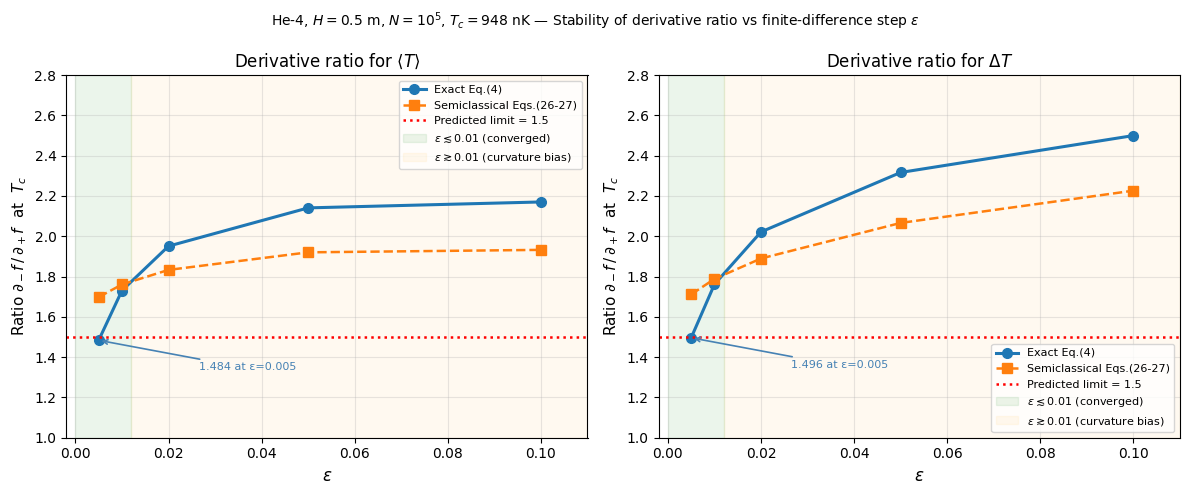

In [ ]:
#!/usr/bin/env python3
"""
Derivative ratio scan — stability analysis as a function of epsilon.

For each epsilon, we estimate the left and right derivatives of <T>(T) and
DeltaT(T) at T = Tc using finite differences:

  slope_left  = (f(Tc) - f(Tc - eps*Tc)) / (eps*Tc)
  slope_right = (f(Tc + eps*Tc) - f(Tc)) / (eps*Tc)
  ratio       = slope_left / slope_right

Mathieu's analytical prediction: ratio -> 1.5 as eps -> 0.

We compute this for:
  - Exact Eq.(4): full numerical TOA computation
  - Semiclassical Eqs.(26-27): analytical approximation

Requires toa_bose_v5.py in the same directory.
"""
import math, time
import numpy as np
import matplotlib.pyplot as plt
#from toa_bose_v5 import (toa_moments, compute_Tc, semiclassical_moments,
#                          N_target, kB, tc)
from scipy.special import zeta as _zeta

t0 = time.time()

# ── Parameters ──
hbar      = 1.054571817e-34
omega_x   = 2*math.pi*1000
omega_y   = 2*math.pi*1000
omega_z   = 2*math.pi*100
omega_bar = (omega_x * omega_y * omega_z)**(1/3)
kB_val    = 1.380649e-23

Tc    = compute_Tc(N_target)
Tc_sc = (hbar * omega_bar / kB_val) * (N_target / _zeta(3))**(1/3)
print(f"Tc (exact numerical) = {Tc*1e9:.2f} nK")
print(f"Tc (analytic)        = {Tc_sc*1e9:.2f} nK\n")

# ── Pre-compute f(Tc) once ──
print("Computing toa_moments at Tc (used for all epsilons)...")
mean_C, std_C, _, _, _ = toa_moments(Tc, Tc, N_target)
sc_C = semiclassical_moments(Tc_sc * (1 - 1e-10), Tc_sc)  # approach from below
print(f"  Exact:  <T>(Tc) = {mean_C*1e3:.4f} ms,  DeltaT(Tc) = {std_C*1e3:.4f} ms")
print(f"  SC:     <T>(Tc) = {sc_C[0]*1e3:.4f} ms,  DeltaT(Tc) = {sc_C[1]*1e3:.4f} ms\n")

# ── Epsilon scan ──
epsilons = [0.005, 0.01, 0.02, 0.05, 0.10]
results  = []

print(f"{'eps':>6}  {'R<T> exact':>11}  {'RDT exact':>10}  {'R<T> SC':>9}  {'RDT SC':>8}")
for eps in epsilons:
    dT    = eps * Tc
    dT_sc = eps * Tc_sc

    # --- Exact Eq.(4) ---
    mean_L, std_L, _, _, _ = toa_moments(Tc - dT, Tc, N_target)
    mean_R, std_R, _, _, _ = toa_moments(Tc + dT, Tc, N_target)

    sl_m = (mean_C - mean_L) / dT;  sr_m = (mean_R - mean_C) / dT
    sl_s = (std_C  - std_L)  / dT;  sr_s = (std_R  - std_C)  / dT
    r_m  = sl_m / sr_m
    r_s  = sl_s / sr_s

    # --- Semiclassical Eqs.(26-27) ---
    sc_L = semiclassical_moments(Tc_sc - dT_sc, Tc_sc)
    sc_R = semiclassical_moments(Tc_sc + dT_sc, Tc_sc)

    sl_sm = (sc_C[0] - sc_L[0]) / dT_sc;  sr_sm = (sc_R[0] - sc_C[0]) / dT_sc
    sl_ss = (sc_C[1] - sc_L[1]) / dT_sc;  sr_ss = (sc_R[1] - sc_C[1]) / dT_sc
    r_sm  = sl_sm / sr_sm
    r_ss  = sl_ss / sr_ss

    results.append((eps, r_m, r_s, r_sm, r_ss))
    print(f"{eps:>6.3f}  {r_m:>11.4f}  {r_s:>10.4f}  {r_sm:>9.4f}  {r_ss:>8.4f}")

print(f"\nTotal runtime: {time.time()-t0:.1f} s")

# ── Plot ──
eps_arr = np.array([r[0] for r in results])
rm_ex   = np.array([r[1] for r in results])
rs_ex   = np.array([r[2] for r in results])
rm_sc   = np.array([r[3] for r in results])
rs_sc   = np.array([r[4] for r in results])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, r_ex, r_sc, label in zip(
        axes,
        [rm_ex, rs_ex],
        [rm_sc, rs_sc],
        [r"$\langle T \rangle$", r"$\Delta T$"]):

    ax.plot(eps_arr, r_ex, 'o-',  lw=2.2, ms=7, label="Exact Eq.(4)")
    ax.plot(eps_arr, r_sc, 's--', lw=1.8, ms=7, label="Semiclassical Eqs.(26-27)")
    ax.axhline(1.5, ls=":", color="red", lw=1.8, label="Predicted limit = 1.5")

    # Shade the "safe" epsilon zone
    ax.axvspan(0, 0.012, alpha=0.08, color="green", label=r"$\epsilon \lesssim 0.01$ (converged)")
    ax.axvspan(0.012, 0.11, alpha=0.06, color="orange", label=r"$\epsilon \gtrsim 0.01$ (curvature bias)")

    ax.set_xlabel(r"$\epsilon$", fontsize=12)
    ax.set_ylabel(r"Ratio $\partial_- f \,/\, \partial_+ f$  at  $T_c$", fontsize=11)
    ax.set_title(rf"Derivative ratio for {label}", fontsize=12)
    ax.set_xlim(-0.002, 0.11)
    ax.set_ylim(1.0, 2.8)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # Annotate the eps->0 value
    ax.annotate(f"  {r_ex[0]:.3f} at ε=0.005",
                xy=(eps_arr[0], r_ex[0]),
                xytext=(0.025, r_ex[0] - 0.15),
                fontsize=8, color="steelblue",
                arrowprops=dict(arrowstyle="->", color="steelblue", lw=1.2))

fig.suptitle(
    rf"He-4, $H=0.5$ m, $N=10^5$, $T_c={Tc*1e9:.0f}$ nK — "
    rf"Stability of derivative ratio vs finite-difference step $\epsilon$",
    fontsize=10
)
fig.tight_layout()
#plt.savefig("/mnt/user-data/outputs/deriv_ratio_scan.png", dpi=150, bbox_inches="tight")
#print("Plot saved.")

# TOA Plots

tc = 319.275 ms,  sigma_z = 5.028 µm
Condensate peak width in time: dt_cond = 0.3220 ms
Computing Tc...
  Analytic Tc estimate: 972.4 nK
  Tc = 947.94 nK = 0.9479 µK
  Verify: N_th_max(Tc) = 1.0000e+05  (target = 1e+05)
  Tc_sc (analytic) = 972.44 nK

   i    T/Tc    <T>(ms)     ΔT(ms)   norm_J/N      mu/kBT  BEC
   0   0.020   319.2755     0.2278    1.00000   -0.000000  YES
   3   0.121   319.2755     0.2401    1.00000   -0.000000  YES
   6   0.221   319.2756     0.3238    1.00000   -0.000000  YES
   9   0.322   319.2758     0.5205    1.00000   -0.000001  YES
  12   0.423   319.2765     0.8219    0.99999   -0.000002  YES
  15   0.523   319.2777     1.2166    0.99999   -0.000003  YES
  18   0.624   319.2800     1.6996    0.99999   -0.000006  YES
  21   0.725   319.2835     2.2687    0.99998   -0.000011  YES
  24   0.825   319.2888     2.9229    0.99998   -0.000020  YES
  27   0.926   319.2965     3.6616    0.99997   -0.000049  YES
  30   1.027   319.3052     4.3539    0.99996   -0.0531

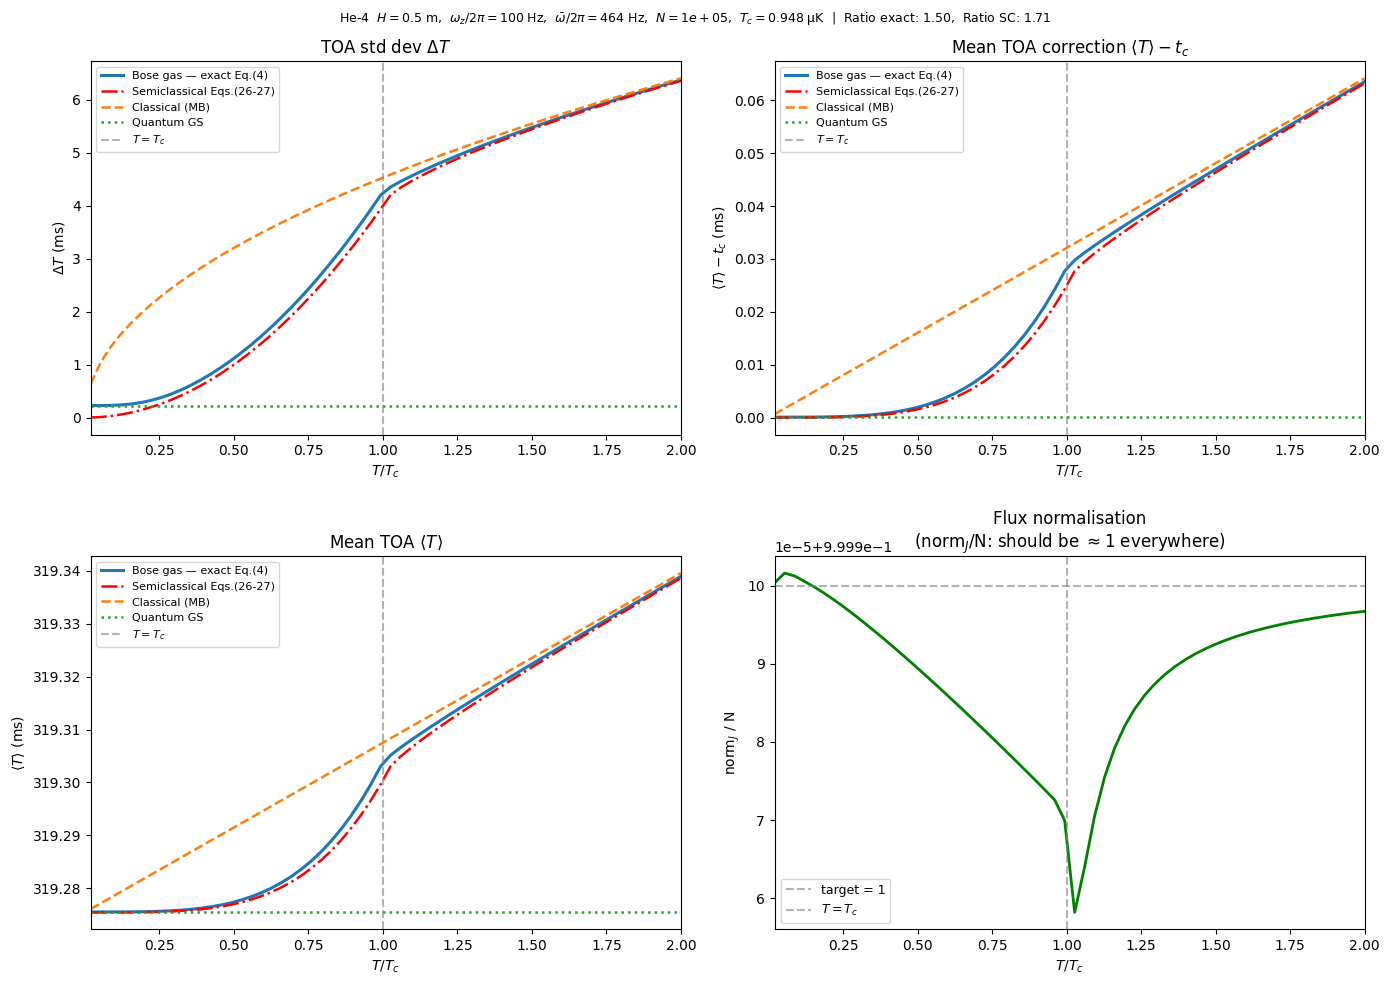

Done.


In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature — exact Eq.(4) + condensate below Tc

Key changes vs previous version:
  1. rho is explicitly normalised to 1 in position space before computing J(t),
     so that norm of Pi(t) is physically meaningful (should be ~1 after t-integration).
  2. Derivative ratio Delta computed numerically at T=Tc (target: ~1.5).
  3. Vectorised j-loop in rho_thermal kept but written so the physics is clear.
  4. Speed: only modest vectorisation, nothing that obscures the physics.

FIX (v1-fixed): Non-uniform time grid that clusters extra points near tc.
  The condensate peak in Pi(t) has a temporal width of ~sigma_z/|dz_tilde/dt|
  ~ 0.3 ms, while a uniform grid of Nt=1201 points over [0, 3*tc] has spacing
  ~0.8 ms — too coarse to resolve the peak. This caused norm_J/N < 1 below Tc
  and underestimated DeltaT at low temperatures.
  The fix uses a non-uniform grid that places ~200 extra points in a window of
  ±5*dt_cond around tc, where dt_cond is the condensate peak width in time.
  This keeps the total number of points manageable while properly resolving the peak.

Parameters (from instruction PDF):
  m = 6.64e-27 kg (He-4)
  H = 0.50 m  (experimental)   <-- change H here
  omega_z/2pi = 100 Hz
  omega_x = omega_y = 2pi*1000 Hz
  g = 9.81 m/s^2,  N = 1e5
"""

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import brentq

# ─────────────────────────────────────────────
# Physical constants
# ─────────────────────────────────────────────
kB   = 1.380649e-23    # J/K
hbar = 1.054571817e-34 # J·s

# ─────────────────────────────────────────────
# System parameters
# ─────────────────────────────────────────────
m       = 6.64e-27            # kg  (He-4)
g       = 9.81                # m/s^2
H       = 0.50                # m   (experimental regime)

omega_z = 2*math.pi * 100.0   # rad/s  axial trap
omega_x = 2*math.pi * 1000.0  # rad/s  transverse
omega_y = 2*math.pi * 1000.0  # rad/s  transverse

N_target = 1e5
npts     = 60    # number of temperature points

# ─────────────────────────────────────────────
# Derived constants
# ─────────────────────────────────────────────
tc      = math.sqrt(2.0 * H / g)              # classical time of flight
sigma_z = math.sqrt(hbar / (m * omega_z))     # HO ground-state length along z

# For semiclassical baselines (Eqs. 8-9 of draft)
sigmaV0_sq = hbar * omega_z / (2.0 * m)       # GS velocity variance
pref_mean  = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# Condensate peak width in time (used to build the non-uniform grid).
# dz_tilde/dt at t=tc is g*tc/sqrt(1+omega_z^2*tc^2).
# The condensate Gaussian has width sigma_z in z_tilde space.
# So the peak width in time is dt_cond = sigma_z / (dz_tilde/dt).
_dztdt_tc = g * tc / math.sqrt(1.0 + omega_z**2 * tc**2)
dt_cond   = sigma_z / _dztdt_tc  # ~ 0.32 ms for H=0.5

print(f"tc = {tc*1e3:.3f} ms,  sigma_z = {sigma_z*1e6:.3f} µm")
print(f"Condensate peak width in time: dt_cond = {dt_cond*1e3:.4f} ms")


# ═════════════════════════════════════════════
# Section 1: Thermal occupation / Tc
# ═════════════════════════════════════════════

def _bose1d(b):
    """sum_{n=1}^inf 1/(exp(n*b)-1), the 1D Bose-Einstein sum."""
    n_max = min(int(50.0 / b) + 2, 500_000)
    ns = np.arange(1, n_max + 1, dtype=np.float64)
    return float(np.sum(1.0 / np.expm1(ns * b)))

def _F_ksum(ez, bx, by):
    """
    sum_{k>=1} exp(-k*ez) / [(1-exp(-k*bx))*(1-exp(-k*by))]
    Used to efficiently sum over transverse modes nx,ny at fixed k=cycle length.
    """
    k_max = min(int(50.0 / ez) + 2, 500_000)
    ks  = np.arange(1, k_max + 1, dtype=np.float64)
    ks  = ks[ks * ez < 50.0]
    terms = np.exp(-ks * ez) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_th_max(T):
    """
    Maximum number of particles in thermal (excited) states, i.e. at mu_tilde=0.
    When N_th_max(T) < N_target, we are below Tc and a condensate forms.
    """
    beta = 1.0 / (kB * T)
    bx = beta * hbar * omega_x
    by = beta * hbar * omega_y
    bz = beta * hbar * omega_z

    S = _bose1d(bx)                  # nz=0, ny=0, nx>=1
    S += _F_ksum(by, bx, by)         # nz=0, ny>=1
    for nz in range(1, int(50.0/bz) + 3):
        ez = nz * bz
        if ez > 50.0: break
        contrib = _F_ksum(ez, bx, by)
        S += contrib
        if nz > 5 and contrib < 1e-8 * max(1.0, S): break
    return S

def compute_Tc(N_target):
    """Find Tc by solving N_th_max(Tc) = N_target."""
    zeta3     = 1.20205690315959
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_approx = (hbar * omega_bar / kB) * (N_target / zeta3) ** (1.0/3.0)
    print(f"  Analytic Tc estimate: {Tc_approx*1e9:.1f} nK")
    f = lambda T: N_th_max(T) - N_target
    T_lo, T_hi = 0.5*Tc_approx, 2.0*Tc_approx
    for _ in range(30):
        if f(T_lo) < 0: break
        T_lo *= 0.5
    for _ in range(30):
        if f(T_hi) > 0: break
        T_hi *= 2.0
    return brentq(f, T_lo, T_hi, xtol=1e-11*Tc_approx, rtol=1e-9, maxiter=200)


# ═════════════════════════════════════════════
# Section 2: Chemical potential mu(T)
# ═════════════════════════════════════════════

def N_cluster_sum(mu, T, j_max):
    """
    Cluster (path-integral) sum for total particle number, Eq.(5).
    Summed to j_max = N so that long permutation cycles (j ~ N) are included.
    These long cycles ARE the condensate: below Tc, they carry the macroscopic
    occupation. mu is NOT set to zero below Tc; instead it converges to a small
    negative value ~ -kB*T/N0 (see Mathieu's email, Eq. after Eq.5).
    """
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z
    S    = 0.0
    chunk = 4096
    j = 1
    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_wj = js * (beta * mu)
        if log_wj[0] < -700: break       # remaining terms negligible

        wj   = np.exp(np.clip(log_wj, -700, 0.0))
        # Partition function factor for each cycle length j:
        #   Z_j = 1 / [(1-e^{-j*bx})(1-e^{-j*by})(1-e^{-j*bz})]
        Zj   = 1.0 / ((-np.expm1(-js*bx)) * (-np.expm1(-js*by)) * (-np.expm1(-js*bz)))
        term = wj * Zj
        S   += float(term[np.isfinite(term)].sum())
        j    = j_end + 1
    return S

def solve_mu(T, N_target):
    """
    Solve N_cluster_sum(mu, T, j_max=N) = N_target for mu_tilde.
    Valid at ALL temperatures including T < Tc.
    """
    j_max = int(N_target)
    f     = lambda mu: N_cluster_sum(mu, T, j_max) - N_target
    mu_hi = -1e-50
    mu_lo = -50.0 * kB * T
    for _ in range(80):
        if f(mu_lo) < 0: break
        mu_lo *= 2.0
    return brentq(f, mu_lo, mu_hi, xtol=1e-50, rtol=1e-9, maxiter=300)


# ═════════════════════════════════════════════
# Section 3: TOA density rho(z_tilde, t) from Eq.(4)
# ═════════════════════════════════════════════

def rho_eq_perp(z2_vec, T, mu, j_max):
    """
    Evaluates Eq.(4) of the draft paper at all z_tilde values given in z2_vec
    (which is z_tilde^2 evaluated along the time grid).

    Physical meaning: this is the equilibrium density profile of the gas
    projected onto the z-axis (after tracing out transverse degrees of freedom),
    expressed as a function of the rescaled coordinate z_tilde(t).

    Each term j in the sum corresponds to a permutation cycle of length j
    in the path-integral representation. Long cycles (j~N) encode the BEC.

    Returns rho as an array over the time grid (same length as z2_vec).

    NOTE: rho here has units of 1/m (it is a 1D spatial density), so its
    integral over z is dimensionless (= total projected particle number ~ N).
    We normalise it to 1 before computing the flux J, so that the TOA
    distribution Pi(t) = J(t) / integral(J) is a proper probability density.
    """
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z   # = tau_z in the paper

    rho   = np.zeros(len(z2_vec), dtype=np.float64)
    S_amp = 0.0   # running sum of amplitudes for convergence check
    chunk = 2048
    j = 1

    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_wj = js * (beta * mu)
        if log_wj[0] < -700: break

        wj = np.exp(np.clip(log_wj, -700, 0.0))

        # Transverse partition factor for cycle length j
        Zperp_j = 1.0 / ((-np.expm1(-js*bx)) * (-np.expm1(-js*by)))

        # Axial Gaussian parameters (from Eq.4):
        #   width factor:     1 - exp(-2*j*tau_z)
        #   exponent factor:  tanh(j*tau_z / 2) / sigma_z^2
        omp_2z = -np.expm1(-2.0 * js * bz)        # 1 - exp(-2*j*tau_z)
        tanh_h = np.tanh(0.5 * js * bz)            # tanh(j*tau_z/2)

        # Amplitude of each Gaussian in Eq.(4):
        #   Aj = exp(j*beta*mu) * Zperp_j / (sigma_z * sqrt(pi*(1-exp(-2j*tau_z))))
        Aj = wj * Zperp_j / (sigma_z * np.sqrt(np.pi * omp_2z))

        # Gaussian decay rate in z_tilde:
        #   Bj = tanh(j*tau_z/2) / sigma_z^2
        Bj = tanh_h / sigma_z**2

        # Accumulate: rho(z_tilde) += sum_j Aj * exp(-Bj * z_tilde^2)
        # Shape: (len_js, Nt) -> sum over j axis
        sub = 512
        for s in range(0, len(Aj), sub):
            a = Aj[s:s+sub]
            b = Bj[s:s+sub]
            rho += (a[:, None] * np.exp(-b[:, None] * z2_vec[None, :])).sum(axis=0)

        S_amp += float(Aj.sum())
        if j_end > 50 and float(abs(Aj[-1])) < 1e-8 * max(1.0, S_amp):
            break
        j = j_end + 1

    return rho


# ═════════════════════════════════════════════
# Section 4: Time grid and TOA moments
# ═════════════════════════════════════════════

def make_time_grid(T):
    """
    Build a temperature-dependent, NON-UNIFORM time grid.

    The TOA distribution has two features with different widths:
      1. A broad thermal component of width ~ sigma_v / g (several ms)
      2. A narrow condensate peak at t = tc of width ~ dt_cond (~0.3 ms)

    A uniform grid with ~1200 points over [0, 3*tc] has spacing ~0.8 ms,
    which underresolves the condensate peak.

    FIX: we build the grid in three pieces:
      (a) [tmin, tc - 5*dt_cond]    — coarse (thermal tail, ~500 points)
      (b) [tc - 5*dt_cond, tc + 5*dt_cond] — fine (condensate peak, ~200 points)
      (c) [tc + 5*dt_cond, tmax]    — coarse (thermal tail, ~500 points)

    This ensures the condensate peak is properly resolved at all temperatures,
    while keeping the total number of points manageable (~1200).
    """
    sigma_v  = math.sqrt(kB * T / m)
    tmax     = max(3.0 * tc, tc + 6.0 * sigma_v / g)
    tmin     = 1e-4

    # Window around tc where the condensate peak lives
    half_win = 5.0 * dt_cond
    t_lo = max(tmin + 1e-6, tc - half_win)
    t_hi = min(tmax - 1e-6, tc + half_win)

    # Number of points in each segment (total ~ 1200)
    n_fine   = 201   # points in the condensate window
    n_coarse = 500   # points in each coarse tail

    t_left   = np.linspace(tmin, t_lo, n_coarse, endpoint=False)
    t_center = np.linspace(t_lo, t_hi, n_fine)
    t_right  = np.linspace(t_hi, tmax, n_coarse + 1)[1:]  # skip duplicate at t_hi

    t = np.concatenate([t_left, t_center, t_right])

    oz2      = omega_z**2
    zc       = H - 0.5 * g * t**2           # cloud centre position at time t
    denom    = 1.0 + oz2 * t**2             # 1 + omega_z^2 * t^2

    # Rescaled detector coordinate (Eq.3 of paper):
    # z_tilde(t) = (z_detector - zc(t)) / sqrt(denom)
    # with z_detector = 0 (detector at bottom, trap at z=H)
    zt       = -zc / np.sqrt(denom)
    z2       = zt**2

    # Jacobian from coordinate change (scaling factor in Eq.3)
    jac      = 1.0 / np.sqrt(denom)

    # Axial velocity of a fluid element at the detector z=0 (from Eq.1 of paper).
    # The velocity field of the expanding gas is:
    #   v_z(z,t) = (z - zc(t)) * omega_z^2*t / (1 + omega_z^2*t^2)  +  dzc/dt
    # where dzc/dt = -g*t (free fall of trap centre).
    # At z=0 (detector): z - zc(t) = -zc(t) = 0.5*g*t^2 - H
    # So: vz|_{z=0} = omega_z^2*t*(0.5*g*t^2 - H)/(1+omega_z^2*t^2) - g*t
    vz       = omega_z**2 * t * (0.5*g*t**2 - H) / denom - g*t

    return t, z2, jac, vz

def toa_moments(T, Tc, N_target):
    """
    Compute mean TOA and std dev of TOA for a Bose gas at temperature T.

    Steps:
      1. Solve mu_tilde from Eq.(5) with j_max=N  (valid for all T)
      2. Evaluate rho from Eq.(4) along the time grid
      3. Form flux J(t) = |vz(t)| * jac(t) * rho(z_tilde(t))
         (units: (m/s) * (1) * (1/m) = 1/s)
      4. Normalise J once -> Pi(t), a probability density over time
      5. Compute moments of Pi(t)
    """
    # Step 1: chemical potential (valid at ALL T, including below Tc)
    mu = solve_mu(T, N_target)

    # Step 2: time grid and rho from Eq.(4)
    t, z2, jac, vz = make_time_grid(T)
    j_max = int(N_target)
    rho   = rho_eq_perp(z2, T, mu, j_max)

    # Step 3: flux J(t) = |vz(t)| * jac(t) * rho(z_tilde(t))
    # rho has units 1/m, vz in m/s, jac dimensionless -> J in 1/s.
    # We take abs(vz) because we want the magnitude of flux at detector.
    J = np.abs(vz * jac * rho)

    # Step 4: normalise J once to get Pi(t), a probability density over time.
    # norm_J should be ~N (it's the integral of the unnormalised flux).
    # Dividing by norm_J gives Pi with integral = 1.
    norm_J = simpson(J, x=t)
    if norm_J > 0:
        Pi = J / norm_J
    else:
        Pi = J

    # Step 5: moments
    mean  = simpson(t      * Pi, x=t)
    mean2 = simpson(t**2   * Pi, x=t)
    std   = math.sqrt(max(0.0, mean2 - mean**2))

    has_BEC = N_th_max(T) < N_target

    return mean, std, norm_J, mu / (kB * T), has_BEC

def mean_TOA_classical(T):
    return tc + pref_mean * (kB * T / m)

def std_TOA_classical(T):
    return (1.0 / g) * math.sqrt(kB * T / m)

def mean_TOA_GS(_):
    return tc + pref_mean * sigmaV0_sq

def std_TOA_GS(_):
    return (1.0 / g) * math.sqrt(sigmaV0_sq)


# ═════════════════════════════════════════════
# Section 5b: Semiclassical asymptotes (Eqs. 26-27)
# ═════════════════════════════════════════════

def polylog(s, z, nterms=5000):
    """Polylogarithm Li_s(z) = sum_{k=1}^inf z^k / k^s, for 0 < z <= 1."""
    from scipy.special import zeta as _zeta
    if z <= 0: return 0.0
    if z >= 1.0: return float(_zeta(s))
    ks = np.arange(1, nterms + 1, dtype=np.float64)
    return float(np.sum(z**ks / ks**s))

def solve_fugacity(T, Tc_sc):
    """
    Solve for z = exp(beta*mu_tilde) above Tc using the semiclassical
    constraint: N = (kB*T / hbar*omega_bar)^3 * Li_3(z).
    Below Tc, z = 1.
    """
    from scipy.special import zeta as _zeta
    target_Li3 = _zeta(3) * (Tc_sc / T)**3
    if target_Li3 >= _zeta(3):  # T <= Tc
        return 1.0
    return brentq(lambda z: polylog(3, z) - target_Li3, 1e-15, 1.0 - 1e-12, rtol=1e-12)

def semiclassical_moments(T, Tc_sc):
    """
    Semiclassical mean TOA and std dev from Eqs. (26)-(27).

    Above Tc:
      <T> = tc + pref * (kB*T/m) * Li_{7/2}(z) / Li_{5/2}(z)
      DT  = (vT/g) * sqrt(Li_{7/2}(z) / Li_{5/2}(z))
      where z is the fugacity from N = (kB*T/hbar*omega_bar)^3 * Li_3(z)

    Below Tc:
      z = 1, Li_s(1) = zeta(s). The distribution is a mixture:
        Pi(t) = (N_th/N) * Pi_thermal + (N0/N) * delta(t - tc)
      with N_th/N = (T/Tc)^3. Moments are computed from this mixture.
    """
    from scipy.special import zeta as _zeta
    vT = math.sqrt(kB * T / m)

    if T >= Tc_sc:
        z = solve_fugacity(T, Tc_sc)
        r = polylog(3.5, z) / polylog(2.5, z)
        mean = tc + pref_mean * (kB * T / m) * r
        std  = (vT / g) * math.sqrt(r)
    else:
        w_th = (T / Tc_sc)**3
        r    = _zeta(3.5) / _zeta(2.5)   # z = 1
        # Thermal component
        mean_th  = tc + pref_mean * (kB * T / m) * r
        var_th   = (vT / g)**2 * r
        mean2_th = var_th + mean_th**2
        # Mixture with condensate delta at tc
        mean     = w_th * mean_th + (1.0 - w_th) * tc
        mean2    = w_th * mean2_th + (1.0 - w_th) * tc**2
        std      = math.sqrt(max(0.0, mean2 - mean**2))

    return mean, std


# ═════════════════════════════════════════════
# Section 6: Derivative ratio at Tc  (target ~1.5)
# ═════════════════════════════════════════════

def compute_derivative_ratio(Tc, Tc_sc, N_target, epsilon=0.005):
    """
    Compute the ratio of left/right derivatives of mean TOA and std TOA at Tc,
    both from the exact Eq.(4) and from the semiclassical Eqs.(26)-(27).
    """
    dT = epsilon * Tc

    print(f"\nComputing derivative ratios at Tc (epsilon={epsilon})...")

    # --- Exact (Eq.4) ---
    mean_L, std_L, _, _, _ = toa_moments(Tc - dT, Tc, N_target)
    mean_C, std_C, _, _, _ = toa_moments(Tc,      Tc, N_target)
    mean_R, std_R, _, _, _ = toa_moments(Tc + dT, Tc, N_target)

    sl_mean = (mean_C - mean_L) / dT;  sr_mean = (mean_R - mean_C) / dT
    sl_std  = (std_C  - std_L)  / dT;  sr_std  = (std_R  - std_C)  / dT
    ratio_mean = sl_mean / sr_mean if sr_mean != 0 else float('nan')
    ratio_std  = sl_std  / sr_std  if sr_std  != 0 else float('nan')

    print(f"  Exact Eq.(4):")
    print(f"    Ratio <T>: {ratio_mean:.4f}")
    print(f"    Ratio ΔT:  {ratio_std:.4f}")

    # --- Semiclassical (Eqs.26-27) ---
    sc_L = semiclassical_moments(Tc_sc - dT, Tc_sc)
    sc_C = semiclassical_moments(Tc_sc,      Tc_sc)
    sc_R = semiclassical_moments(Tc_sc + dT, Tc_sc)

    sl_sc_mean = (sc_C[0] - sc_L[0]) / dT;  sr_sc_mean = (sc_R[0] - sc_C[0]) / dT
    sl_sc_std  = (sc_C[1] - sc_L[1]) / dT;  sr_sc_std  = (sc_R[1] - sc_C[1]) / dT
    ratio_sc_mean = sl_sc_mean / sr_sc_mean if sr_sc_mean != 0 else float('nan')
    ratio_sc_std  = sl_sc_std  / sr_sc_std  if sr_sc_std  != 0 else float('nan')

    print(f"  Semiclassical Eqs.(26-27):")
    print(f"    Ratio <T>: {ratio_sc_mean:.4f}")
    print(f"    Ratio ΔT:  {ratio_sc_std:.4f}")

    return ratio_mean, ratio_std, ratio_sc_mean, ratio_sc_std


# ═════════════════════════════════════════════
# Section 7: Main
# ═════════════════════════════════════════════

def main():
    import time
    from scipy.special import zeta as _zeta
    t_start = time.time()

    print("Computing Tc...")
    Tc = compute_Tc(N_target)
    print(f"  Tc = {Tc*1e9:.2f} nK = {Tc*1e6:.4f} µK")
    print(f"  Verify: N_th_max(Tc) = {N_th_max(Tc):.4e}  (target = {N_target:.0e})")

    # Analytic Tc (used for semiclassical formulas)
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_sc = (hbar * omega_bar / kB) * (N_target / _zeta(3)) ** (1.0/3.0)
    print(f"  Tc_sc (analytic) = {Tc_sc*1e9:.2f} nK")
    print()

    # Temperature sweep: 0.02*Tc to 2*Tc
    Ts = np.linspace(0.02 * Tc, 2.00 * Tc, npts)

    mean_b = np.zeros(npts)
    std_b  = np.zeros(npts)
    norm_J = np.zeros(npts)

    print(f"{'i':>4}  {'T/Tc':>6}  {'<T>(ms)':>9}  {'ΔT(ms)':>9}  "
          f"{'norm_J/N':>9}  {'mu/kBT':>10}  BEC")
    for i, T in enumerate(Ts):
        mT, sT, nr, mu_kbt, bec = toa_moments(float(T), Tc, N_target)
        mean_b[i] = mT
        std_b[i]  = sT
        norm_J[i] = nr
        if i % max(1, npts // 20) == 0 or i == npts - 1:
            print(f"{i:>4}  {T/Tc:>6.3f}  {mT*1e3:>9.4f}  {sT*1e3:>9.4f}  "
                  f"{nr/N_target:>9.5f}  {mu_kbt:>10.6f}  {'YES' if bec else 'no'}")

    print(f"\nnorm_J/N range: [{(norm_J/N_target).min():.5f}, {(norm_J/N_target).max():.5f}]")

    elapsed = time.time() - t_start
    print(f"Temperature sweep runtime: {elapsed:.1f} s")

    # Derivative ratio at Tc (exact and semiclassical)
    ratio_mean, ratio_std, ratio_sc_mean, ratio_sc_std = \
        compute_derivative_ratio(Tc, Tc_sc, N_target)

    # ── Baselines ──
    T_over_Tc = Ts / Tc
    mean_cl   = np.array([mean_TOA_classical(T) for T in Ts])
    std_cl    = np.array([std_TOA_classical(T)  for T in Ts])
    mean_q1   = np.array([mean_TOA_GS(T)        for T in Ts])
    std_q1    = np.array([std_TOA_GS(T)         for T in Ts])

    # Semiclassical asymptotes (Eqs. 26-27)
    mean_sc = np.zeros(npts)
    std_sc  = np.zeros(npts)
    for i, T in enumerate(Ts):
        m_sc, s_sc = semiclassical_moments(float(T), Tc_sc)
        mean_sc[i] = m_sc
        std_sc[i]  = s_sc

    # ── Plots ──
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Top-left: std dev
    ax = axes[0, 0]
    ax.plot(T_over_Tc, std_b*1e3,  lw=2.2,                    label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, std_sc*1e3, lw=1.8, ls="-.", color="red", label="Semiclassical Eqs.(26-27)")
    ax.plot(T_over_Tc, std_cl*1e3, lw=1.8, ls="--",           label="Classical (MB)")
    ax.plot(T_over_Tc, std_q1*1e3, lw=1.8, ls=":",            label="Quantum GS")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T=T_c$")
    ax.set_xlabel(r"$T/T_c$"); ax.set_ylabel(r"$\Delta T$ (ms)")
    ax.set_title(r"TOA std dev $\Delta T$")
    ax.legend(fontsize=8); ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    # Top-right: mean TOA correction
    ax = axes[0, 1]
    ax.plot(T_over_Tc, (mean_b  - tc)*1e3, lw=2.2,                    label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, (mean_sc - tc)*1e3, lw=1.8, ls="-.", color="red", label="Semiclassical Eqs.(26-27)")
    ax.plot(T_over_Tc, (mean_cl - tc)*1e3, lw=1.8, ls="--",           label="Classical (MB)")
    ax.plot(T_over_Tc, (mean_q1 - tc)*1e3, lw=1.8, ls=":",            label="Quantum GS")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T=T_c$")
    ax.set_xlabel(r"$T/T_c$"); ax.set_ylabel(r"$\langle T\rangle - t_c$ (ms)")
    ax.set_title(r"Mean TOA correction $\langle T\rangle - t_c$")
    ax.legend(fontsize=8); ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    # Bottom-left: absolute mean TOA
    ax = axes[1, 0]
    ax.plot(T_over_Tc, mean_b*1e3,  lw=2.2,                    label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, mean_sc*1e3, lw=1.8, ls="-.", color="red", label="Semiclassical Eqs.(26-27)")
    ax.plot(T_over_Tc, mean_cl*1e3, lw=1.8, ls="--",           label="Classical (MB)")
    ax.plot(T_over_Tc, mean_q1*1e3, lw=1.8, ls=":",            label="Quantum GS")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T=T_c$")
    ax.set_xlabel(r"$T/T_c$"); ax.set_ylabel(r"$\langle T\rangle$ (ms)")
    ax.set_title(r"Mean TOA $\langle T\rangle$")
    ax.legend(fontsize=8); ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    # Bottom-right: norm_J/N diagnostic
    ax = axes[1, 1]
    ax.plot(T_over_Tc, norm_J / N_target, lw=2.0, color="green")
    ax.axhline(1.0, ls="--", color="gray", alpha=0.6, label="target = 1")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T=T_c$")
    ax.set_xlabel(r"$T/T_c$"); ax.set_ylabel(r"norm$_J$ / N")
    ax.set_title("Flux normalisation\n" r"(norm$_J$/N: should be $\approx 1$ everywhere)")
    ax.legend(fontsize=9); ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    fig.suptitle(
        rf"He-4  $H={H}$ m,  $\omega_z/2\pi={omega_z/(2*math.pi):.0f}$ Hz,  "
        rf"$\bar{{\omega}}/2\pi={omega_bar/(2*math.pi):.0f}$ Hz,  "
        rf"$N={N_target:.0e}$,  $T_c={Tc*1e6:.3f}$ µK  |  "
        rf"Ratio exact: {ratio_std:.2f},  Ratio SC: {ratio_sc_std:.2f}",
        fontsize=9,
    )
    fig.tight_layout()
    plt.savefig("toa_bose_output.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Done.")


if __name__ == "__main__":
    main()

# TOA Plots Mar 5

tc = 45.152 ms,  sigma_z = 5.028 µm
Computing Tc_exact …
  Analytic Tc estimate: 972.4 nK
  Tc_exact = 947.94 nK = 0.9479 µK
  Verify: N_th_max(Tc) = 1.0000e+05  (target = 1e+05)

   i    T/Tc    <T>(ms)     DT(ms)     norm      mu/kBT  BEC
   0   0.020    45.1541     0.2279  49999.99372   -0.000000  YES
   3   0.121    45.1543     0.2403  49999.99302   -0.000000  YES
   6   0.221    45.1558     0.3245  49999.98727   -0.000000  YES
   9   0.322    45.1613     0.5230  49999.96704   -0.000001  YES
  12   0.423    45.1747     0.8275  49999.91775   -0.000002  YES
  15   0.523    45.2013     1.2269  49999.81970   -0.000003  YES
  18   0.624    45.2477     1.7159  49999.64805   -0.000006  YES
  21   0.725    45.3221     2.2919  49999.37281   -0.000011  YES
  24   0.825    45.4338     2.9526  49998.95887   -0.000020  YES
  27   0.926    45.5935     3.6956  49998.36604   -0.000049  YES
  30   1.027    45.7753     4.3892  49997.68974   -0.053169  no
  33   1.127    45.8594     4.6815  49997.374

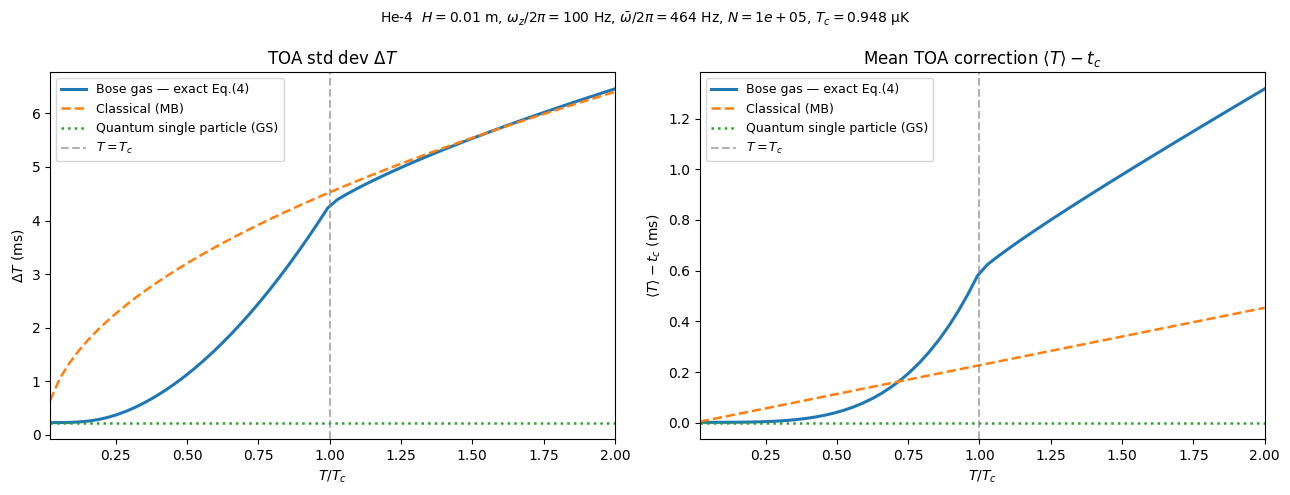

Done.


In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature — exact Eq.(4) + condensate below Tc
Matches parameters and equations from the two supervisor PDFs exactly.

Parameters (from instruction PDF):
  m = 6.64e-27 kg (He-4)
  H = 0.50 m
  omega_z/2pi = 100 Hz
  g = 9.81 m/s^2
  N = 1e5,  omega_x=omega_y = 2pi*1000 Hz

Key equation: Eq.(4) from draft paper
  rho_eq_perp(z_tilde) = sum_{j=1}^inf exp(j*beta*mu_tilde)
    * prod_{alpha=x,y} 1/(1-exp(-j*beta*hbar*omega_alpha))
    * 1/(sigma_z*sqrt(pi*(1-exp(-2*j*tau_z))))
    * exp(-tanh(j*tau_z/2) * z_tilde^2/sigma_z^2)
  where tau_z = beta*hbar*omega_z,  mu_tilde = mu - hbar*(wx+wy+wz)/2,
  z_tilde = (z - zc(t))/sqrt(1+omega_z^2*t^2)  evaluated at z=H (detector).

Eq.(3): J(H,t) = N * vz(t)/sqrt(1+omega_z^2*t^2) * rho_eq_perp(z_tilde(t))
  where z_tilde(t) = (H - zc(t))/sqrt(1+omega_z^2*t^2) = 0.5*g*t^2/sqrt(1+omega_z^2*t^2)

Outputs: <T>(T/Tc) and Delta_T(T/Tc)  [x-axis is T/Tc as in supervisor figures]
"""

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import brentq

# ──────────────────────────────────────────────
# Physical constants
# ──────────────────────────────────────────────
kB   = 1.380649e-23       # J/K
hbar = 1.054571817e-34    # J·s

# ──────────────────────────────────────────────
# System parameters  (from instruction PDF)
# ──────────────────────────────────────────────
m       = 6.64e-27        # kg  (He-4, as stated in PDF)
g       = 9.81            # m/s^2
H       = 0.01            # m   — "near field" regime where quantum statistics are visible.
                          # H=0.50m (experimental) puts the detector 34*sigma_T0 away in
                          # z_tilde coordinates: density ~ exp(-34^2) ~ 0, TOA signal vanishes.
                          # Near field (small H) is where the thermal velocity spread leaves
                          # a visible imprint on the TOA distribution.

omega_z = 2 * math.pi * 100.0    # rad/s  (PDF eq. 3)
omega_x = 2 * math.pi * 1000.0   # rad/s  (transverse, from paper body)
omega_y = 2 * math.pi * 1000.0   # rad/s

N_target = 1e5
npts     = 60     # temperature points along T/Tc axis
Nt       = 1201   # time-grid points

# ──────────────────────────────────────────────
# Derived constants
# ──────────────────────────────────────────────
tc         = math.sqrt(2.0 * H / g)                 # classical TOF (eq. 6)
sigma_z    = math.sqrt(hbar / (m * omega_z))          # HO length along z
sigmaV0_sq = hbar * omega_z / (2.0 * m)              # GS velocity variance (quantum)
pref_mean  = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

print(f"tc = {tc*1e3:.3f} ms,  sigma_z = {sigma_z*1e6:.3f} µm")

# ──────────────────────────────────────────────
# Time grid (built once, vectorised)
# ──────────────────────────────────────────────
# Range: slightly before tc to well past it
tmin_grid = 1e-4          # avoid t=0 singularity
tmax_grid = 3.0 * tc
t_grid    = np.linspace(tmin_grid, tmax_grid, Nt)

_oz2  = omega_z**2
_zc   = H - 0.5 * g * t_grid**2              # cloud centre: starts at H, reaches 0 at tc
_denom= 1.0 + _oz2 * t_grid**2               # 1 + omega_z^2*t^2

# Detector is at z=0 (bottom). Trap starts at z=H (top).
# z_tilde = (z_detector - zc(t)) / sqrt(1+oz^2*t^2) = -zc(t) / sqrt(...)
# At t=tc: zc=0 so z_tilde=0. For t<tc: z_tilde<0. For t>tc: z_tilde>0.
zt_vec  = -_zc / np.sqrt(_denom)
jac_vec = 1.0 / np.sqrt(_denom)
z2_vec  = zt_vec**2

# vz(t) from paper eq.(1) evaluated at z=0 (detector):
# vz(t) = (1/t)*[0 + 0.5*g*t^2 - zc(t)/(1+oz^2*t^2)]
vz_vec  = (1.0 / t_grid) * (0.5*g*t_grid**2 - _zc / _denom)

# (condensate TOA no longer precomputed — included naturally via large-j terms in Eq.(4))


# ══════════════════════════════════════════════
# N_th_max(T): thermal occupation at mu_tilde=0
# = sum_{(nx,ny,nz)!=(0,0,0)} 1/(exp(beta*E_n)-1)
# where E_n = nx*hbar*wx + ny*hbar*wy + nz*hbar*wz  (excitation energies)
#
# Fast algorithm: analytically reduce nx,ny double-sum to k-series.
# For nz>0:  F(ez) = sum_k exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))]
# Total work O(log(1/bz)) instead of O(1/(bx*by*bz)).
# ══════════════════════════════════════════════

def _bose1d(b):
    """sum_{n=1}^inf 1/(exp(n*b)-1),  b > 0"""
    n_max = min(int(50.0 / b) + 2, 500000)
    ns = np.arange(1, n_max + 1, dtype=np.float64)
    return float(np.sum(1.0 / np.expm1(ns * b)))

def _F_ksum(ez, bx, by):
    """sum_{k>=1} exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))],  ez > 0"""
    k_max = min(int(50.0 / ez) + 2, 500000)
    ks  = np.arange(1, k_max + 1, dtype=np.float64)
    kez = ks * ez
    ks  = ks[kez < 50.0]
    terms = np.exp(-ks * ez) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_th_max_fast(T, tol=1e-10):
    """Max thermal N at mu_tilde=0 (excluding condensate GS)."""
    beta = 1.0 / (kB * T)
    bx = beta * hbar * omega_x
    by = beta * hbar * omega_y
    bz = beta * hbar * omega_z

    # nz=0, nx>0, ny=0
    S = _bose1d(bx)
    # nz=0, nx>=0, ny>=1  (k-sum shifted by 1 in ny)
    S += _F_ksum(by, bx, by)
    # nz>=1
    for nz in range(1, int(50.0 / bz) + 3):
        ez = nz * bz
        if ez > 50.0:
            break
        contrib = _F_ksum(ez, bx, by)
        S += contrib
        if nz > 5 and contrib < tol * max(1.0, S):
            break
    return S


# ──────────────────────────────────────────────
# Tc_exact: N_th_max_fast(Tc) = N_target
# (used only to locate Tc for the x-axis label and temperature sweep)
# ──────────────────────────────────────────────
def compute_Tc_exact(N_target):
    zeta3     = 1.20205690315959
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_approx = (hbar * omega_bar / kB) * (N_target / zeta3) ** (1.0/3.0)
    print(f"  Analytic Tc estimate: {Tc_approx*1e9:.1f} nK")

    f = lambda T: N_th_max_fast(T) - N_target
    T_lo, T_hi = 0.5 * Tc_approx, 2.0 * Tc_approx
    for _ in range(30):
        if f(T_lo) < 0: break
        T_lo *= 0.5
    for _ in range(30):
        if f(T_hi) > 0: break
        T_hi *= 2.0
    return brentq(f, T_lo, T_hi, xtol=1e-11 * Tc_approx, rtol=1e-9, maxiter=200)


# ──────────────────────────────────────────────
# Solve mu(T) for ANY temperature using full cluster sum Eq.(5)
# with j_max = N_target so that long-cycle (condensate) contributions
# are included. Below Tc, mu converges to a small negative value
# of order hbar*omega/N rather than exactly 0.
# ──────────────────────────────────────────────
def N_cluster_full(mu, T, j_max=None):
    """
    Cluster sum Eq.(5) summed to j_max ~ N.
    Includes condensate contribution via long permutation cycles j ~ N.
    """
    if j_max is None:
        j_max = int(N_target)   # long cycles up to order N
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z
    S    = 0.0
    chunk = 4096
    j = 1
    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)
        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej  = np.exp(np.clip(log_ej, -700, 0.0))
        dx  = -np.expm1(-js * bx)
        dy  = -np.expm1(-js * by)
        dz  = -np.expm1(-js * bz)
        term = ej / (dx * dy * dz)
        S   += float(term[np.isfinite(term)].sum())
        j    = j_end + 1
    return S

def solve_mu_full(T, N_target):
    """
    Solve N_cluster_full(mu, T) = N_target for mu.
    Works at all temperatures including below Tc.

    Below Tc, mu is small but nonzero due to finite-N effects.
    The asymptotic formula is:
        mu_tilde ~ -kB*T / N0    where N0 = N*(1-(T/Tc)^3)
    e.g. at T~Tc, N0~N~1e5: mu ~ -kB*1e-6/1e5 ~ -1e-34 J  (~1e-4 kBT)
    This is NOT zero — the thermodynamic limit mu=0 only holds when
    hbar*omega/(kB*T) -> 0. For finite N, the condensate is encoded in
    long permutation cycles j~N in the cluster sum, and the correct mu
    is found automatically by solving Eq.(5) with j_max=N.
    """
    f     = lambda mu: N_cluster_full(mu, T) - N_target
    mu_hi = -1e-50
    mu_lo = -50.0 * kB * T
    for _ in range(80):
        if f(mu_lo) < 0: break
        mu_lo *= 2.0
    return brentq(f, mu_lo, mu_hi, xtol=1e-50, rtol=1e-9, maxiter=300)


# ──────────────────────────────────────────────
# Eq.(4): thermal density at z_tilde on time grid
# rho_eq_perp(z_tilde) — uses mu_tilde < 0 (valid cluster expansion)
# ──────────────────────────────────────────────
def rho_thermal_on_tgrid(T, mu, tol_j=1e-8, j_max=None):
    """
    Evaluates Eq.(4) at z_tilde(t) for all t in t_grid.
    mu here is mu_tilde (measured from GS energy).
    j_max defaults to N_target so long-cycle (condensate) terms are included.
    """
    if j_max is None:
        j_max = int(N_target)
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z   # tau_z in paper notation

    rho   = np.zeros(Nt, dtype=np.float64)
    S_A   = 0.0
    j     = 1
    chunk = 2048

    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej = np.exp(np.clip(log_ej, -700, 0.0))

        # Eq.(4) coefficients for each j-term:
        omp_x  = -np.expm1(-js * bx)          # 1-exp(-j*tau_x)
        omp_y  = -np.expm1(-js * by)          # 1-exp(-j*tau_y)
        omp_2z = -np.expm1(-2.0 * js * bz)   # 1-exp(-2*j*tau_z)
        tanh_h = np.tanh(0.5 * js * bz)       # tanh(j*tau_z/2)

        # Amplitude: exp(j*beta*mu) / [(1-e^-j*bx)(1-e^-j*by) * sigma_z*sqrt(pi*(1-e^-2j*bz))]
        Aj = ej / (omp_x * omp_y * sigma_z * np.sqrt(np.pi * omp_2z))
        # Gaussian width: tanh(j*tau_z/2) / sigma_z^2
        Bj = tanh_h / sigma_z**2

        # rho += sum_j Aj * exp(-Bj * z_tilde^2)
        sub = 512
        for s in range(0, len(Aj), sub):
            a = Aj[s:s+sub]; b = Bj[s:s+sub]
            rho += (a[:, None] * np.exp(-b[:, None] * z2_vec[None, :])).sum(axis=0)

        S_A += float(Aj.sum())
        if j_end > 50 and float(abs(Aj[-1])) < tol_j * max(1.0, S_A):
            break
        j = j_end + 1

    return rho


# ──────────────────────────────────────────────
# TOA distribution and moments
# Unified approach: solve mu from Eq.(5) with j_max=N at ALL temperatures.
# Below Tc the condensate is encoded in long cycles j~N; mu converges to
# a small negative value ~hbar*omega/N rather than exactly 0.
# No manual BEC/thermal split — Eq.(4) summed to j_max=N gives everything.
# ──────────────────────────────────────────────
def toa_moments_bose(T, Tc_exact, N_target):
    # Single mu solve valid for all T, including below Tc
    mu = solve_mu_full(T, N_target)

    # Eq.(4) summed to j_max=N — condensate contribution in large-j terms
    rho = rho_thermal_on_tgrid(T, mu, tol_j=1e-8)
    Pi  = np.abs(vz_vec * jac_vec * rho)
    norm = simpson(Pi, x=t_grid)
    if norm > 0:
        Pi /= norm

    # Moments (Eqs. 8-9)
    mean  = simpson(t_grid    * Pi, x=t_grid)
    mean2 = simpson(t_grid**2 * Pi, x=t_grid)
    std   = math.sqrt(max(0.0, mean2 - mean**2))

    has_BEC = N_th_max_fast(T) < N_target
    return mean, std, norm, mu / (kB * T), has_BEC


# ──────────────────────────────────────────────
# Baselines (semiclassical, from supplementary)
# ──────────────────────────────────────────────
def DeltaT_classical(T):        return (1.0/g) * math.sqrt(kB*T/m)
def meanT_classical(T):         return tc + pref_mean * (kB*T/m)
def DeltaT_quantum_GS(_):       return (1.0/g) * math.sqrt(sigmaV0_sq)
def meanT_quantum_GS(_):        return tc + pref_mean * sigmaV0_sq


# ──────────────────────────────────────────────
# Main
# ──────────────────────────────────────────────
def main():
    import time
    t_start = time.time()

    print("Computing Tc_exact …")
    Tc_exact = compute_Tc_exact(N_target)
    print(f"  Tc_exact = {Tc_exact*1e9:.2f} nK = {Tc_exact*1e6:.4f} µK")
    print(f"  Verify: N_th_max(Tc) = {N_th_max_fast(Tc_exact):.4e}  (target = {N_target:.0e})\n")

    # Temperature axis: 0.02*Tc to 2*Tc  (per instruction PDF)
    Tmin = 0.02 * Tc_exact
    Tmax = 2.00 * Tc_exact
    Ts   = np.linspace(Tmin, Tmax, npts)

    mean_b  = np.zeros(npts)
    std_b   = np.zeros(npts)
    norms   = np.zeros(npts)
    frac_th = np.zeros(npts)

    print(f"{'i':>4}  {'T/Tc':>6}  {'<T>(ms)':>9}  {'DT(ms)':>9}  {'norm':>7}  {'mu/kBT':>10}  BEC")
    for i, T in enumerate(Ts):
        mT, sT, nr, mu_kbt, bec = toa_moments_bose(float(T), Tc_exact, N_target)
        mean_b[i]  = mT
        std_b[i]   = sT
        norms[i]   = nr
        frac_th[i] = mu_kbt
        if i % max(1, npts // 20) == 0 or i == npts - 1:
            print(f"{i:>4}  {T/Tc_exact:>6.3f}  "
                  f"{mT*1e3:>9.4f}  {sT*1e3:>9.4f}  {nr:>7.5f}  {mu_kbt:>10.6f}  "
                  f"{'YES' if bec else 'no'}")

    elapsed = time.time() - t_start
    print(f"\nNorm range: [{norms.min():.5f}, {norms.max():.5f}]")
    print(f"Total runtime: {elapsed:.1f} s")

    # x-axis: T/Tc  (dimensionless, matching supervisor figures)
    T_over_Tc = Ts / Tc_exact
    mean_cl   = np.array([meanT_classical(T)   for T in Ts])
    std_cl    = np.array([DeltaT_classical(T)  for T in Ts])
    mean_q1   = np.array([meanT_quantum_GS(T)  for T in Ts])
    std_q1    = np.array([DeltaT_quantum_GS(T) for T in Ts])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    ax.plot(T_over_Tc, std_b*1e3,  lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, std_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, std_q1*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\Delta T$ (ms)")
    ax.set_title(r"TOA std dev $\Delta T$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    # Plot mean TOA as deviation from tc so the small quantum corrections are visible
    ax = axes[1]
    ax.plot(T_over_Tc, (mean_b  - tc)*1e3, lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, (mean_cl - tc)*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, (mean_q1 - tc)*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\langle T \rangle - t_c$ (ms)")
    ax.set_title(r"Mean TOA correction $\langle T \rangle - t_c$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    fig.suptitle(
        rf"He-4  $H={H}$ m, $\omega_z/2\pi={omega_z/(2*math.pi):.0f}$ Hz, "
        rf"$\bar{{\omega}}/2\pi={omega_bar/(2*math.pi):.0f}$ Hz, "
        rf"$N={N_target:.0e}$, $T_c={Tc_exact*1e6:.3f}$ µK",
        fontsize=10,
    )
    fig.tight_layout()
    plt.show()
    print("Done.")


if __name__ == "__main__":
    main()

tc = 45.152 ms,  sigma_z = 5.028 µm
Computing Tc_exact …
  Analytic Tc estimate: 972.4 nK
  Tc_exact = 947.94 nK = 0.9479 µK
  Verify: N_th_max(Tc) = 1.0000e+05  (target = 1e+05)

   i    T/Tc    <T>(ms)     DT(ms)     norm      mu/kBT  BEC
   0   0.020     0.7307     0.3360  17697470.56177   -0.000000  YES
   3   0.121     0.7326     0.3424  17676073.89588   -0.000000  YES
   6   0.221     0.7403     0.3756  17571649.35148   -0.000000  YES
   9   0.322     0.7579     0.4536  17308433.41671   -0.000001  YES
  12   0.423     0.7902     0.5816  16806099.16716   -0.000002  YES
  15   0.523     0.8443     0.7588  15981706.14771   -0.000003  YES
  18   0.624     0.9320     0.9886  14750544.46139   -0.000006  YES
  21   0.725     1.0773     1.2832  13026605.33010   -0.000011  YES
  24   0.825     1.3372     1.6712  10722895.57027   -0.000020  YES
  27   0.926     1.8896     2.2062  7751837.47334   -0.000049  YES
  30   1.027     2.9786     2.7419  4941432.71729   -0.053169  no
  33   1.127  

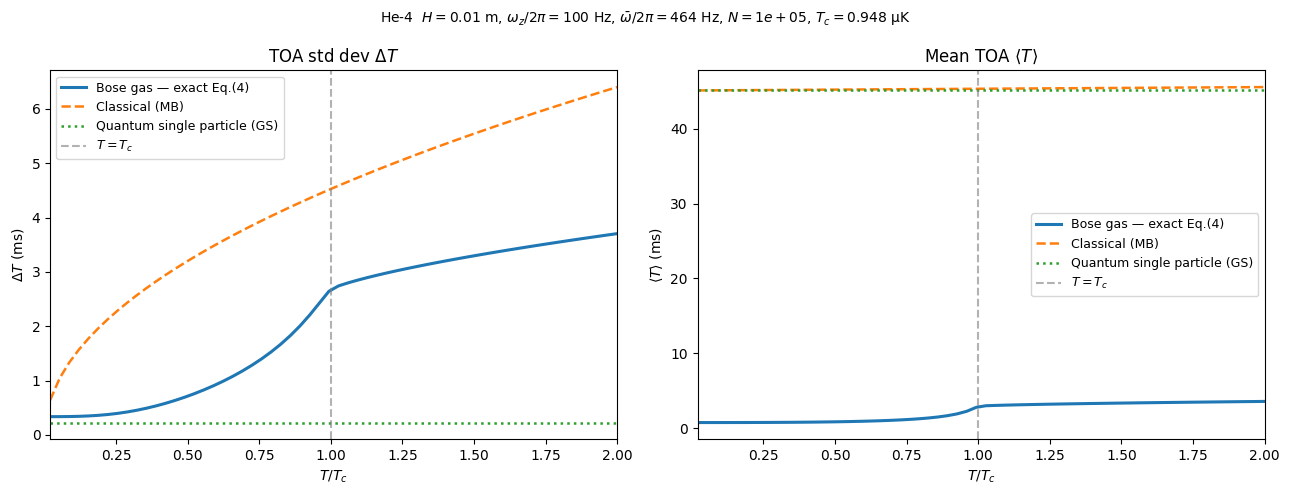

Done.


In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature — exact Eq.(4) + condensate below Tc
Matches parameters and equations from the two supervisor PDFs exactly.

Parameters (from instruction PDF):
  m = 6.64e-27 kg (He-4)
  H = 0.50 m
  omega_z/2pi = 100 Hz
  g = 9.81 m/s^2
  N = 1e5,  omega_x=omega_y = 2pi*1000 Hz

Key equation: Eq.(4) from draft paper
  rho_eq_perp(z_tilde) = sum_{j=1}^inf exp(j*beta*mu_tilde)
    * prod_{alpha=x,y} 1/(1-exp(-j*beta*hbar*omega_alpha))
    * 1/(sigma_z*sqrt(pi*(1-exp(-2*j*tau_z))))
    * exp(-tanh(j*tau_z/2) * z_tilde^2/sigma_z^2)
  where tau_z = beta*hbar*omega_z,  mu_tilde = mu - hbar*(wx+wy+wz)/2,
  z_tilde = (z - zc(t))/sqrt(1+omega_z^2*t^2)  evaluated at z=H (detector).

Eq.(3): J(H,t) = N * vz(t)/sqrt(1+omega_z^2*t^2) * rho_eq_perp(z_tilde(t))
  where z_tilde(t) = (H - zc(t))/sqrt(1+omega_z^2*t^2) = 0.5*g*t^2/sqrt(1+omega_z^2*t^2)

Outputs: <T>(T/Tc) and Delta_T(T/Tc)  [x-axis is T/Tc as in supervisor figures]
"""

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import brentq

# ──────────────────────────────────────────────
# Physical constants
# ──────────────────────────────────────────────
kB   = 1.380649e-23       # J/K
hbar = 1.054571817e-34    # J·s

# ──────────────────────────────────────────────
# System parameters  (from instruction PDF)
# ──────────────────────────────────────────────
m       = 6.64e-27        # kg  (He-4, as stated in PDF)
g       = 9.81            # m/s^2
H       = 0.01            # m   (PDF eq. 2)

omega_z = 2 * math.pi * 100.0    # rad/s  (PDF eq. 3)
omega_x = 2 * math.pi * 1000.0   # rad/s  (transverse, from paper body)
omega_y = 2 * math.pi * 1000.0   # rad/s

N_target = 1e5
npts     = 60     # temperature points along T/Tc axis
Nt       = 1201   # time-grid points

# ──────────────────────────────────────────────
# Derived constants
# ──────────────────────────────────────────────
tc         = math.sqrt(2.0 * H / g)                 # classical TOF (eq. 6)
sigma_z    = math.sqrt(hbar / (m * omega_z))          # HO length along z
sigmaV0_sq = hbar * omega_z / (2.0 * m)              # GS velocity variance (quantum)
pref_mean  = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

print(f"tc = {tc*1e3:.3f} ms,  sigma_z = {sigma_z*1e6:.3f} µm")

# ──────────────────────────────────────────────
# Time grid (built once, vectorised)
# ──────────────────────────────────────────────
# Range: slightly before tc to well past it
tmin_grid = 1e-4          # avoid t=0 singularity
tmax_grid = 3.0 * tc
t_grid    = np.linspace(tmin_grid, tmax_grid, Nt)

_oz2  = omega_z**2
_zc   = H - 0.5 * g * t_grid**2              # zc(t) = H - g*t^2/2
_denom= 1.0 + _oz2 * t_grid**2               # 1 + omega_z^2*t^2

# z_tilde at detector z=H:  (H - zc(t)) / sqrt(1+omega_z^2*t^2) = 0.5*g*t^2 / sqrt(...)
zt_vec  = (H - _zc) / np.sqrt(_denom)        # = 0.5*g*t^2 / sqrt(1+oz^2*t^2)
jac_vec = 1.0 / np.sqrt(_denom)              # 1/sqrt(1+omega_z^2*t^2)
z2_vec  = zt_vec**2                           # z_tilde^2

# vz(t) from paper eq. (1) evaluated at z=H:
vz_vec  = (1.0 / t_grid) * (H + 0.5*g*t_grid**2 - _zc / _denom)

# (condensate TOA no longer precomputed — included naturally via large-j terms in Eq.(4))


# ══════════════════════════════════════════════
# N_th_max(T): thermal occupation at mu_tilde=0
# = sum_{(nx,ny,nz)!=(0,0,0)} 1/(exp(beta*E_n)-1)
# where E_n = nx*hbar*wx + ny*hbar*wy + nz*hbar*wz  (excitation energies)
#
# Fast algorithm: analytically reduce nx,ny double-sum to k-series.
# For nz>0:  F(ez) = sum_k exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))]
# Total work O(log(1/bz)) instead of O(1/(bx*by*bz)).
# ══════════════════════════════════════════════

def _bose1d(b):
    """sum_{n=1}^inf 1/(exp(n*b)-1),  b > 0"""
    n_max = min(int(50.0 / b) + 2, 500000)
    ns = np.arange(1, n_max + 1, dtype=np.float64)
    return float(np.sum(1.0 / np.expm1(ns * b)))

def _F_ksum(ez, bx, by):
    """sum_{k>=1} exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))],  ez > 0"""
    k_max = min(int(50.0 / ez) + 2, 500000)
    ks  = np.arange(1, k_max + 1, dtype=np.float64)
    kez = ks * ez
    ks  = ks[kez < 50.0]
    terms = np.exp(-ks * ez) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_th_max_fast(T, tol=1e-10):
    """Max thermal N at mu_tilde=0 (excluding condensate GS)."""
    beta = 1.0 / (kB * T)
    bx = beta * hbar * omega_x
    by = beta * hbar * omega_y
    bz = beta * hbar * omega_z

    # nz=0, nx>0, ny=0
    S = _bose1d(bx)
    # nz=0, nx>=0, ny>=1  (k-sum shifted by 1 in ny)
    S += _F_ksum(by, bx, by)
    # nz>=1
    for nz in range(1, int(50.0 / bz) + 3):
        ez = nz * bz
        if ez > 50.0:
            break
        contrib = _F_ksum(ez, bx, by)
        S += contrib
        if nz > 5 and contrib < tol * max(1.0, S):
            break
    return S


# ──────────────────────────────────────────────
# Tc_exact: N_th_max_fast(Tc) = N_target
# (used only to locate Tc for the x-axis label and temperature sweep)
# ──────────────────────────────────────────────
def compute_Tc_exact(N_target):
    zeta3     = 1.20205690315959
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_approx = (hbar * omega_bar / kB) * (N_target / zeta3) ** (1.0/3.0)
    print(f"  Analytic Tc estimate: {Tc_approx*1e9:.1f} nK")

    f = lambda T: N_th_max_fast(T) - N_target
    T_lo, T_hi = 0.5 * Tc_approx, 2.0 * Tc_approx
    for _ in range(30):
        if f(T_lo) < 0: break
        T_lo *= 0.5
    for _ in range(30):
        if f(T_hi) > 0: break
        T_hi *= 2.0
    return brentq(f, T_lo, T_hi, xtol=1e-11 * Tc_approx, rtol=1e-9, maxiter=200)


# ──────────────────────────────────────────────
# Solve mu(T) for ANY temperature using full cluster sum Eq.(5)
# with j_max = N_target so that long-cycle (condensate) contributions
# are included. Below Tc, mu converges to a small negative value
# of order hbar*omega/N rather than exactly 0.
# ──────────────────────────────────────────────
def N_cluster_full(mu, T, j_max=None):
    """
    Cluster sum Eq.(5) summed to j_max ~ N.
    Includes condensate contribution via long permutation cycles j ~ N.
    """
    if j_max is None:
        j_max = int(N_target)   # long cycles up to order N
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z
    S    = 0.0
    chunk = 4096
    j = 1
    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)
        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej  = np.exp(np.clip(log_ej, -700, 0.0))
        dx  = -np.expm1(-js * bx)
        dy  = -np.expm1(-js * by)
        dz  = -np.expm1(-js * bz)
        term = ej / (dx * dy * dz)
        S   += float(term[np.isfinite(term)].sum())
        j    = j_end + 1
    return S

def solve_mu_full(T, N_target):
    """
    Solve N_cluster_full(mu, T) = N_target for mu.
    Works at all temperatures including below Tc.
    mu will be small but nonzero below Tc (of order hbar*omega/N).
    """
    f     = lambda mu: N_cluster_full(mu, T) - N_target
    mu_hi = -1e-50
    mu_lo = -50.0 * kB * T
    for _ in range(80):
        if f(mu_lo) < 0: break
        mu_lo *= 2.0
    return brentq(f, mu_lo, mu_hi, xtol=1e-50, rtol=1e-9, maxiter=300)


# ──────────────────────────────────────────────
# Eq.(4): thermal density at z_tilde on time grid
# rho_eq_perp(z_tilde) — uses mu_tilde < 0 (valid cluster expansion)
# ──────────────────────────────────────────────
def rho_thermal_on_tgrid(T, mu, tol_j=1e-8, j_max=None):
    """
    Evaluates Eq.(4) at z_tilde(t) for all t in t_grid.
    mu here is mu_tilde (measured from GS energy).
    j_max defaults to N_target so long-cycle (condensate) terms are included.
    """
    if j_max is None:
        j_max = int(N_target)
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z   # tau_z in paper notation

    rho   = np.zeros(Nt, dtype=np.float64)
    S_A   = 0.0
    j     = 1
    chunk = 2048

    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej = np.exp(np.clip(log_ej, -700, 0.0))

        # Eq.(4) coefficients for each j-term:
        omp_x  = -np.expm1(-js * bx)          # 1-exp(-j*tau_x)
        omp_y  = -np.expm1(-js * by)          # 1-exp(-j*tau_y)
        omp_2z = -np.expm1(-2.0 * js * bz)   # 1-exp(-2*j*tau_z)
        tanh_h = np.tanh(0.5 * js * bz)       # tanh(j*tau_z/2)

        # Amplitude: exp(j*beta*mu) / [(1-e^-j*bx)(1-e^-j*by) * sigma_z*sqrt(pi*(1-e^-2j*bz))]
        Aj = ej / (omp_x * omp_y * sigma_z * np.sqrt(np.pi * omp_2z))
        # Gaussian width: tanh(j*tau_z/2) / sigma_z^2
        Bj = tanh_h / sigma_z**2

        # rho += sum_j Aj * exp(-Bj * z_tilde^2)
        sub = 512
        for s in range(0, len(Aj), sub):
            a = Aj[s:s+sub]; b = Bj[s:s+sub]
            rho += (a[:, None] * np.exp(-b[:, None] * z2_vec[None, :])).sum(axis=0)

        S_A += float(Aj.sum())
        if j_end > 50 and float(abs(Aj[-1])) < tol_j * max(1.0, S_A):
            break
        j = j_end + 1

    return rho


# ──────────────────────────────────────────────
# TOA distribution and moments
# Unified approach: solve mu from Eq.(5) with j_max=N at ALL temperatures.
# Below Tc the condensate is encoded in long cycles j~N; mu converges to
# a small negative value ~hbar*omega/N rather than exactly 0.
# No manual BEC/thermal split — Eq.(4) summed to j_max=N gives everything.
# ──────────────────────────────────────────────
def toa_moments_bose(T, Tc_exact, N_target):
    # Single mu solve valid for all T, including below Tc
    mu = solve_mu_full(T, N_target)

    # Eq.(4) summed to j_max=N — condensate contribution in large-j terms
    rho = rho_thermal_on_tgrid(T, mu, tol_j=1e-8)
    Pi  = np.abs(vz_vec * jac_vec * rho)
    norm = simpson(Pi, x=t_grid)
    if norm > 0:
        Pi /= norm

    # Moments (Eqs. 8-9)
    mean  = simpson(t_grid    * Pi, x=t_grid)
    mean2 = simpson(t_grid**2 * Pi, x=t_grid)
    std   = math.sqrt(max(0.0, mean2 - mean**2))

    has_BEC = N_th_max_fast(T) < N_target
    return mean, std, norm, mu / (kB * T), has_BEC


# ──────────────────────────────────────────────
# Baselines (semiclassical, from supplementary)
# ──────────────────────────────────────────────
def DeltaT_classical(T):        return (1.0/g) * math.sqrt(kB*T/m)
def meanT_classical(T):         return tc + pref_mean * (kB*T/m)
def DeltaT_quantum_GS(_):       return (1.0/g) * math.sqrt(sigmaV0_sq)
def meanT_quantum_GS(_):        return tc + pref_mean * sigmaV0_sq


# ──────────────────────────────────────────────
# Main
# ──────────────────────────────────────────────
def main():
    import time
    t_start = time.time()

    print("Computing Tc_exact …")
    Tc_exact = compute_Tc_exact(N_target)
    print(f"  Tc_exact = {Tc_exact*1e9:.2f} nK = {Tc_exact*1e6:.4f} µK")
    print(f"  Verify: N_th_max(Tc) = {N_th_max_fast(Tc_exact):.4e}  (target = {N_target:.0e})\n")

    # Temperature axis: 0.02*Tc to 2*Tc  (per instruction PDF)
    Tmin = 0.02 * Tc_exact
    Tmax = 2.00 * Tc_exact
    Ts   = np.linspace(Tmin, Tmax, npts)

    mean_b  = np.zeros(npts)
    std_b   = np.zeros(npts)
    norms   = np.zeros(npts)
    frac_th = np.zeros(npts)

    print(f"{'i':>4}  {'T/Tc':>6}  {'<T>(ms)':>9}  {'DT(ms)':>9}  {'norm':>7}  {'mu/kBT':>10}  BEC")
    for i, T in enumerate(Ts):
        mT, sT, nr, mu_kbt, bec = toa_moments_bose(float(T), Tc_exact, N_target)
        mean_b[i]  = mT
        std_b[i]   = sT
        norms[i]   = nr
        frac_th[i] = mu_kbt
        if i % max(1, npts // 20) == 0 or i == npts - 1:
            print(f"{i:>4}  {T/Tc_exact:>6.3f}  "
                  f"{mT*1e3:>9.4f}  {sT*1e3:>9.4f}  {nr:>7.5f}  {mu_kbt:>10.6f}  "
                  f"{'YES' if bec else 'no'}")

    elapsed = time.time() - t_start
    print(f"\nNorm range: [{norms.min():.5f}, {norms.max():.5f}]")
    print(f"Total runtime: {elapsed:.1f} s")

    # x-axis: T/Tc  (dimensionless, matching supervisor figures)
    T_over_Tc = Ts / Tc_exact
    mean_cl   = np.array([meanT_classical(T)   for T in Ts])
    std_cl    = np.array([DeltaT_classical(T)  for T in Ts])
    mean_q1   = np.array([meanT_quantum_GS(T)  for T in Ts])
    std_q1    = np.array([DeltaT_quantum_GS(T) for T in Ts])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    ax.plot(T_over_Tc, std_b*1e3,  lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, std_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, std_q1*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\Delta T$ (ms)")
    ax.set_title(r"TOA std dev $\Delta T$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    ax = axes[1]
    ax.plot(T_over_Tc, mean_b*1e3,  lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, mean_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, mean_q1*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\langle T \rangle$ (ms)")
    ax.set_title(r"Mean TOA $\langle T \rangle$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    fig.suptitle(
        rf"He-4  $H={H}$ m, $\omega_z/2\pi={omega_z/(2*math.pi):.0f}$ Hz, "
        rf"$\bar{{\omega}}/2\pi={omega_bar/(2*math.pi):.0f}$ Hz, "
        rf"$N={N_target:.0e}$, $T_c={Tc_exact*1e6:.3f}$ µK",
        fontsize=10,
    )
    fig.tight_layout()
    plt.show()
    print("Done.")


if __name__ == "__main__":
    main()

tc = 45.152 ms,  sigma_z = 5.028 µm
Computing Tc_exact …
  Analytic Tc estimate: 972.4 nK
  Tc_exact = 947.94 nK = 0.9479 µK
  Verify: N_th_max(Tc) = 1.0000e+05  (target = 1e+05)

   i    T/Tc    <T>(ms)     DT(ms)     norm      mu/kBT  BEC
   0   0.020     0.7307     0.3360  17697470.56177   -0.000000  YES
   3   0.121     0.7326     0.3424  17676073.89588   -0.000000  YES
   6   0.221     0.7403     0.3756  17571649.35148   -0.000000  YES
   9   0.322     0.7579     0.4536  17308433.41671   -0.000001  YES
  12   0.423     0.7902     0.5816  16806099.16716   -0.000002  YES
  15   0.523     0.8443     0.7588  15981706.14771   -0.000003  YES
  18   0.624     0.9320     0.9886  14750544.46139   -0.000006  YES
  21   0.725     1.0773     1.2832  13026605.33010   -0.000011  YES
  24   0.825     1.3372     1.6712  10722895.57027   -0.000020  YES
  27   0.926     1.8896     2.2062  7751837.47334   -0.000049  YES
  30   1.027     2.9786     2.7419  4941432.71729   -0.053169  no
  33   1.127  

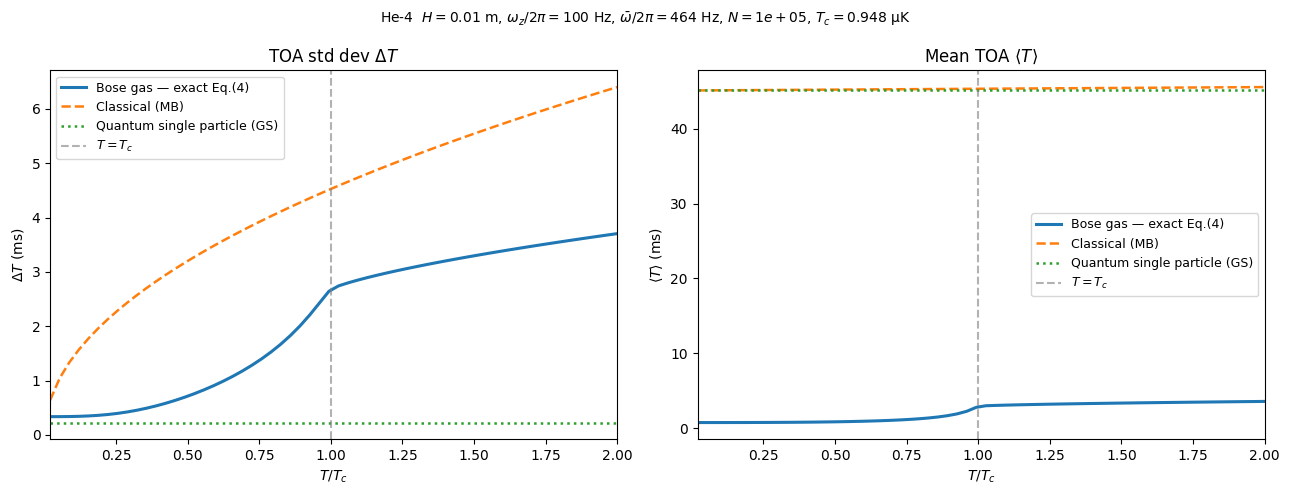

Done.


In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature — exact Eq.(4) + condensate below Tc
Matches parameters and equations from the two supervisor PDFs exactly.

Parameters (from instruction PDF):
  m = 6.64e-27 kg (He-4)
  H = 0.50 m
  omega_z/2pi = 100 Hz
  g = 9.81 m/s^2
  N = 1e5,  omega_x=omega_y = 2pi*1000 Hz

Key equation: Eq.(4) from draft paper
  rho_eq_perp(z_tilde) = sum_{j=1}^inf exp(j*beta*mu_tilde)
    * prod_{alpha=x,y} 1/(1-exp(-j*beta*hbar*omega_alpha))
    * 1/(sigma_z*sqrt(pi*(1-exp(-2*j*tau_z))))
    * exp(-tanh(j*tau_z/2) * z_tilde^2/sigma_z^2)
  where tau_z = beta*hbar*omega_z,  mu_tilde = mu - hbar*(wx+wy+wz)/2,
  z_tilde = (z - zc(t))/sqrt(1+omega_z^2*t^2)  evaluated at z=H (detector).

Eq.(3): J(H,t) = N * vz(t)/sqrt(1+omega_z^2*t^2) * rho_eq_perp(z_tilde(t))
  where z_tilde(t) = (H - zc(t))/sqrt(1+omega_z^2*t^2) = 0.5*g*t^2/sqrt(1+omega_z^2*t^2)

Outputs: <T>(T/Tc) and Delta_T(T/Tc)  [x-axis is T/Tc as in supervisor figures]
"""

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import brentq

# ──────────────────────────────────────────────
# Physical constants
# ──────────────────────────────────────────────
kB   = 1.380649e-23       # J/K
hbar = 1.054571817e-34    # J·s

# ──────────────────────────────────────────────
# System parameters  (from instruction PDF)
# ──────────────────────────────────────────────
m       = 6.64e-27        # kg  (He-4, as stated in PDF)
g       = 9.81            # m/s^2
H       = 0.01            # m   (PDF eq. 2)

omega_z = 2 * math.pi * 100.0    # rad/s  (PDF eq. 3)
omega_x = 2 * math.pi * 1000.0   # rad/s  (transverse, from paper body)
omega_y = 2 * math.pi * 1000.0   # rad/s

N_target = 1e5
npts     = 60     # temperature points along T/Tc axis
Nt       = 1201   # time-grid points

# ──────────────────────────────────────────────
# Derived constants
# ──────────────────────────────────────────────
tc         = math.sqrt(2.0 * H / g)                 # classical TOF (eq. 6)
sigma_z    = math.sqrt(hbar / (m * omega_z))          # HO length along z
sigmaV0_sq = hbar * omega_z / (2.0 * m)              # GS velocity variance (quantum)
pref_mean  = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

print(f"tc = {tc*1e3:.3f} ms,  sigma_z = {sigma_z*1e6:.3f} µm")

# ──────────────────────────────────────────────
# Time grid (built once, vectorised)
# ──────────────────────────────────────────────
# Range: slightly before tc to well past it
tmin_grid = 1e-4          # avoid t=0 singularity
tmax_grid = 3.0 * tc
t_grid    = np.linspace(tmin_grid, tmax_grid, Nt)

_oz2  = omega_z**2
_zc   = H - 0.5 * g * t_grid**2              # zc(t) = H - g*t^2/2
_denom= 1.0 + _oz2 * t_grid**2               # 1 + omega_z^2*t^2

# z_tilde at detector z=H:  (H - zc(t)) / sqrt(1+omega_z^2*t^2) = 0.5*g*t^2 / sqrt(...)
zt_vec  = (H - _zc) / np.sqrt(_denom)        # = 0.5*g*t^2 / sqrt(1+oz^2*t^2)
jac_vec = 1.0 / np.sqrt(_denom)              # 1/sqrt(1+omega_z^2*t^2)
z2_vec  = zt_vec**2                           # z_tilde^2

# vz(t) from paper eq. (1) evaluated at z=H:
vz_vec  = (1.0 / t_grid) * (H + 0.5*g*t_grid**2 - _zc / _denom)

# (condensate TOA no longer precomputed — included naturally via large-j terms in Eq.(4))


# ══════════════════════════════════════════════
# N_th_max(T): thermal occupation at mu_tilde=0
# = sum_{(nx,ny,nz)!=(0,0,0)} 1/(exp(beta*E_n)-1)
# where E_n = nx*hbar*wx + ny*hbar*wy + nz*hbar*wz  (excitation energies)
#
# Fast algorithm: analytically reduce nx,ny double-sum to k-series.
# For nz>0:  F(ez) = sum_k exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))]
# Total work O(log(1/bz)) instead of O(1/(bx*by*bz)).
# ══════════════════════════════════════════════

def _bose1d(b):
    """sum_{n=1}^inf 1/(exp(n*b)-1),  b > 0"""
    n_max = min(int(50.0 / b) + 2, 500000)
    ns = np.arange(1, n_max + 1, dtype=np.float64)
    return float(np.sum(1.0 / np.expm1(ns * b)))

def _F_ksum(ez, bx, by):
    """sum_{k>=1} exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))],  ez > 0"""
    k_max = min(int(50.0 / ez) + 2, 500000)
    ks  = np.arange(1, k_max + 1, dtype=np.float64)
    kez = ks * ez
    ks  = ks[kez < 50.0]
    terms = np.exp(-ks * ez) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_th_max_fast(T, tol=1e-10):
    """Max thermal N at mu_tilde=0 (excluding condensate GS)."""
    beta = 1.0 / (kB * T)
    bx = beta * hbar * omega_x
    by = beta * hbar * omega_y
    bz = beta * hbar * omega_z

    # nz=0, nx>0, ny=0
    S = _bose1d(bx)
    # nz=0, nx>=0, ny>=1  (k-sum shifted by 1 in ny)
    S += _F_ksum(by, bx, by)
    # nz>=1
    for nz in range(1, int(50.0 / bz) + 3):
        ez = nz * bz
        if ez > 50.0:
            break
        contrib = _F_ksum(ez, bx, by)
        S += contrib
        if nz > 5 and contrib < tol * max(1.0, S):
            break
    return S


# ──────────────────────────────────────────────
# Tc_exact: N_th_max_fast(Tc) = N_target
# (used only to locate Tc for the x-axis label and temperature sweep)
# ──────────────────────────────────────────────
def compute_Tc_exact(N_target):
    zeta3     = 1.20205690315959
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_approx = (hbar * omega_bar / kB) * (N_target / zeta3) ** (1.0/3.0)
    print(f"  Analytic Tc estimate: {Tc_approx*1e9:.1f} nK")

    f = lambda T: N_th_max_fast(T) - N_target
    T_lo, T_hi = 0.5 * Tc_approx, 2.0 * Tc_approx
    for _ in range(30):
        if f(T_lo) < 0: break
        T_lo *= 0.5
    for _ in range(30):
        if f(T_hi) > 0: break
        T_hi *= 2.0
    return brentq(f, T_lo, T_hi, xtol=1e-11 * Tc_approx, rtol=1e-9, maxiter=200)


# ──────────────────────────────────────────────
# Solve mu(T) for ANY temperature using full cluster sum Eq.(5)
# with j_max = N_target so that long-cycle (condensate) contributions
# are included. Below Tc, mu converges to a small negative value
# of order hbar*omega/N rather than exactly 0.
# ──────────────────────────────────────────────
def N_cluster_full(mu, T, j_max=None):
    """
    Cluster sum Eq.(5) summed to j_max ~ N.
    Includes condensate contribution via long permutation cycles j ~ N.
    """
    if j_max is None:
        j_max = int(N_target)   # long cycles up to order N
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z
    S    = 0.0
    chunk = 4096
    j = 1
    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)
        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej  = np.exp(np.clip(log_ej, -700, 0.0))
        dx  = -np.expm1(-js * bx)
        dy  = -np.expm1(-js * by)
        dz  = -np.expm1(-js * bz)
        term = ej / (dx * dy * dz)
        S   += float(term[np.isfinite(term)].sum())
        j    = j_end + 1
    return S

def solve_mu_full(T, N_target):
    """
    Solve N_cluster_full(mu, T) = N_target for mu.
    Works at all temperatures including below Tc.
    mu will be small but nonzero below Tc (of order hbar*omega/N).
    """
    f     = lambda mu: N_cluster_full(mu, T) - N_target
    mu_hi = -1e-50
    mu_lo = -50.0 * kB * T
    for _ in range(80):
        if f(mu_lo) < 0: break
        mu_lo *= 2.0
    return brentq(f, mu_lo, mu_hi, xtol=1e-50, rtol=1e-9, maxiter=300)


# ──────────────────────────────────────────────
# Eq.(4): thermal density at z_tilde on time grid
# rho_eq_perp(z_tilde) — uses mu_tilde < 0 (valid cluster expansion)
# ──────────────────────────────────────────────
def rho_thermal_on_tgrid(T, mu, tol_j=1e-8, j_max=None):
    """
    Evaluates Eq.(4) at z_tilde(t) for all t in t_grid.
    mu here is mu_tilde (measured from GS energy).
    j_max defaults to N_target so long-cycle (condensate) terms are included.
    """
    if j_max is None:
        j_max = int(N_target)
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z   # tau_z in paper notation

    rho   = np.zeros(Nt, dtype=np.float64)
    S_A   = 0.0
    j     = 1
    chunk = 2048

    while j <= j_max:
        j_end = min(j + chunk - 1, j_max)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej = np.exp(np.clip(log_ej, -700, 0.0))

        # Eq.(4) coefficients for each j-term:
        omp_x  = -np.expm1(-js * bx)          # 1-exp(-j*tau_x)
        omp_y  = -np.expm1(-js * by)          # 1-exp(-j*tau_y)
        omp_2z = -np.expm1(-2.0 * js * bz)   # 1-exp(-2*j*tau_z)
        tanh_h = np.tanh(0.5 * js * bz)       # tanh(j*tau_z/2)

        # Amplitude: exp(j*beta*mu) / [(1-e^-j*bx)(1-e^-j*by) * sigma_z*sqrt(pi*(1-e^-2j*bz))]
        Aj = ej / (omp_x * omp_y * sigma_z * np.sqrt(np.pi * omp_2z))
        # Gaussian width: tanh(j*tau_z/2) / sigma_z^2
        Bj = tanh_h / sigma_z**2

        # rho += sum_j Aj * exp(-Bj * z_tilde^2)
        sub = 512
        for s in range(0, len(Aj), sub):
            a = Aj[s:s+sub]; b = Bj[s:s+sub]
            rho += (a[:, None] * np.exp(-b[:, None] * z2_vec[None, :])).sum(axis=0)

        S_A += float(Aj.sum())
        if j_end > 50 and float(abs(Aj[-1])) < tol_j * max(1.0, S_A):
            break
        j = j_end + 1

    return rho


# ──────────────────────────────────────────────
# TOA distribution and moments
# Unified approach: solve mu from Eq.(5) with j_max=N at ALL temperatures.
# Below Tc the condensate is encoded in long cycles j~N; mu converges to
# a small negative value ~hbar*omega/N rather than exactly 0.
# No manual BEC/thermal split — Eq.(4) summed to j_max=N gives everything.
# ──────────────────────────────────────────────
def toa_moments_bose(T, Tc_exact, N_target):
    # Single mu solve valid for all T, including below Tc
    mu = solve_mu_full(T, N_target)

    # Eq.(4) summed to j_max=N — condensate contribution in large-j terms
    rho = rho_thermal_on_tgrid(T, mu, tol_j=1e-8)
    Pi  = np.abs(vz_vec * jac_vec * rho)
    norm = simpson(Pi, x=t_grid)
    if norm > 0:
        Pi /= norm

    # Moments (Eqs. 8-9)
    mean  = simpson(t_grid    * Pi, x=t_grid)
    mean2 = simpson(t_grid**2 * Pi, x=t_grid)
    std   = math.sqrt(max(0.0, mean2 - mean**2))

    has_BEC = N_th_max_fast(T) < N_target
    return mean, std, norm, mu / (kB * T), has_BEC


# ──────────────────────────────────────────────
# Baselines (semiclassical, from supplementary)
# ──────────────────────────────────────────────
def DeltaT_classical(T):        return (1.0/g) * math.sqrt(kB*T/m)
def meanT_classical(T):         return tc + pref_mean * (kB*T/m)
def DeltaT_quantum_GS(_):       return (1.0/g) * math.sqrt(sigmaV0_sq)
def meanT_quantum_GS(_):        return tc + pref_mean * sigmaV0_sq


# ──────────────────────────────────────────────
# Main
# ──────────────────────────────────────────────
def main():
    import time
    t_start = time.time()

    print("Computing Tc_exact …")
    Tc_exact = compute_Tc_exact(N_target)
    print(f"  Tc_exact = {Tc_exact*1e9:.2f} nK = {Tc_exact*1e6:.4f} µK")
    print(f"  Verify: N_th_max(Tc) = {N_th_max_fast(Tc_exact):.4e}  (target = {N_target:.0e})\n")

    # Temperature axis: 0.02*Tc to 2*Tc  (per instruction PDF)
    Tmin = 0.02 * Tc_exact
    Tmax = 2.00 * Tc_exact
    Ts   = np.linspace(Tmin, Tmax, npts)

    mean_b  = np.zeros(npts)
    std_b   = np.zeros(npts)
    norms   = np.zeros(npts)
    frac_th = np.zeros(npts)

    print(f"{'i':>4}  {'T/Tc':>6}  {'<T>(ms)':>9}  {'DT(ms)':>9}  {'norm':>7}  {'mu/kBT':>10}  BEC")
    for i, T in enumerate(Ts):
        mT, sT, nr, mu_kbt, bec = toa_moments_bose(float(T), Tc_exact, N_target)
        mean_b[i]  = mT
        std_b[i]   = sT
        norms[i]   = nr
        frac_th[i] = mu_kbt
        if i % max(1, npts // 20) == 0 or i == npts - 1:
            print(f"{i:>4}  {T/Tc_exact:>6.3f}  "
                  f"{mT*1e3:>9.4f}  {sT*1e3:>9.4f}  {nr:>7.5f}  {mu_kbt:>10.6f}  "
                  f"{'YES' if bec else 'no'}")

    elapsed = time.time() - t_start
    print(f"\nNorm range: [{norms.min():.5f}, {norms.max():.5f}]")
    print(f"Total runtime: {elapsed:.1f} s")

    # x-axis: T/Tc  (dimensionless, matching supervisor figures)
    T_over_Tc = Ts / Tc_exact
    mean_cl   = np.array([meanT_classical(T)   for T in Ts])
    std_cl    = np.array([DeltaT_classical(T)  for T in Ts])
    mean_q1   = np.array([meanT_quantum_GS(T)  for T in Ts])
    std_q1    = np.array([DeltaT_quantum_GS(T) for T in Ts])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    ax.plot(T_over_Tc, std_b*1e3,  lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, std_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, std_q1*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\Delta T$ (ms)")
    ax.set_title(r"TOA std dev $\Delta T$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    ax = axes[1]
    ax.plot(T_over_Tc, mean_b*1e3,  lw=2.2,          label="Bose gas — exact Eq.(4)")
    ax.plot(T_over_Tc, mean_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_over_Tc, mean_q1*1e3, lw=1.8, ls=":",  label="Quantum single particle (GS)")
    ax.axvline(1.0, ls="--", color="gray", alpha=0.6, label=r"$T = T_c$")
    ax.set_xlabel(r"$T / T_c$")
    ax.set_ylabel(r"$\langle T \rangle$ (ms)")
    ax.set_title(r"Mean TOA $\langle T \rangle$")
    ax.legend(fontsize=9)
    ax.set_xlim(T_over_Tc[0], T_over_Tc[-1])

    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    fig.suptitle(
        rf"He-4  $H={H}$ m, $\omega_z/2\pi={omega_z/(2*math.pi):.0f}$ Hz, "
        rf"$\bar{{\omega}}/2\pi={omega_bar/(2*math.pi):.0f}$ Hz, "
        rf"$N={N_target:.0e}$, $T_c={Tc_exact*1e6:.3f}$ µK",
        fontsize=10,
    )
    fig.tight_layout()
    plt.show()
    print("Done.")


if __name__ == "__main__":
    main()

# TOA Plots Feb 27

Computing Tc_exact …
  Analytic Tc estimate: 972.4 nK
  Tc_exact = 947.94 nK = 0.9479 µK
  Verify: N_th_max(Tc) = 1.0000e+05  (target = 1e+05)

   i     T(nK)    T/Tc    <T>(ms)     DT(ms)     norm    Nth/N  BEC
   0      47.4   0.050    45.1529     0.2278  1.00000   0.0005  YES
   4     172.7   0.182    45.1529     0.2279  1.00000   0.0087  YES
   8     298.0   0.314    45.1530     0.2310  1.00000   0.0371  YES
  12     423.4   0.447    45.1531     0.2586  1.00000   0.0984  YES
  16     548.7   0.579    45.1539     0.3685  1.00000   0.2056  YES
  20     674.0   0.711    45.1565     0.6168  1.00000   0.3713  YES
  24     799.3   0.843    45.1639     1.0297  1.00000   0.6085  YES
  28     924.6   0.975    45.1811     1.6248  1.00000   0.9299  YES
  32    1050.0   1.108    45.3833     4.6026  1.00000   1.0000  no
  36    1175.3   1.240    45.4173     4.9337  1.00000   1.0000  no
  40    1300.6   1.372    45.4495     5.2293  1.00000   1.0000  no
  44    1425.9   1.504    45.4808     5.502

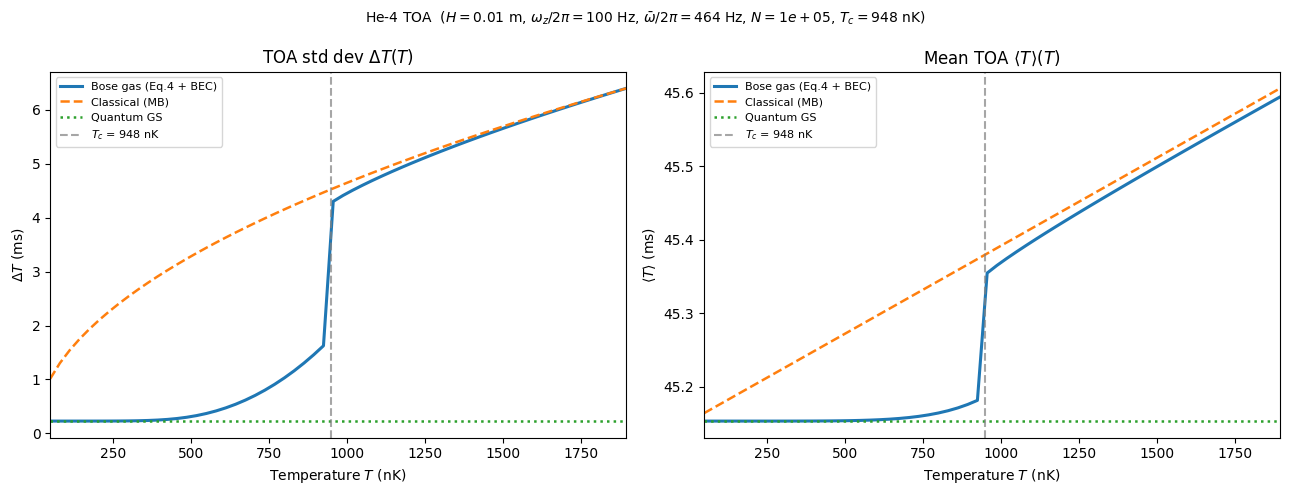

Done


In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature — EXACT Eq.(4) + condensate below Tc
Runtime: ~1-3 minutes for npts=60.

Physics fixes:
  1. N_th_max(T) via SINGLE-PARTICLE occupation sum (not cluster sum at mu=0,
     which diverges for the harmonic trap — large-j terms → 1).
  2. Tc_exact self-consistent: N_th_max_occ(Tc) = N_target.
  3. Below Tc: Pi(t) = (N_th/N)*Pi_thermal[Eq.4] + (N0/N)*Pi_condensate[GS Gaussian].
  4. All moments via Simpson integration.

Speed fix:
  N_th_max uses analytic nx,ny reduction:
    F(ez) = sum_k exp(-k*ez) / [(1-exp(-k*bx))*(1-exp(-k*by))]
  reducing O(nz*nx*ny) triple loop → O(nz * k_max/nz) ~ O(const) single loop,
  making each N_th_max call ~35 ms instead of ~30 s.
"""

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.optimize import brentq

# ──────────────────────────────────────────────
# Physical constants
# ──────────────────────────────────────────────
kB   = 1.380649e-23
hbar = 1.054571817e-34
m_u  = 1.66053906660e-27

# ──────────────────────────────────────────────
# System parameters
# ──────────────────────────────────────────────
m       = 4.0 * m_u
g       = 9.81            # Earth gravity [m/s^2]
H       = 0.01            # Detector height [m]

omega_z = 2 * math.pi * 100.0    # [rad/s]
omega_x = 2 * math.pi * 1000.0
omega_y = 2 * math.pi * 1000.0

N_target = 1e5
npts     = 60     # temperature points
Nt       = 1201   # time-grid points

# ──────────────────────────────────────────────
# Derived constants
# ──────────────────────────────────────────────
tc         = math.sqrt(2.0 * H / g)
sigma_z    = math.sqrt(hbar / (m * omega_z))
sigmaV0_sq = hbar * omega_z / (2.0 * m)
pref_mean  = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ──────────────────────────────────────────────
# Time grid (built once)
# ──────────────────────────────────────────────
tmin_grid = 1e-6
tmax_grid = 4.0 * tc
t_grid    = np.linspace(tmin_grid, tmax_grid, Nt)

_oz2    = omega_z**2
_zc     = H - 0.5 * g * t_grid**2
_sc     = 1.0 / np.sqrt(1.0 + _oz2 * t_grid**2)
zt_vec  = _zc * _sc
jac_vec = _sc
vz_vec  = (1.0 / t_grid) * (H + 0.5*g*t_grid**2 - _zc / (1.0 + _oz2*t_grid**2))
z2_vec  = zt_vec**2

# ──────────────────────────────────────────────
# Pre-compute normalised condensate TOA (GS Gaussian)
# ──────────────────────────────────────────────
_rho_cond    = np.exp(-z2_vec / sigma_z**2) / (sigma_z * math.sqrt(math.pi))
_Pi_cond_raw = np.abs(vz_vec * jac_vec * _rho_cond)
Pi_cond_norm = _Pi_cond_raw / simpson(_Pi_cond_raw, x=t_grid)


# ══════════════════════════════════════════════
# FAST N_th_max via analytic nx,ny reduction
# ══════════════════════════════════════════════
#
# N_th_max(T) = sum_{(nx,ny,nz)!=(0,0,0)} 1/(exp(beta*E_n) - 1)
#   where E_n = nx*hbar*wx + ny*hbar*wy + nz*hbar*wz
#
# For nz=0: split off nx=0,ny>0 and nx>0,ny>=0
# For nz>0: F(ez) = sum_k exp(-k*ez)/[(1-exp(-k*bx))*(1-exp(-k*by))]
#
# This collapses the O(nz*nx*ny) triple loop to a single loop over nz
# (with a k-sum inner loop that converges in O(1/ez) ~ O(1/nz) steps total).

def _bose1d(b):
    """sum_{n=1}^inf 1/(exp(n*b)-1)  for b > 0"""
    n_max = min(int(50.0 / b) + 2, 500000)
    ns = np.arange(1, n_max + 1, dtype=np.float64)
    return float(np.sum(1.0 / np.expm1(ns * b)))

def _F_ksum(ez, bx, by):
    """sum_{k=1}^inf exp(-k*ez) / [(1-exp(-k*bx))*(1-exp(-k*by))],  ez > 0"""
    k_max = min(int(50.0 / ez) + 2, 500000)
    ks    = np.arange(1, k_max + 1, dtype=np.float64)
    kez   = ks * ez
    mask  = kez < 50.0
    ks    = ks[mask]
    terms = np.exp(-ks * ez) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_th_max_fast(T, tol=1e-10):
    """
    Thermal particle number at mu=0 (max thermal pop.), excluding GS.
    Uses analytic reduction to 1D nz-loop + k-sums.
    """
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z

    # nz=0, nx>0, ny=0: sum_{nx=1}^inf 1/(exp(nx*bx)-1)
    S = _bose1d(bx)
    # nz=0, nx>=0, ny>=1: F_ksum with ez=by (shifts ny sum by 1)
    S += _F_ksum(by, bx, by)
    # nz>=1: full 2D (nx,ny>=0) sum via k-reduction
    nz_max = int(50.0 / bz) + 2
    for nz in range(1, nz_max + 1):
        ez = nz * bz
        if ez > 50.0:
            break
        contrib = _F_ksum(ez, bx, by)
        S += contrib
        if nz > 5 and contrib < tol * max(1.0, S):
            break
    return S


# ══════════════════════════════════════════════
# N(mu, T) for mu < 0  (T > Tc)
# Uses same k-sum reduction with chemical potential shift.
# ══════════════════════════════════════════════

def _F_ksum_mu(ez, bx, by, bmu):
    """
    sum_{nx>=0, ny>=0} 1/(exp(nx*bx + ny*by + ez - bmu) - 1),  ez-bmu > 0
    = sum_k exp(-k*(ez-bmu)) / [(1-exp(-k*bx))*(1-exp(-k*by))]
    """
    c     = ez - bmu        # > 0 (since mu <= 0)
    k_max = min(int(50.0 / c) + 2, 500000)
    ks    = np.arange(1, k_max + 1, dtype=np.float64)
    kc    = ks * c
    mask  = kc < 50.0
    ks    = ks[mask]
    terms = np.exp(-ks * c) / ((-np.expm1(-ks * bx)) * (-np.expm1(-ks * by)))
    return float(terms[np.isfinite(terms)].sum())

def N_occ_fast(mu, T, tol=1e-10):
    """Total N(mu, T), all states, mu <= 0."""
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z
    bmu  = beta * mu   # <= 0

    # nz=0 contribution (all nx,ny including GS)
    S = _F_ksum_mu(0.0 - bmu, bx, by, 0.0)   # ez=0, shift = -bmu > 0
    # nz>=1
    nz_max = int(50.0 / bz) + 2
    for nz in range(1, nz_max + 1):
        ez = nz * bz
        c  = ez - bmu
        if c > 50.0 and nz > 1:
            break
        contrib = _F_ksum_mu(ez, bx, by, bmu)
        S += contrib
        if nz > 5 and contrib < tol * max(1.0, S):
            break
    return S


# ──────────────────────────────────────────────
# Find Tc_exact
# ──────────────────────────────────────────────
def compute_Tc_exact(N_target):
    zeta3     = 1.20205690315959
    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    Tc_approx = (hbar * omega_bar / kB) * (N_target / zeta3) ** (1.0/3.0)
    print(f"  Analytic Tc estimate: {Tc_approx*1e9:.1f} nK")

    f = lambda T: N_th_max_fast(T) - N_target

    T_lo, T_hi = 0.5 * Tc_approx, 2.0 * Tc_approx
    for _ in range(30):
        if f(T_lo) < 0: break
        T_lo *= 0.5
    for _ in range(30):
        if f(T_hi) > 0: break
        T_hi *= 2.0

    return brentq(f, T_lo, T_hi, xtol=1e-11 * Tc_approx, rtol=1e-9, maxiter=200)


# ──────────────────────────────────────────────
# Solve mu(T) for T > Tc
# ──────────────────────────────────────────────
def solve_mu_above_Tc(T, N_target):
    f     = lambda mu: N_occ_fast(mu, T) - N_target
    mu_hi = -1e-40
    mu_lo = -50.0 * kB * T
    for _ in range(80):
        if f(mu_lo) < 0: break
        mu_lo *= 2.0
    return brentq(f, mu_lo, mu_hi, xtol=1e-40, rtol=1e-9, maxiter=200)


# ──────────────────────────────────────────────
# Eq.(4) thermal density on time grid
# (cluster expansion, valid for mu < 0)
# ──────────────────────────────────────────────
def rho_thermal_on_tgrid(T, mu, tol_j=1e-10):
    beta = 1.0 / (kB * T)
    bx   = beta * hbar * omega_x
    by   = beta * hbar * omega_y
    bz   = beta * hbar * omega_z

    rho   = np.zeros(Nt, dtype=np.float64)
    S_A   = 0.0
    j     = 1
    chunk = 2048

    while j <= 500000:
        j_end = min(j + chunk - 1, 500000)
        js    = np.arange(j, j_end + 1, dtype=np.float64)

        log_ej = js * (beta * mu)
        if log_ej[0] < -700:
            break
        ej = np.exp(np.clip(log_ej, -700, 0.0))

        omp_x   = -np.expm1(-js * bx)
        omp_y   = -np.expm1(-js * by)
        omp_2z  = -np.expm1(-2.0 * js * bz)
        tanh_jb = np.tanh(0.5 * js * bz)

        Aj = ej / (omp_x * omp_y * sigma_z * np.sqrt(np.pi * omp_2z))
        Bj = tanh_jb / sigma_z**2

        sub = 512
        for s in range(0, len(Aj), sub):
            a = Aj[s:s+sub]; b = Bj[s:s+sub]
            rho += (a[:, None] * np.exp(-b[:, None] * z2_vec[None, :])).sum(axis=0)

        S_A += float(Aj.sum())
        if j_end > 50 and abs(Aj[-1]) < tol_j * max(1.0, S_A):
            break
        j = j_end + 1

    return rho


# ──────────────────────────────────────────────
# TOA moments for Bose gas
# ──────────────────────────────────────────────
def toa_moments_bose(T, Tc_exact, N_target, tol_j=1e-10):
    N_th_max = N_th_max_fast(T)

    if N_target <= N_th_max:          # T >= Tc
        has_BEC = False
        mu      = solve_mu_above_Tc(T, N_target)
        N_th    = N_target
        N0      = 0.0
    else:                             # T < Tc
        has_BEC = True
        mu      = -1e-40              # effectively 0^-
        N_th    = N_th_max
        N0      = N_target - N_th

    w_th  = N_th / N_target
    w_BEC = N0   / N_target

    rho_th = rho_thermal_on_tgrid(T, mu, tol_j=tol_j)
    Pi_th  = np.abs(vz_vec * jac_vec * rho_th)
    Z_th   = simpson(Pi_th, x=t_grid)
    if Z_th > 0:
        Pi_th /= Z_th

    Pi   = w_th * Pi_th + w_BEC * Pi_cond_norm
    norm = simpson(Pi, x=t_grid)
    if norm > 0:
        Pi /= norm

    mean  = simpson(t_grid    * Pi, x=t_grid)
    mean2 = simpson(t_grid**2 * Pi, x=t_grid)
    std   = math.sqrt(max(0.0, mean2 - mean**2))

    return mean, std, norm, N_th / N_target, has_BEC


# ──────────────────────────────────────────────
# Baselines
# ──────────────────────────────────────────────
def DeltaT_classical(T):        return (1.0 / g) * math.sqrt(kB * T / m)
def meanT_classical(T):         return tc + pref_mean * (kB * T / m)
def DeltaT_single_particle(_):  return (1.0 / g) * math.sqrt(sigmaV0_sq)
def meanT_single_particle(_):   return tc + pref_mean * sigmaV0_sq


# ──────────────────────────────────────────────
# Main
# ──────────────────────────────────────────────
def main():
    import time
    t_start = time.time()

    print("Computing Tc_exact …")
    Tc_exact = compute_Tc_exact(N_target)
    print(f"  Tc_exact = {Tc_exact*1e9:.2f} nK = {Tc_exact*1e6:.4f} µK")
    print(f"  Verify: N_th_max(Tc) = {N_th_max_fast(Tc_exact):.4e}  (target = {N_target:.0e})\n")

    Tmin = 0.05 * Tc_exact
    Tmax = 2.00 * Tc_exact
    Ts   = np.linspace(Tmin, Tmax, npts)

    mean_b  = np.zeros(npts)
    std_b   = np.zeros(npts)
    norms   = np.zeros(npts)
    frac_th = np.zeros(npts)

    print(f"{'i':>4}  {'T(nK)':>8}  {'T/Tc':>6}  {'<T>(ms)':>9}  {'DT(ms)':>9}  "
          f"{'norm':>7}  {'Nth/N':>7}  BEC")
    for i, T in enumerate(Ts):
        mT, sT, nr, fth, bec = toa_moments_bose(float(T), Tc_exact, N_target)
        mean_b[i]  = mT
        std_b[i]   = sT
        norms[i]   = nr
        frac_th[i] = fth
        if i % max(1, npts // 15) == 0 or i == npts - 1:
            print(f"{i:>4}  {T*1e9:>8.1f}  {T/Tc_exact:>6.3f}  "
                  f"{mT*1e3:>9.4f}  {sT*1e3:>9.4f}  {nr:>7.5f}  {fth:>7.4f}  "
                  f"{'YES' if bec else 'no'}")

    elapsed = time.time() - t_start
    print(f"\nNorm range: [{norms.min():.5f}, {norms.max():.5f}]")
    print(f"Total runtime: {elapsed:.1f} s")

    T_nK    = Ts * 1e9
    Tc_nK   = Tc_exact * 1e9
    mean_cl = np.array([meanT_classical(T)        for T in Ts])
    std_cl  = np.array([DeltaT_classical(T)       for T in Ts])
    mean_q1 = np.array([meanT_single_particle(T)  for T in Ts])
    std_q1  = np.array([DeltaT_single_particle(T) for T in Ts])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    ax = axes[0]
    ax.plot(T_nK, std_b*1e3,  lw=2.2,          label="Bose gas (Eq.4 + BEC)")
    ax.plot(T_nK, std_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_nK, std_q1*1e3, lw=1.8, ls=":",  label="Quantum GS")
    ax.axvline(Tc_nK, ls="--", color="gray", alpha=0.7,
               label=rf"$T_c$ = {Tc_nK:.0f} nK")
    ax.set_xlabel(r"Temperature $T$ (nK)")
    ax.set_ylabel(r"$\Delta T$ (ms)")
    ax.set_title(r"TOA std dev $\Delta T(T)$")
    ax.legend(fontsize=8)
    ax.set_xlim(T_nK[0], T_nK[-1])

    ax = axes[1]
    ax.plot(T_nK, mean_b*1e3,  lw=2.2,          label="Bose gas (Eq.4 + BEC)")
    ax.plot(T_nK, mean_cl*1e3, lw=1.8, ls="--", label="Classical (MB)")
    ax.plot(T_nK, mean_q1*1e3, lw=1.8, ls=":",  label="Quantum GS")
    ax.axvline(Tc_nK, ls="--", color="gray", alpha=0.7,
               label=rf"$T_c$ = {Tc_nK:.0f} nK")
    ax.set_xlabel(r"Temperature $T$ (nK)")
    ax.set_ylabel(r"$\langle T \rangle$ (ms)")
    ax.set_title(r"Mean TOA $\langle T \rangle(T)$")
    ax.legend(fontsize=8)
    ax.set_xlim(T_nK[0], T_nK[-1])

    omega_bar = (omega_x * omega_y * omega_z) ** (1.0/3.0)
    fig.suptitle(
        rf"He-4 TOA  ($H={H}$ m, $\omega_z/2\pi={omega_z/(2*math.pi):.0f}$ Hz, "
        rf"$\bar{{\omega}}/2\pi={omega_bar/(2*math.pi):.0f}$ Hz, "
        rf"$N={N_target:.0e}$, $T_c={Tc_nK:.0f}$ nK)",
        fontsize=10,
    )
    fig.tight_layout()
    plt.show()
    print("Done")


if __name__ == "__main__":
    main()

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma
import scipy.constants as const
# TOA Quantum Gases

[Sanity check] Target N=100000,  from Eq.(5) with mu_tilde -> N=100000,  ΔN=-3.47e-08
mu_tilde / (kB T) = -0.11409
Estimated Tc (harmonic trap, Eq. (6)) = 9.724e-07 K


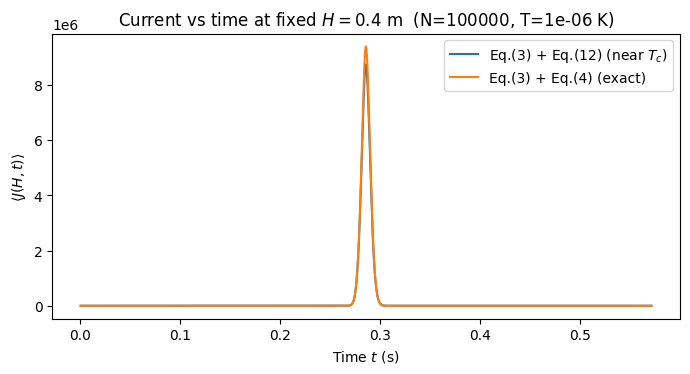

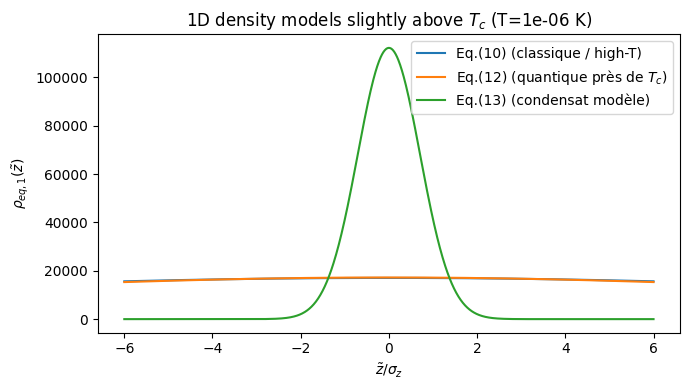

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp

# -----------------------------
# Physical constants (SI units)
# -----------------------------
hbar = const.hbar
kB   = const.Boltzmann
g    = const.g

# -----------------------------
# System parameters
# -----------------------------
m = 4 * 1.66053906660e-27    # He-4 mass [kg]

# Trap frequencies [rad/s]
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z =  100 * 2 * math.pi

w_perp = math.sqrt(w_x * w_y)
w_bar  = (w_x * w_y * w_z) ** (1.0/3.0)

# Oscillator lengths
sigma_x = math.sqrt(hbar / (m * w_x))
sigma_y = math.sqrt(hbar / (m * w_y))
sigma_z = math.sqrt(hbar / (m * w_z))

# -----------------------------
# Experiment knobs
# -----------------------------
N_target = 1e5
T        = 1e-6
beta     = 1.0 / (kB * T)
H        = 0.4

# time grid for the current
tc   = math.sqrt(2.0 * H / g)
tmin = max(1e-6, 1e-3 * tc)
tmax = 2.0 * tc
Nt   = 2000
t_grid = np.linspace(tmin, tmax, Nt)

# ---------------------------------------------------------
# Eq. (5): N(mu_tilde) for a trapped ideal Bose gas (exact)
# ---------------------------------------------------------
def N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z, tol=1e-12, j_max=200000):
    beta = 1.0/(kB*T)
    ax, ay, az = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        num   = mp.e**(j*beta*mu_tilde)
        denom = (1 - mp.e**(-j*ax))*(1 - mp.e**(-j*ay))*(1 - mp.e**(-j*az))
        term  = num/denom
        S += term
        if j > 10 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

def solve_mu_tilde(N_target, T, w_x, w_y, w_z, eps=1e-14, tol=1e-12, max_iter=200):
    beta = 1.0/(kB*T)
    N_th_max = N_of_mu_tilde(0.0, T, w_x, w_y, w_z)

    if N_target >= N_th_max:
        mu_tilde = 0.0
        N0 = N_target - N_th_max
        T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
        return mu_tilde, N0, N_th_max, T_c_est

    def f(mu): return N_of_mu_tilde(mu, T, w_x, w_y, w_z) - N_target

    mu_hi = -eps * kB*T
    mu_lo = -50.0 * kB*T

    flo = f(mu_lo)
    while flo >= 0:
        mu_lo *= 2.0
        flo = f(mu_lo)
        if mu_lo < -1e6*kB*T:
            raise RuntimeError("Failed to bracket μ̃ for number equation.")

    # Bisection
    for _ in range(max_iter):
        mu_mid = 0.5*(mu_lo + mu_hi)
        fmid = f(mu_mid)
        if abs(fmid) < max(1.0, N_target)*tol or abs(mu_hi - mu_lo) < abs(mu_hi)*1e-12:
            mu_tilde = mu_mid
            break
        if fmid > 0:
            mu_hi = mu_mid
        else:
            mu_lo = mu_mid
    else:
        raise RuntimeError("Bisection did not converge — increase max_iter or relax tol.")

    T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
    return float(mu_tilde), 0.0, N_target, T_c_est

mu_tilde, N0, N_th, T_c_est = solve_mu_tilde(N_target, T, w_x, w_y, w_z)

# Sanity check
N_check = N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z)
print(f"[Sanity check] Target N={N_target:.6g},  from Eq.(5) with mu_tilde -> N={N_check:.6g},  ΔN={N_check-N_target:.3g}")
print(f"mu_tilde / (kB T) = {mu_tilde/(kB*T):.6g}")
print(f"Estimated Tc (harmonic trap, Eq. (6)) = {T_c_est:.3e} K")
if N0>0:
    print(f"Condensate present: N0 = {N0:.3g} ({100*N0/N_target:.2f}% of atoms). Using mu_tilde=0.")

# ---------------------------------------------------------
# Eq. (12): 1D equilibrium density near Tc (polylog)
# ---------------------------------------------------------
pref12 = (1.0 / (beta*hbar*w_perp)**2) * (1.0 / math.sqrt(2.0*math.pi*(hbar**2)*beta/m))

def rho_eq1D_eq12(z_tilde, T, mu_tilde):
    beta = 1.0/(kB*T)
    A = 0.5 * m * beta * (w_z**2) * (z_tilde**2)
    q = mp.e**(beta*mu_tilde - A)
    return pref12 * float(mp.polylog(2.5, q))

# ---------------------------------------------------------
# Eq. (10): High-T / classical approximation (j=1 only)
#   rho ~ exp(beta mu_tilde) * pref12 * exp(-A)
# ---------------------------------------------------------
def rho_eq1D_eq10(z_tilde, T, mu_tilde):
    beta = 1.0/(kB*T)
    A = 0.5 * m * beta * (w_z**2) * (z_tilde**2)
    return pref12 * math.exp(beta*mu_tilde) * math.exp(-A)

# ---------------------------------------------------------
# Eq. (4): Exact 1D equilibrium density (sum over j)
#   rho_eq,1(ztil) = sum_j e^{jβμ̃} Π_{α=x,y} 1/(1-e^{-jβħωα})
#                   * 1/(σz sqrt(pi(1-e^{-2 jβħωz})))
#                   * exp(-tanh(jβħωz/2) * ztil^2/σz^2)
# ---------------------------------------------------------
def rho_eq1D_eq4_exact(z_tilde, T, mu_tilde, j_max=20000, tol=1e-12):
    beta = 1.0/(kB*T)
    bx, by, bz = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        ej = mp.e**(j*beta*mu_tilde)
        fx = 1.0 / (1.0 - mp.e**(-j*bx))
        fy = 1.0 / (1.0 - mp.e**(-j*by))

        denom_z = sigma_z * mp.sqrt(mp.pi * (1.0 - mp.e**(-2.0*j*bz)))
        expo = mp.e**(-mp.tanh(0.5*j*bz) * (z_tilde**2)/(sigma_z**2))

        term = ej * fx * fy * (1.0/denom_z) * expo
        S += term

        if j > 20 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

# ---------------------------------------------------------
# Eq. (13): "Condensate model" density (1D ground state Gaussian)
# Useful as a comparison curve. Here we scale it with N_target.
# ---------------------------------------------------------
def rho_eq1D_eq13(z_tilde, N=N_target):
    return (N/(math.sqrt(math.pi)*sigma_z)) * math.exp(-(z_tilde/sigma_z)**2)

# ---------------------------------------------------------
# Kinematics and current Eq. (3)
# ---------------------------------------------------------
def z_c(t): return H - 0.5 * g * t**2
def scale_t(t): return 1.0 / math.sqrt(1.0 + (w_z*t)**2)
def z_tilde_of_t(t): return z_c(t) * scale_t(t)

def v_z(t):
    return (1.0/t) * (H + 0.5*g*t**2 - (H - 0.5*g*t**2)/(1.0 + (w_z*t)**2))

# -----------------------------
# 1) CURRENT: "exact" curve
# -----------------------------
J_12 = np.zeros_like(t_grid, dtype=float)  # Eq.(3)+(12)
J_4  = np.zeros_like(t_grid, dtype=float)  # Eq.(3)+(4) exact

for i, tj in enumerate(t_grid):
    zt = z_tilde_of_t(tj)
    jac = scale_t(tj)
    J_12[i] = (v_z(tj) * jac) * rho_eq1D_eq12(zt, T, mu_tilde)
    J_4[i]  = (v_z(tj) * jac) * rho_eq1D_eq4_exact(zt, T, mu_tilde)

plt.figure(figsize=(7,4))
plt.plot(t_grid, J_12, label="Eq.(3) + Eq.(12) (near $T_c$)")
plt.plot(t_grid, J_4,  label="Eq.(3) + Eq.(4) (exact)")
plt.xlabel("Time $t$ (s)")
plt.ylabel(r"$\langle J(H,t)\rangle$")
plt.title(fr"Current vs time at fixed $H={H}$ m  (N={N_target:.0f}, T={T:g} K)")
plt.legend()
plt.tight_layout()
plt.show()

# -----------------------------
# 2) DENSITY comparison plot (slightly above Tc)
#    Compare rho_eq1(ztil) for Eq.(10), Eq.(12), Eq.(13)
# -----------------------------
zmax = 6.0 * sigma_z
z_grid = np.linspace(-zmax, zmax, 1200)

rho10 = np.array([rho_eq1D_eq10(z, T, mu_tilde) for z in z_grid])
rho12 = np.array([rho_eq1D_eq12(z, T, mu_tilde) for z in z_grid])
rho13 = np.array([rho_eq1D_eq13(z, N_target)    for z in z_grid])

# Optional: if you prefer comparing only SHAPES, uncomment normalization:
rho10 /= np.trapezoid(rho10, z_grid)
rho12 /= np.trapezoid(rho12, z_grid)
rho13 /= np.trapezoid(rho13, z_grid)


plt.figure(figsize=(7,4))
plt.plot(z_grid/sigma_z, rho10, label="Eq.(10) (classique / high-T)")
plt.plot(z_grid/sigma_z, rho12, label="Eq.(12) (quantique près de $T_c$)")
plt.plot(z_grid/sigma_z, rho13, label="Eq.(13) (condensat modèle)")
plt.xlabel(r"$\tilde{z}/\sigma_z$")
plt.ylabel(r"$\rho_{eq,1}(\tilde z)$")
plt.title(fr"1D density models slightly above $T_c$ (T={T:g} K)")
plt.legend()
plt.tight_layout()
plt.show()


##pre-Jan15

[Sanity check] Target N=100000,  from Eq.(5) with mu_tilde -> N=100000,  ΔN=-3.47e-08
mu_tilde / (kB T) = -0.11409
Estimated Tc (harmonic trap, Eq. (6)) = 9.724e-07 K


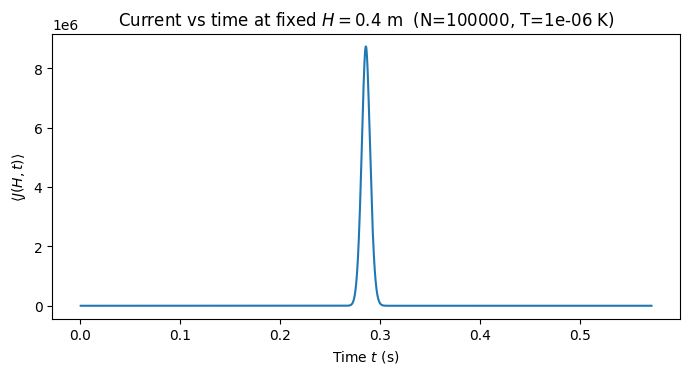

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp

# -----------------------------
# Physical constants (SI units)
# -----------------------------
hbar = const.hbar
kB   = const.Boltzmann
g    = const.g

# -----------------------------
# System parameters
# -----------------------------
m = 4 * 1.66053906660e-27    # He-4 mass [kg]

# Trap frequencies [rad/s]
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z =  100 * 2 * math.pi

w_perp = math.sqrt(w_x * w_y)
w_bar  = (w_x * w_y * w_z) ** (1.0/3.0)

# Oscillator lengths
sigma_x = math.sqrt(hbar / (m * w_x))
sigma_y = math.sqrt(hbar / (m * w_y))
sigma_z = math.sqrt(hbar / (m * w_z))

# -----------------------------
# Experiment knobs (base)
# -----------------------------
N_target = 1e5
H        = 0.4

# time grid for the current (depends only on H)
tc   = math.sqrt(2.0 * H / g)
tmin = max(1e-6, 1e-3 * tc)
tmax = 2.0 * tc
Nt   = 2000
t_grid = np.linspace(tmin, tmax, Nt)

# ---------------------------------------------------------
# Eq. (5): N(mu_tilde) for a trapped ideal Bose gas (exact)
# ---------------------------------------------------------
def N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z, tol=1e-12, j_max=200000):
    beta = 1.0/(kB*T)
    ax, ay, az = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        num   = mp.e**(j*beta*mu_tilde)
        denom = (1 - mp.e**(-j*ax))*(1 - mp.e**(-j*ay))*(1 - mp.e**(-j*az))
        term  = num/denom
        S += term
        if j > 10 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

def solve_mu_tilde(N_target, T, w_x, w_y, w_z, eps=1e-14, tol=1e-12, max_iter=200):
    beta = 1.0/(kB*T)
    N_th_max = N_of_mu_tilde(0.0, T, w_x, w_y, w_z)

    # Tc estimate (diagnostic)
    T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)

    # Below Tc: μ̃ = 0, condensate fraction present
    if N_target >= N_th_max:
        mu_tilde = 0.0
        N0 = N_target - N_th_max
        return mu_tilde, N0, N_th_max, T_c_est

    # Above Tc: solve μ̃ < 0
    def f(mu): return N_of_mu_tilde(mu, T, w_x, w_y, w_z) - N_target
    mu_hi = -eps * kB*T
    mu_lo = -50.0 * kB*T

    flo = f(mu_lo)
    while flo >= 0:
        mu_lo *= 2.0
        flo = f(mu_lo)
        if mu_lo < -1e6*kB*T:
            raise RuntimeError("Failed to bracket μ̃ for number equation.")

    for _ in range(max_iter):
        mu_mid = 0.5*(mu_lo + mu_hi)
        fmid = f(mu_mid)
        if abs(fmid) < max(1.0, N_target)*tol or abs(mu_hi - mu_lo) < abs(mu_hi)*1e-12:
            return float(mu_mid), 0.0, N_th_max, T_c_est
        if fmid > 0: mu_hi = mu_mid
        else:        mu_lo = mu_mid

    raise RuntimeError("Bisection did not converge.")

# ---------------------------------------------------------
# Kinematics and current Eq. (3)
# ---------------------------------------------------------
def z_c(t): return H - 0.5 * g * t**2
def scale_t(t): return 1.0 / math.sqrt(1.0 + (w_z*t)**2)
def z_tilde_of_t(t): return z_c(t) * scale_t(t)

def v_z(t):
    return (1.0/t) * (H + 0.5*g*t**2 - (H - 0.5*g*t**2)/(1.0 + (w_z*t)**2))

# ---------------------------------------------------------
# Density models: Eq.(10), Eq.(12), Eq.(4 exact), Eq.(13)
# NOTE: pref12 depends on beta, so we compute it inside helpers
# ---------------------------------------------------------
def pref12_of_T(T):
    beta = 1.0/(kB*T)
    return (1.0 / (beta*hbar*w_perp)**2) * (1.0 / math.sqrt(2.0*math.pi*(hbar**2)*beta/m))

def rho_eq1D_eq12(z_tilde, T, mu_tilde):
    beta = 1.0/(kB*T)
    pref12 = pref12_of_T(T)
    A = 0.5 * m * beta * (w_z**2) * (z_tilde**2)
    q = mp.e**(beta*mu_tilde - A)
    return pref12 * float(mp.polylog(2.5, q))

def rho_eq1D_eq10(z_tilde, T, mu_tilde):
    beta = 1.0/(kB*T)
    pref12 = pref12_of_T(T)
    A = 0.5 * m * beta * (w_z**2) * (z_tilde**2)
    return pref12 * math.exp(beta*mu_tilde) * math.exp(-A)

def rho_eq1D_eq4_exact(z_tilde, T, mu_tilde, j_max=20000, tol=1e-12):
    beta = 1.0/(kB*T)
    bx, by, bz = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        ej = mp.e**(j*beta*mu_tilde)
        fx = 1.0 / (1.0 - mp.e**(-j*bx))
        fy = 1.0 / (1.0 - mp.e**(-j*by))
        denom_z = sigma_z * mp.sqrt(mp.pi * (1.0 - mp.e**(-2.0*j*bz)))
        expo = mp.e**(-mp.tanh(0.5*j*bz) * (z_tilde**2)/(sigma_z**2))
        term = ej * fx * fy * (1.0/denom_z) * expo
        S += term
        if j > 20 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

def rho_eq1D_eq13(z_tilde, N0):
    # condensate term should use N0, not N_target
    if N0 <= 0:
        return 0.0
    return (N0/(math.sqrt(math.pi)*sigma_z)) * math.exp(-(z_tilde/sigma_z)**2)

# ---------------------------------------------------------
# Plot helper: currents for a given T (thermal/transient/BEC)
# ---------------------------------------------------------
def plot_currents_for_T(T, title_suffix=""):
    mu_tilde, N0, N_th_max, T_c_est = solve_mu_tilde(N_target, T, w_x, w_y, w_z)

    # sanity check (optional)
    N_check = N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z)
    print(f"\n=== T={T:.3e} K | Tc~{T_c_est:.3e} K | T/Tc={T/T_c_est:.3f} ===")
    print(f"mu_tilde/(kBT)={mu_tilde/(kB*T):.6g} | N0={N0:.3g} | N_check={N_check:.6g}")

    J10 = np.zeros_like(t_grid, dtype=float)
    J12 = np.zeros_like(t_grid, dtype=float)
    J4  = np.zeros_like(t_grid, dtype=float)
    J13 = np.zeros_like(t_grid, dtype=float)

    for i, tj in enumerate(t_grid):
        zt  = z_tilde_of_t(tj)
        jac = scale_t(tj)
        fac = v_z(tj) * jac

        J10[i] = fac * rho_eq1D_eq10(zt, T, mu_tilde)
        J12[i] = fac * rho_eq1D_eq12(zt, T, mu_tilde)
        J4[i]  = fac * rho_eq1D_eq4_exact(zt, T, mu_tilde)
        if N0 > 0:
            J13[i] = fac * rho_eq1D_eq13(zt, N0)

    plt.figure(figsize=(7,4))
    plt.plot(t_grid, J10, label="Eq.(3)+(10) classique")
    plt.plot(t_grid, J12, label="Eq.(3)+(12) near $T_c$")
    plt.plot(t_grid, J4,  label="Eq.(3)+(4) exact")
    if N0 > 0:
        plt.plot(t_grid, J13, label="Eq.(3)+(13) condensat (N0)")
    plt.xlabel("Time $t$ (s)")
    plt.ylabel(r"$\langle J(H,t)\rangle$")
    plt.title(f"Current vs time @ H={H} m | T={T:.2e} K {title_suffix}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# Plot helper: density comparison slightly above Tc
# x-axis scaled with thermal length lT (important!)
# ---------------------------------------------------------
def plot_densities_for_T(T, title_suffix=""):
    mu_tilde, N0, N_th_max, T_c_est = solve_mu_tilde(N_target, T, w_x, w_y, w_z)

    lT = math.sqrt(kB*T/(m*w_z**2))   # thermal length scale
    zmax = 4.0 * lT                    # wide enough for thermal profiles
    z_grid = np.linspace(-zmax, zmax, 1500)

    rho10 = np.array([rho_eq1D_eq10(z, T, mu_tilde) for z in z_grid])
    rho12 = np.array([rho_eq1D_eq12(z, T, mu_tilde) for z in z_grid])
    # Eq.(13) is included as "model comparison"; above Tc N0=0, so it will vanish.
    rho13 = np.array([rho_eq1D_eq13(z, N0) for z in z_grid])

    # normalize to unit area (shape comparison)
    rho10 /= np.trapezoid(rho10, z_grid)
    rho12 /= np.trapezoid(rho12, z_grid)
    if np.max(rho13) > 0:
        rho13 /= np.trapezoid(rho13, z_grid)

    plt.figure(figsize=(7,4))
    plt.plot(z_grid/lT, rho10, label="Eq.(10) classique / high-T (norm.)")
    plt.plot(z_grid/lT, rho12, label="Eq.(12) quantique près de $T_c$ (norm.)")
    if np.max(rho13) > 0:
        plt.plot(z_grid/lT, rho13, label="Eq.(13) condensat (norm., N0)")
    else:
        # still show shape of a pure condensate for comparison (optional)
        rho13toy = np.array([(1/(math.sqrt(math.pi)*sigma_z))*math.exp(-(z/sigma_z)**2) for z in z_grid])
        rho13toy /= np.trapezoid(rho13toy, z_grid)
        plt.plot(z_grid/lT, rho13toy, label="Eq.(13) toy condensat (norm., N=1)")

    plt.xlabel(r"$\tilde{z}/\ell_T$")
    plt.ylabel(r"$\rho_{eq,1}(\tilde z)$ (area=1)")
    plt.title(f"1D density models | T={T:.2e} K (Tc~{T_c_est:.2e} K) {title_suffix}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# -----------------------------
# Experiment knobs
# -----------------------------
N_target = 1e5             # set by experiment (advisor suggested 1e5)
T        = 1e-6            # Kelvin
beta     = 1.0 / (kB * T)
H = 0.4   # m

# time grid for the current
tc   = math.sqrt(2.0 * H / g)
tmin = max(1e-6, 1e-3 * tc)
tmax = 2.0 * tc
Nt   = 2000
t_grid = np.linspace(tmin, tmax, Nt)

# ---------------------------------------------------------
# Eq. (5): N(mu_tilde) for a trapped ideal Bose gas (exact)
# ---------------------------------------------------------
def N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z, tol=1e-12, j_max=200000):
    beta = 1.0/(kB*T)
    ax, ay, az = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        num   = mp.e**(j*beta*mu_tilde)
        denom = (1 - mp.e**(-j*ax))*(1 - mp.e**(-j*ay))*(1 - mp.e**(-j*az))
        term  = num/denom
        S += term
        # early stop once tail is tiny
        if j > 10 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

def solve_mu_tilde(N_target, T, w_x, w_y, w_z, eps=1e-14, tol=1e-12, max_iter=200):
    beta = 1.0/(kB*T)
    # Max thermal population at mu=0 (saturation)
    N_th_max = N_of_mu_tilde(0.0, T, w_x, w_y, w_z)

    # If target exceeds thermal capacity -> condensate, set mu=0 and return N0
    if N_target >= N_th_max:
        mu_tilde = 0.0
        N0 = N_target - N_th_max
        # optional: Tc estimate for info only
        w_bar = (w_x*w_y*w_z)**(1/3)
        T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
        return mu_tilde, N0, N_th_max, T_c_est

    # Otherwise, find unique mu < 0 with N(mu)=N_target via bisection in [mu_lo, mu_hi]
    def f(mu): return N_of_mu_tilde(mu, T, w_x, w_y, w_z) - N_target

    mu_hi = -eps * kB*T                 # just below 0, stay ≤0
    mu_lo = -50.0 * kB*T                # safely negative (makes N tiny)

    # Ensure the bracket has opposite signs: f(mu_lo) < 0 < f(mu_hi)
    flo = f(mu_lo)
    fhi = f(mu_hi)
    while flo >= 0:                     # expand until flo < 0
        mu_lo *= 2.0
        flo = f(mu_lo)
        if mu_lo < -1e6*kB*T:
            raise RuntimeError("Failed to bracket μ̃_tilde for number equation.")

    if fhi <= 0:
        # This can happen numerically if eps too big; nudge mu_hi closer to 0⁻
        mu_hi = -1e-16 * kB*T
        fhi = f(mu_hi)

    # Bisection
    for _ in range(max_iter):
        mu_mid = 0.5*(mu_lo + mu_hi)
        fmid = f(mu_mid)
        if abs(fmid) < max(1.0, N_target)*tol or abs(mu_hi - mu_lo) < abs(mu_hi)*1e-12:
            mu_tilde = mu_mid
            break
        if fmid > 0:      # root is to the left
            mu_hi, fhi = mu_mid, fmid
        else:             # root is to the right
            mu_lo, flo = mu_mid, fmid
    else:
        raise RuntimeError("Bisection did not converge — increase max_iter or relax tol.")

    w_bar = (w_x*w_y*w_z)**(1/3)
    T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
    return float(mu_tilde), 0.0, N_target, T_c_est


mu_tilde, N0, N_th, T_c_est = solve_mu_tilde(N_target, T, w_x, w_y, w_z)

# Sanity check
N_check = N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z)
print(f"[Sanity check] Target N={N_target:.6g},  from Eq.(5) with mu_tilde -> N={N_check:.6g},  ΔN={N_check-N_target:.3g}")
print(f"mu_tilde / (kB T) = {mu_tilde/(kB*T):.6g}")
print(f"Estimated Tc (harmonic trap, Eq. (6)) = {T_c_est:.3e} K")
if N0>0:
    print(f"Condensate present: N0 = {N0:.3g} ({100*N0/N_target:.2f}% of atoms). Using mu_tilde=0.")

# ---------------------------------------------------------
# One-dimensional equilibrium density (Eq. 12, near Tc)
# ---------------------------------------------------------
def rho_eq1D_near(z_tilde, T, mu_tilde):
    beta = 1.0/(kB*T)
    pref = (1.0 / (beta*hbar*w_perp)**2) * (1.0 / math.sqrt(2.0*math.pi*(hbar**2)*beta/m))
    A = 0.5 * m * beta * (w_z**2) * (z_tilde**2)
    q = mp.e**(beta*mu_tilde - A)
    return pref * float(mp.polylog(2.5, q))

# ---------------------------------------------------------
# Current vs time at fixed detector height z=H
# ---------------------------------------------------------
def z_c(t): return H - 0.5 * g * t**2
def scale_t(t): return 1.0 / math.sqrt(1.0 + (w_z*t)**2)
def z_tilde(t): return z_c(t) * scale_t(t)
def v_z(t):
    # eq. (2) velocity on z-axis
    return (1.0/t) * (H + 0.5*g*t**2 - (H - 0.5*g*t**2)/(1.0 + (w_z*t)**2))

J_t = np.zeros_like(t_grid, dtype=float)
for i, tj in enumerate(t_grid):
    zt = z_tilde(tj)
    rho_th  = rho_eq1D_near(zt, T, mu_tilde)
    J_t[i]  = (v_z(tj) * scale_t(tj)) * (rho_th)    # Eq. (3)

plt.figure(figsize=(7,4))
plt.plot(t_grid, J_t)
plt.xlabel("Time $t$ (s)")
plt.ylabel(r"$\langle J(H,t)\rangle$")
plt.title(fr"Current vs time at fixed $H={H}$ m  (N={N_target:.0f}, T={T:g} K)")
plt.tight_layout()
plt.show()

## New Asymptotes

=== Parameters ===
H = 0.500 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 319.275 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== One-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+03 s/K
d(ΔT)/dT | Tc+ = 6.904859e+03 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 9.212374e+01 s/K
d(<T>)/dT | Tc+ = 9.207960e+01 s/K
slope ratio (<T>) = 1.000479



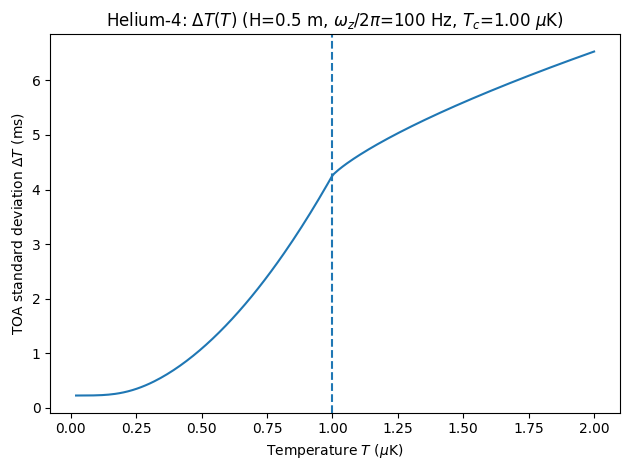

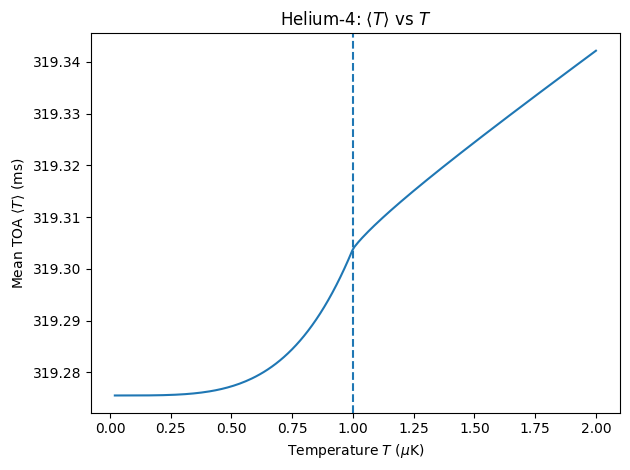

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical, whole-gas model)

Generates:
  1) ΔT(T) (TOA standard deviation) vs T
  2) <T>(T) (mean TOA) vs T
and prints one-sided slope ratios at Tc.

Model:
- Below Tc: condensate–thermal mixture with wT=(T/Tc)^3, w0=1-wT
  σV0^2 = ħ ωz / (2 m)
  σVT^2 = (kB T / m) R1,  R1 = ζ(7/2)/ζ(5/2)
  ΔT = (1/g) sqrt( (1-wT)σV0^2 + wT σVT^2 )
  <T> = tc + [ (1-wT)σV0^2 + wT σVT^2 ] / (2 g sqrt(2 g H))

- Above Tc (ideal trapped gas): solve fugacity z(T) from Li_3(z)=ζ(3)(Tc/T)^3
  R(T)=Li_{7/2}(z)/Li_{5/2}(z)
  ΔT = (1/g) sqrt( (kB T/m) R(T) )
  <T> = tc + (kB T/m) R(T) / (2 g sqrt(2 g H))

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u              # Helium-4 mass (kg)
H = 0.50                   # drop height (m)
omega_z = 2 * math.pi * 100.0   # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Condensate vertical velocity variance (noninteracting HO ground state)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3 = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Convenience constant D1=(kB/m)R1 used below Tc
D1 = (kB / m) * R1

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly in numerics
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_of_T(T: float) -> float:
    """R(T) = Li_{7/2}(z(T)) / Li_{5/2}(z(T))"""
    if T <= Tc:
        return R1
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Main observables
# ----------------------------
def DeltaT(T: float) -> float:
    """TOA standard deviation ΔT(T) in seconds"""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_of_T(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT(T: float) -> float:
    """Mean TOA <T>(T) in seconds"""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_of_T(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Numerical derivatives near Tc (one-sided)
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    # Choose a tiny offset around Tc for numerical stability
    eps = 1e-6
    h = 1e-9  # Kelvin step for derivative
    dDT_minus = deriv_central(DeltaT, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    # Slopes at Tc
    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== One-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)
    DTs = np.array([DeltaT(float(T)) for T in Ts])
    means = np.array([meanT(float(T)) for T in Ts])

    # Plot ΔT(T)
    plt.figure()
    plt.plot(Ts * 1e6, DTs * 1e3)
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(rf"Helium-4: $\Delta T(T)$ (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)")
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(Ts * 1e6, means * 1e3)
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

=== Parameters ===
H = 0.500 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 319.275 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839913955
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Universal kink-ratio theory check ===
(Tc R'(Tc+))/R1  (universal) = 1.659067941
A/(D1 Tc) (finite-size parameter) = 2.856985e-03
R_infty = 4/(1+(Tc R')/R1) = 1.504286498
R_fs    = (4-3A/(D1Tc))/(1+(Tc R')/R1) = 1.501063205

=== One-sided slopes at Tc (numerical finite difference) ===
d(ΔT)/dT | Tc- = 6.908191e+03 s/K
d(ΔT)/dT | Tc+ = 6.904859e+03 s/K
slope ratio (ΔT) = 1.000482520
compare: ratio(ΔT) vs R_fs  ->  diff = -5.006e-01

d(<T>)/dT | Tc- = 9.212374e+01 s/K
d(<T>)/dT | Tc+ = 9.207960e+01 s/K
slope ratio (<T>) = 1.000479312
compare: ratio(<T>) vs R_fs -> diff = -5.006e-01



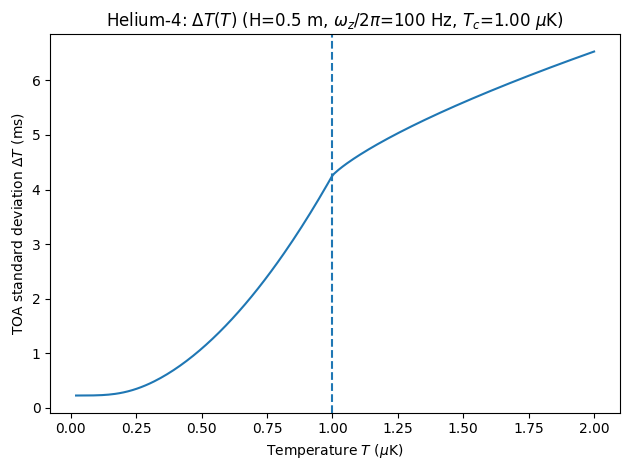

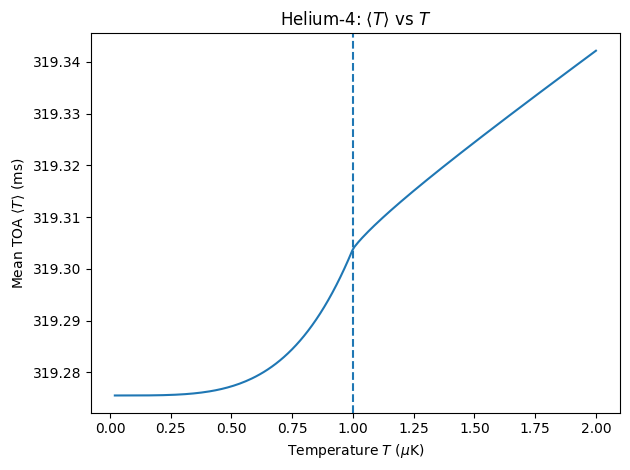

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical, whole-gas model)

Generates:
  1) ΔT(T) (TOA standard deviation) vs T
  2) <T>(T) (mean TOA) vs T
and prints one-sided slope ratios at Tc.

ADDED:
  - Universal thermodynamic-limit slope ratio R_infty (zeta/polylog-only)
  - Finite-size corrected slope-ratio estimate using A/(D1 Tc)
  - Side-by-side comparison with numerical finite-difference ratio

Model:
- Below Tc: condensate–thermal mixture with wT=(T/Tc)^3, w0=1-wT
  σV0^2 = ħ ωz / (2 m)
  σVT^2 = (kB T / m) R1,  R1 = ζ(7/2)/ζ(5/2)
  ΔT = (1/g) sqrt( (1-wT)σV0^2 + wT σVT^2 )
  <T> = tc + [ (1-wT)σV0^2 + wT σVT^2 ] / (2 g sqrt(2 g H))

- Above Tc (ideal trapped gas): solve fugacity z(T) from Li_3(z)=ζ(3)(Tc/T)^3
  R(T)=Li_{7/2}(z)/Li_{5/2}(z)
  ΔT = (1/g) sqrt( (kB T/m) R(T) )
  <T> = tc + (kB T/m) R(T) / (2 g sqrt(2 g H))

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u              # Helium-4 mass (kg)
H = 0.50                   # drop height (m)
omega_z = 2 * math.pi * 100.0   # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Condensate vertical velocity variance (noninteracting HO ground state)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta2  = float(mp.zeta(2))
zeta3  = float(mp.zeta(3))
zeta32 = float(mp.zeta(mp.mpf("1.5")))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))

R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Convenience constant D1=(kB/m)R1 used below Tc
D1 = (kB / m) * R1

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly in numerics
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_of_T(T: float) -> float:
    """R(T) = Li_{7/2}(z(T)) / Li_{5/2}(z(T))"""
    if T <= Tc:
        return R1
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Main observables
# ----------------------------
def DeltaT(T: float) -> float:
    """TOA standard deviation ΔT(T) in seconds"""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_of_T(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT(T: float) -> float:
    """Mean TOA <T>(T) in seconds"""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_of_T(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Numerical derivatives near Tc (one-sided)
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    # Choose a tiny offset around Tc for numerical stability
    eps = 1e-6
    h = 1e-9  # Kelvin step for derivative
    dDT_minus = deriv_central(DeltaT, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Universal / estimate of the kink ratio at Tc
# ----------------------------
def TcRprime_over_R1_universal() -> float:
    """
    Universal constant:
      (Tc R'(Tc+))/R1
    with fixed-N in harmonic trap:
      Li_3(z)=zeta(3)(Tc/T)^3
      R(z)=Li_{7/2}(z)/Li_{5/2}(z)
    """
    # dR/dz at z=1:
    dRdz_at_1 = 1.0 - (zeta72 * zeta32) / (zeta52 * zeta52)
    # dz/dT at Tc+:
    dzdT_at_Tc = -(3.0 * zeta3 / zeta2) * (1.0 / Tc)
    # Tc R'(Tc+) = Tc * dR/dz * dz/dT
    TcRprime = Tc * dRdz_at_1 * dzdT_at_Tc
    return TcRprime / R1

def slope_ratio_estimates():
    """
    Returns:
      R_infty    : thermodynamic-limit slope ratio
      R_fs       : finite-size corrected estimate including A/(D1 Tc)
      A_over_D1Tc: small finite-size parameter
    """
    x = TcRprime_over_R1_universal()  # (Tc R')/R1
    R_infty = 4.0 / (1.0 + x)

    A_over_D1Tc = sigmaV0_sq / (D1 * Tc)  # = A/(D1 Tc)
    R_fs = (4.0 - 3.0 * A_over_D1Tc) / (1.0 + x)
    return R_infty, R_fs, A_over_D1Tc, x

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.9f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    # Universal / estimate checks
    R_infty, R_fs, A_over_D1Tc, x = slope_ratio_estimates()
    print("=== Universal kink-ratio theory check ===")
    print(f"(Tc R'(Tc+))/R1  (universal) = {x:.9f}")
    print(f"A/(D1 Tc) (finite-size parameter) = {A_over_D1Tc:.6e}")
    print(f"R_infty = 4/(1+(Tc R')/R1) = {R_infty:.9f}")
    print(f"R_fs    = (4-3A/(D1Tc))/(1+(Tc R')/R1) = {R_fs:.9f}")
    print()

    # Slopes at Tc (numerical)
    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    ratio_DT = dDTm / dDTp
    ratio_m  = dmm / dmp

    print("=== One-sided slopes at Tc (numerical finite difference) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {ratio_DT:.9f}")
    print(f"compare: ratio(ΔT) vs R_fs  ->  diff = {ratio_DT - R_fs:+.3e}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {ratio_m:.9f}")
    print(f"compare: ratio(<T>) vs R_fs -> diff = {ratio_m - R_fs:+.3e}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)
    DTs = np.array([DeltaT(float(T)) for T in Ts])
    means = np.array([meanT(float(T)) for T in Ts])

    # Plot ΔT(T)
    plt.figure()
    plt.plot(Ts * 1e6, DTs * 1e3)
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$ (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(Ts * 1e6, means * 1e3)
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

=== Parameters ===
H = 0.500 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 319.275 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Whole Bose gas: one-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+03 s/K
d(ΔT)/dT | Tc+ = 6.904859e+03 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 9.212374e+01 s/K
d(<T>)/dT | Tc+ = 9.207960e+01 s/K
slope ratio (<T>) = 1.000479



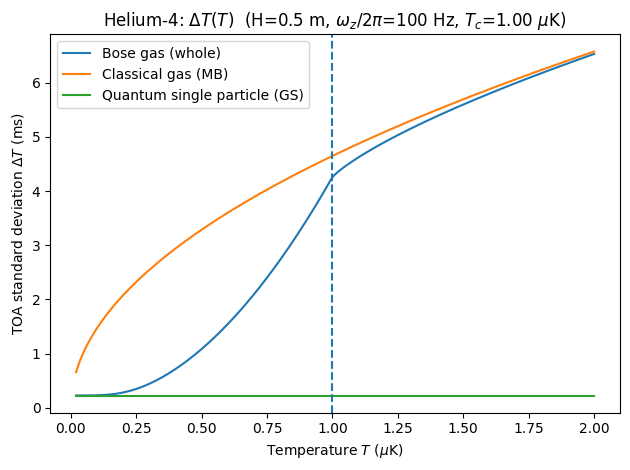

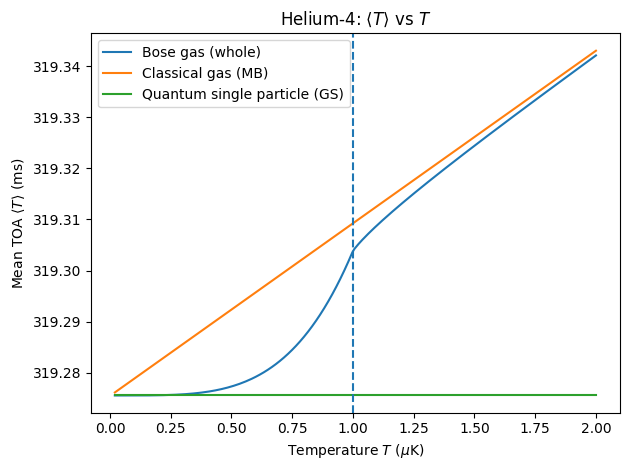

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical)

Adds, on the SAME graphs:
  - Whole Bose gas (below Tc mixture + above Tc ideal Bose with fugacity)
  - Classical gas (Maxwell–Boltzmann): R(T)=1 for all T
  - Quantum single particle (HO ground state, T-independent σV0)

Generates:
  1) ΔT(T) vs T
  2) <T>(T) vs T
and prints one-sided slope ratios at Tc (for the whole Bose gas curves).

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u                  # Helium-4 mass (kg)
H = 0.50                       # drop height (m)
omega_z = 2 * math.pi * 100.0  # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                    # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Quantum single-particle / condensate (noninteracting HO ground state):
# σV0^2 = ħ ωz /(2m)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3  = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped Bose gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_bose_above(T: float) -> float:
    """Bose factor above Tc: R(T)=Li_{7/2}(z(T))/Li_{5/2}(z(T))."""
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Whole Bose gas (your model)
# ----------------------------
def DeltaT_bose(T: float) -> float:
    """Whole Bose gas ΔT(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_bose_above(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT_bose(T: float) -> float:
    """Whole Bose gas <T>(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_bose_above(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Classical gas (Maxwell–Boltzmann, no Bose cycles)
# Same semiclassical mapping but with R(T)=1 for all T.
# ----------------------------
def DeltaT_classical(T: float) -> float:
    """Classical gas ΔT(T) [s]."""
    return (1.0 / g) * math.sqrt((kB * T / m) * 1.0)

def meanT_classical(T: float) -> float:
    """Classical gas <T>(T) [s]."""
    return tc + pref_mean * ((kB * T / m) * 1.0)

# ----------------------------
# Quantum single particle (HO ground state, T-independent)
# This corresponds to σV=σV0 (constant), hence constant ΔT and constant mean shift.
# ----------------------------
def DeltaT_single_particle(_: float) -> float:
    """Quantum single particle ΔT [s], independent of T in this model."""
    return (1.0 / g) * math.sqrt(sigmaV0_sq)

def meanT_single_particle(_: float) -> float:
    """Quantum single particle <T> [s], independent of T in this model."""
    return tc + pref_mean * sigmaV0_sq

# ----------------------------
# Numerical derivatives near Tc (one-sided) for whole Bose gas
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    eps = 1e-6
    h = 1e-9  # K
    dDT_minus = deriv_central(DeltaT_bose, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT_bose, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT_bose,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT_bose,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== Whole Bose gas: one-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)

    DT_bose = np.array([DeltaT_bose(float(T)) for T in Ts])
    DT_cl   = np.array([DeltaT_classical(float(T)) for T in Ts])
    DT_q1   = np.array([DeltaT_single_particle(float(T)) for T in Ts])

    m_bose  = np.array([meanT_bose(float(T)) for T in Ts])
    m_cl    = np.array([meanT_classical(float(T)) for T in Ts])
    m_q1    = np.array([meanT_single_particle(float(T)) for T in Ts])

    # Units for plotting
    T_microK = Ts * 1e6
    DT_bose_ms = DT_bose * 1e3
    DT_cl_ms   = DT_cl * 1e3
    DT_q1_ms   = DT_q1 * 1e3

    m_bose_ms = m_bose * 1e3
    m_cl_ms   = m_cl * 1e3
    m_q1_ms   = m_q1 * 1e3

    # Plot ΔT(T)
    plt.figure()
    plt.plot(T_microK, DT_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, DT_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, DT_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$  (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.legend()
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(T_microK, m_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, m_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, m_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.legend()
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

New trial with different parameters: low H

=== Parameters ===
H = 0.050 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 100.964 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Whole Bose gas: one-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+03 s/K
d(ΔT)/dT | Tc+ = 6.904859e+03 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 2.913208e+02 s/K
d(<T>)/dT | Tc+ = 2.911813e+02 s/K
slope ratio (<T>) = 1.000479



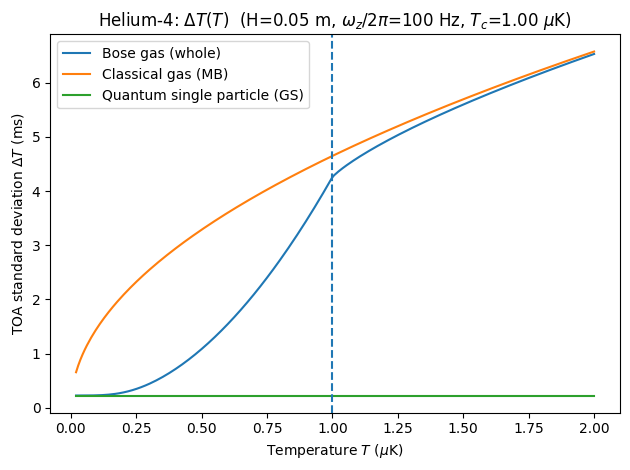

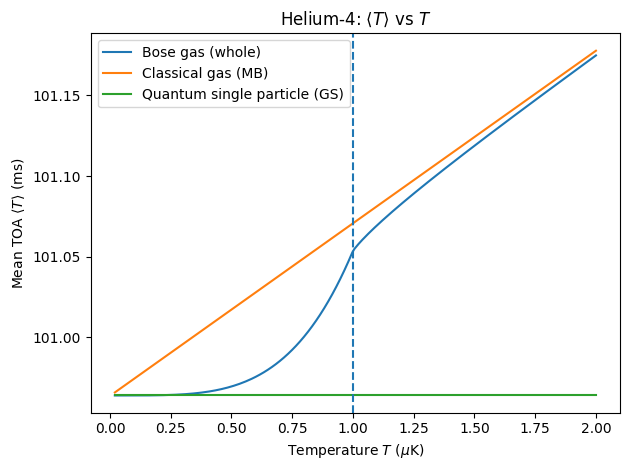

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical)

Adds, on the SAME graphs:
  - Whole Bose gas (below Tc mixture + above Tc ideal Bose with fugacity)
  - Classical gas (Maxwell–Boltzmann): R(T)=1 for all T
  - Quantum single particle (HO ground state, T-independent σV0)

Generates:
  1) ΔT(T) vs T
  2) <T>(T) vs T
and prints one-sided slope ratios at Tc (for the whole Bose gas curves).

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u                  # Helium-4 mass (kg)
H = 0.05                       # drop height (m)
omega_z = 2 * math.pi * 100.0  # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                    # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Quantum single-particle / condensate (noninteracting HO ground state):
# σV0^2 = ħ ωz /(2m)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3  = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped Bose gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_bose_above(T: float) -> float:
    """Bose factor above Tc: R(T)=Li_{7/2}(z(T))/Li_{5/2}(z(T))."""
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Whole Bose gas (your model)
# ----------------------------
def DeltaT_bose(T: float) -> float:
    """Whole Bose gas ΔT(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_bose_above(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT_bose(T: float) -> float:
    """Whole Bose gas <T>(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_bose_above(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Classical gas (Maxwell–Boltzmann, no Bose cycles)
# Same semiclassical mapping but with R(T)=1 for all T.
# ----------------------------
def DeltaT_classical(T: float) -> float:
    """Classical gas ΔT(T) [s]."""
    return (1.0 / g) * math.sqrt((kB * T / m) * 1.0)

def meanT_classical(T: float) -> float:
    """Classical gas <T>(T) [s]."""
    return tc + pref_mean * ((kB * T / m) * 1.0)

# ----------------------------
# Quantum single particle (HO ground state, T-independent)
# This corresponds to σV=σV0 (constant), hence constant ΔT and constant mean shift.
# ----------------------------
def DeltaT_single_particle(_: float) -> float:
    """Quantum single particle ΔT [s], independent of T in this model."""
    return (1.0 / g) * math.sqrt(sigmaV0_sq)

def meanT_single_particle(_: float) -> float:
    """Quantum single particle <T> [s], independent of T in this model."""
    return tc + pref_mean * sigmaV0_sq

# ----------------------------
# Numerical derivatives near Tc (one-sided) for whole Bose gas
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    eps = 1e-6
    h = 1e-9  # K
    dDT_minus = deriv_central(DeltaT_bose, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT_bose, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT_bose,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT_bose,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== Whole Bose gas: one-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)

    DT_bose = np.array([DeltaT_bose(float(T)) for T in Ts])
    DT_cl   = np.array([DeltaT_classical(float(T)) for T in Ts])
    DT_q1   = np.array([DeltaT_single_particle(float(T)) for T in Ts])

    m_bose  = np.array([meanT_bose(float(T)) for T in Ts])
    m_cl    = np.array([meanT_classical(float(T)) for T in Ts])
    m_q1    = np.array([meanT_single_particle(float(T)) for T in Ts])

    # Units for plotting
    T_microK = Ts * 1e6
    DT_bose_ms = DT_bose * 1e3
    DT_cl_ms   = DT_cl * 1e3
    DT_q1_ms   = DT_q1 * 1e3

    m_bose_ms = m_bose * 1e3
    m_cl_ms   = m_cl * 1e3
    m_q1_ms   = m_q1 * 1e3

    # Plot ΔT(T)
    plt.figure()
    plt.plot(T_microK, DT_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, DT_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, DT_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$  (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.legend()
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(T_microK, m_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, m_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, m_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.legend()
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

## Near field

=== Parameters ===
H = 0.010 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 45.152 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Whole Bose gas: one-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+03 s/K
d(ΔT)/dT | Tc+ = 6.904859e+03 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 6.514132e+02 s/K
d(<T>)/dT | Tc+ = 6.511011e+02 s/K
slope ratio (<T>) = 1.000479



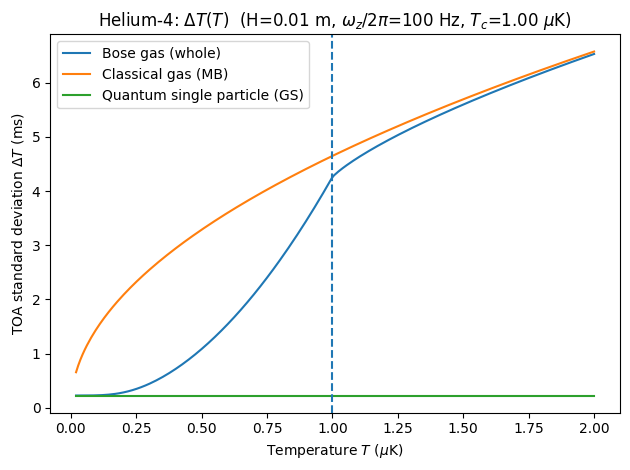

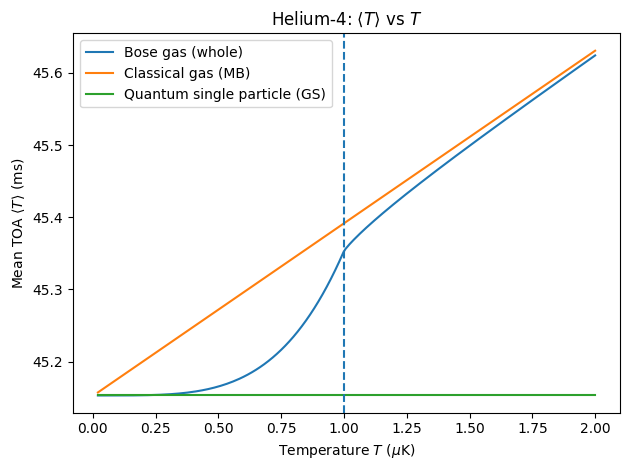

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical)

Adds, on the SAME graphs:
  - Whole Bose gas (below Tc mixture + above Tc ideal Bose with fugacity)
  - Classical gas (Maxwell–Boltzmann): R(T)=1 for all T
  - Quantum single particle (HO ground state, T-independent σV0)

Generates:
  1) ΔT(T) vs T
  2) <T>(T) vs T
and prints one-sided slope ratios at Tc (for the whole Bose gas curves).

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u                  # Helium-4 mass (kg)
H = 0.01                       # drop height (m)
omega_z = 2 * math.pi * 100.0  # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                    # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Quantum single-particle / condensate (noninteracting HO ground state):
# σV0^2 = ħ ωz /(2m)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3  = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped Bose gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_bose_above(T: float) -> float:
    """Bose factor above Tc: R(T)=Li_{7/2}(z(T))/Li_{5/2}(z(T))."""
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Whole Bose gas (your model)
# ----------------------------
def DeltaT_bose(T: float) -> float:
    """Whole Bose gas ΔT(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_bose_above(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT_bose(T: float) -> float:
    """Whole Bose gas <T>(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_bose_above(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Classical gas (Maxwell–Boltzmann, no Bose cycles)
# Same semiclassical mapping but with R(T)=1 for all T.
# ----------------------------
def DeltaT_classical(T: float) -> float:
    """Classical gas ΔT(T) [s]."""
    return (1.0 / g) * math.sqrt((kB * T / m) * 1.0)

def meanT_classical(T: float) -> float:
    """Classical gas <T>(T) [s]."""
    return tc + pref_mean * ((kB * T / m) * 1.0)

# ----------------------------
# Quantum single particle (HO ground state, T-independent)
# This corresponds to σV=σV0 (constant), hence constant ΔT and constant mean shift.
# ----------------------------
def DeltaT_single_particle(_: float) -> float:
    """Quantum single particle ΔT [s], independent of T in this model."""
    return (1.0 / g) * math.sqrt(sigmaV0_sq)

def meanT_single_particle(_: float) -> float:
    """Quantum single particle <T> [s], independent of T in this model."""
    return tc + pref_mean * sigmaV0_sq

# ----------------------------
# Numerical derivatives near Tc (one-sided) for whole Bose gas
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    eps = 1e-6
    h = 1e-9  # K
    dDT_minus = deriv_central(DeltaT_bose, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT_bose, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT_bose,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT_bose,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== Whole Bose gas: one-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)

    DT_bose = np.array([DeltaT_bose(float(T)) for T in Ts])
    DT_cl   = np.array([DeltaT_classical(float(T)) for T in Ts])
    DT_q1   = np.array([DeltaT_single_particle(float(T)) for T in Ts])

    m_bose  = np.array([meanT_bose(float(T)) for T in Ts])
    m_cl    = np.array([meanT_classical(float(T)) for T in Ts])
    m_q1    = np.array([meanT_single_particle(float(T)) for T in Ts])

    # Units for plotting
    T_microK = Ts * 1e6
    DT_bose_ms = DT_bose * 1e3
    DT_cl_ms   = DT_cl * 1e3
    DT_q1_ms   = DT_q1 * 1e3

    m_bose_ms = m_bose * 1e3
    m_cl_ms   = m_cl * 1e3
    m_q1_ms   = m_q1 * 1e3

    # Plot ΔT(T)
    plt.figure()
    plt.plot(T_microK, DT_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, DT_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, DT_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$  (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.legend()
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(T_microK, m_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, m_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, m_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.legend()
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

New trial with different parameters: low g

=== Parameters ===
H = 0.500 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 100963.755 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Whole Bose gas: one-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+08 s/K
d(ΔT)/dT | Tc+ = 6.904859e+08 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 2.913208e+09 s/K
d(<T>)/dT | Tc+ = 2.911813e+09 s/K
slope ratio (<T>) = 1.000479



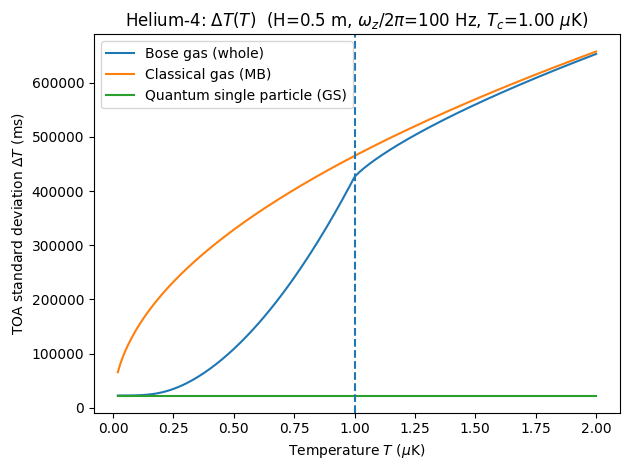

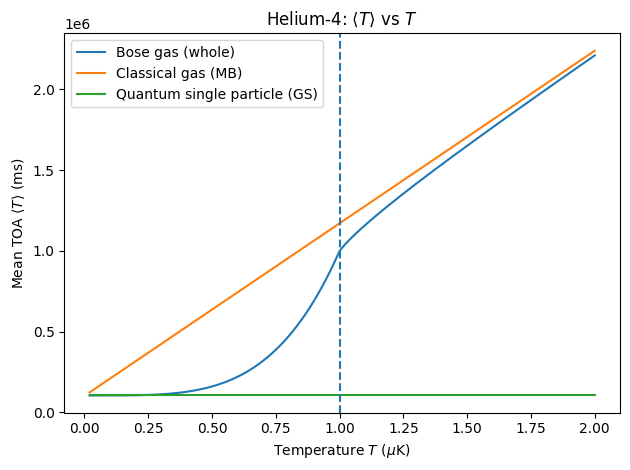

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical)

Adds, on the SAME graphs:
  - Whole Bose gas (below Tc mixture + above Tc ideal Bose with fugacity)
  - Classical gas (Maxwell–Boltzmann): R(T)=1 for all T
  - Quantum single particle (HO ground state, T-independent σV0)

Generates:
  1) ΔT(T) vs T
  2) <T>(T) vs T
and prints one-sided slope ratios at Tc (for the whole Bose gas curves).

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81e-5                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u                  # Helium-4 mass (kg)
H = 0.50                       # drop height (m)
omega_z = 2 * math.pi * 100.0  # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                    # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Quantum single-particle / condensate (noninteracting HO ground state):
# σV0^2 = ħ ωz /(2m)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3  = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped Bose gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_bose_above(T: float) -> float:
    """Bose factor above Tc: R(T)=Li_{7/2}(z(T))/Li_{5/2}(z(T))."""
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Whole Bose gas (your model)
# ----------------------------
def DeltaT_bose(T: float) -> float:
    """Whole Bose gas ΔT(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_bose_above(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT_bose(T: float) -> float:
    """Whole Bose gas <T>(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_bose_above(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Classical gas (Maxwell–Boltzmann, no Bose cycles)
# Same semiclassical mapping but with R(T)=1 for all T.
# ----------------------------
def DeltaT_classical(T: float) -> float:
    """Classical gas ΔT(T) [s]."""
    return (1.0 / g) * math.sqrt((kB * T / m) * 1.0)

def meanT_classical(T: float) -> float:
    """Classical gas <T>(T) [s]."""
    return tc + pref_mean * ((kB * T / m) * 1.0)

# ----------------------------
# Quantum single particle (HO ground state, T-independent)
# This corresponds to σV=σV0 (constant), hence constant ΔT and constant mean shift.
# ----------------------------
def DeltaT_single_particle(_: float) -> float:
    """Quantum single particle ΔT [s], independent of T in this model."""
    return (1.0 / g) * math.sqrt(sigmaV0_sq)

def meanT_single_particle(_: float) -> float:
    """Quantum single particle <T> [s], independent of T in this model."""
    return tc + pref_mean * sigmaV0_sq

# ----------------------------
# Numerical derivatives near Tc (one-sided) for whole Bose gas
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    eps = 1e-6
    h = 1e-9  # K
    dDT_minus = deriv_central(DeltaT_bose, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT_bose, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT_bose,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT_bose,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== Whole Bose gas: one-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)

    DT_bose = np.array([DeltaT_bose(float(T)) for T in Ts])
    DT_cl   = np.array([DeltaT_classical(float(T)) for T in Ts])
    DT_q1   = np.array([DeltaT_single_particle(float(T)) for T in Ts])

    m_bose  = np.array([meanT_bose(float(T)) for T in Ts])
    m_cl    = np.array([meanT_classical(float(T)) for T in Ts])
    m_q1    = np.array([meanT_single_particle(float(T)) for T in Ts])

    # Units for plotting
    T_microK = Ts * 1e6
    DT_bose_ms = DT_bose * 1e3
    DT_cl_ms   = DT_cl * 1e3
    DT_q1_ms   = DT_q1 * 1e3

    m_bose_ms = m_bose * 1e3
    m_cl_ms   = m_cl * 1e3
    m_q1_ms   = m_q1 * 1e3

    # Plot ΔT(T)
    plt.figure()
    plt.plot(T_microK, DT_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, DT_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, DT_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$  (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.legend()
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(T_microK, m_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, m_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, m_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.legend()
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

=== Parameters ===
H = 0.010 m
omega_z/2π = 100.0 Hz
Tc = 1.000 µK
tc = sqrt(2H/g) = 14278.431 ms
R1 = ζ(7/2)/ζ(5/2) = 0.839914
sigmaV0^2 = ħωz/(2m) = 4.987891e-06 (m^2/s^2)

=== Whole Bose gas: one-sided slopes at Tc (numerical) ===
d(ΔT)/dT | Tc- = 6.908191e+08 s/K
d(ΔT)/dT | Tc+ = 6.904859e+08 s/K
slope ratio (ΔT) = 1.000483

d(<T>)/dT | Tc- = 2.059949e+10 s/K
d(<T>)/dT | Tc+ = 2.058962e+10 s/K
slope ratio (<T>) = 1.000479



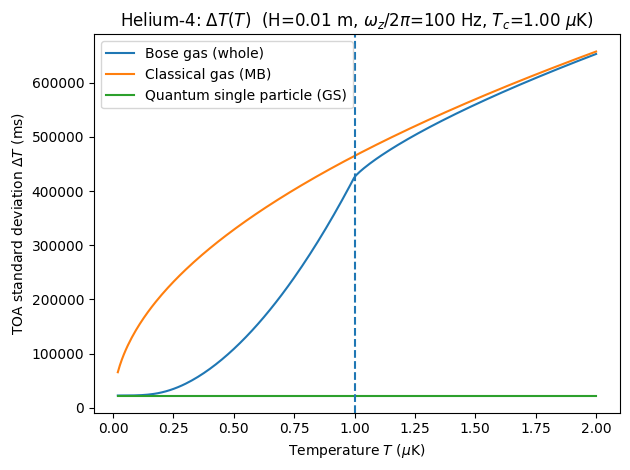

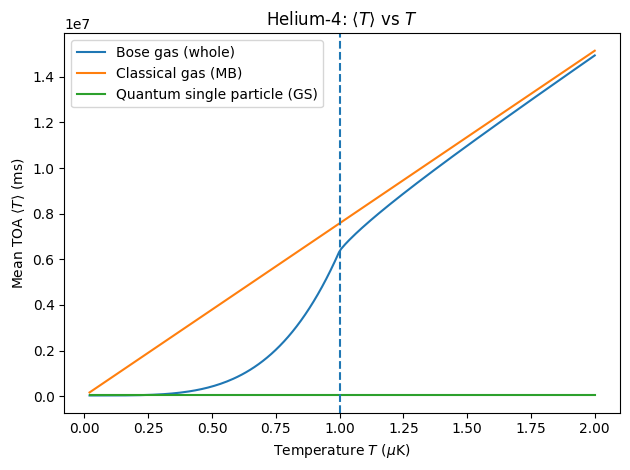

In [ ]:
#!/usr/bin/env python3
"""
Helium-4 TOA vs Temperature (semiclassical)

Adds, on the SAME graphs:
  - Whole Bose gas (below Tc mixture + above Tc ideal Bose with fugacity)
  - Classical gas (Maxwell–Boltzmann): R(T)=1 for all T
  - Quantum single particle (HO ground state, T-independent σV0)

Generates:
  1) ΔT(T) vs T
  2) <T>(T) vs T
and prints one-sided slope ratios at Tc (for the whole Bose gas curves).

Requires: numpy, mpmath, matplotlib
"""

import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt

# ----------------------------
# Physical constants
# ----------------------------
kB = 1.380649e-23          # J/K
hbar = 1.054571817e-34     # J*s
g = 9.81e-5                   # m/s^2
m_u = 1.66053906660e-27    # kg

# ----------------------------
# System parameters (EDIT ME)
# ----------------------------
m = 4.0 * m_u                  # Helium-4 mass (kg)
H = 0.01                       # drop height (m)
omega_z = 2 * math.pi * 100.0  # rad/s  (e.g., 100 Hz)
Tc = 1.0e-6                    # critical temperature (K)

# Temperature range
Tmin = 0.02 * Tc
Tmax = 2.0 * Tc
npts = 240

# ----------------------------
# Derived constants
# ----------------------------
tc = math.sqrt(2.0 * H / g)

# Quantum single-particle / condensate (noninteracting HO ground state):
# σV0^2 = ħ ωz /(2m)
sigmaV0_sq = hbar * omega_z / (2.0 * m)

# Zeta/polylog constants
zeta3  = float(mp.zeta(3))
zeta52 = float(mp.zeta(mp.mpf("2.5")))
zeta72 = float(mp.zeta(mp.mpf("3.5")))
R1 = zeta72 / zeta52  # ζ(7/2)/ζ(5/2)

# Prefactor for mean shift
pref_mean = 1.0 / (2.0 * g * math.sqrt(2.0 * g * H))

# ----------------------------
# Helper: fugacity z(T) for T>=Tc (ideal trapped Bose gas)
# Solve Li_3(z) = ζ(3) (Tc/T)^3 for z in (0,1).
# ----------------------------
def fugacity_z(T: float) -> float:
    if T <= Tc:
        return 1.0
    target = zeta3 * (Tc / T) ** 3
    lo, hi = 0.0, 1.0 - 1e-14  # avoid z=1 exactly
    for _ in range(140):
        mid = 0.5 * (lo + hi)
        val = float(mp.polylog(3, mid))
        if val < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def R_bose_above(T: float) -> float:
    """Bose factor above Tc: R(T)=Li_{7/2}(z(T))/Li_{5/2}(z(T))."""
    z = fugacity_z(T)
    return float(mp.polylog(mp.mpf("3.5"), z) / mp.polylog(mp.mpf("2.5"), z))

# ----------------------------
# Whole Bose gas (your model)
# ----------------------------
def DeltaT_bose(T: float) -> float:
    """Whole Bose gas ΔT(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return (1.0 / g) * math.sqrt(S)
    else:
        R = R_bose_above(T)
        return (1.0 / g) * math.sqrt((kB * T / m) * R)

def meanT_bose(T: float) -> float:
    """Whole Bose gas <T>(T) [s]."""
    if T <= Tc:
        wT = (T / Tc) ** 3
        S = (1.0 - wT) * sigmaV0_sq + wT * (kB * T / m) * R1
        return tc + pref_mean * S
    else:
        R = R_bose_above(T)
        return tc + pref_mean * ((kB * T / m) * R)

# ----------------------------
# Classical gas (Maxwell–Boltzmann, no Bose cycles)
# Same semiclassical mapping but with R(T)=1 for all T.
# ----------------------------
def DeltaT_classical(T: float) -> float:
    """Classical gas ΔT(T) [s]."""
    return (1.0 / g) * math.sqrt((kB * T / m) * 1.0)

def meanT_classical(T: float) -> float:
    """Classical gas <T>(T) [s]."""
    return tc + pref_mean * ((kB * T / m) * 1.0)

# ----------------------------
# Quantum single particle (HO ground state, T-independent)
# This corresponds to σV=σV0 (constant), hence constant ΔT and constant mean shift.
# ----------------------------
def DeltaT_single_particle(_: float) -> float:
    """Quantum single particle ΔT [s], independent of T in this model."""
    return (1.0 / g) * math.sqrt(sigmaV0_sq)

def meanT_single_particle(_: float) -> float:
    """Quantum single particle <T> [s], independent of T in this model."""
    return tc + pref_mean * sigmaV0_sq

# ----------------------------
# Numerical derivatives near Tc (one-sided) for whole Bose gas
# ----------------------------
def deriv_central(f, x, h):
    return (f(x + h) - f(x - h)) / (2.0 * h)

def one_sided_slopes_at_Tc():
    eps = 1e-6
    h = 1e-9  # K
    dDT_minus = deriv_central(DeltaT_bose, Tc * (1.0 - eps), h)
    dDT_plus  = deriv_central(DeltaT_bose, Tc * (1.0 + eps), h)
    dm_minus  = deriv_central(meanT_bose,  Tc * (1.0 - eps), h)
    dm_plus   = deriv_central(meanT_bose,  Tc * (1.0 + eps), h)
    return dDT_minus, dDT_plus, dm_minus, dm_plus

# ----------------------------
# Run + plots
# ----------------------------
def main():
    print("=== Parameters ===")
    print(f"H = {H:.3f} m")
    print(f"omega_z/2π = {omega_z/(2*math.pi):.1f} Hz")
    print(f"Tc = {Tc*1e6:.3f} µK")
    print(f"tc = sqrt(2H/g) = {tc*1e3:.3f} ms")
    print(f"R1 = ζ(7/2)/ζ(5/2) = {R1:.6f}")
    print(f"sigmaV0^2 = ħωz/(2m) = {sigmaV0_sq:.6e} (m^2/s^2)")
    print()

    dDTm, dDTp, dmm, dmp = one_sided_slopes_at_Tc()
    print("=== Whole Bose gas: one-sided slopes at Tc (numerical) ===")
    print(f"d(ΔT)/dT | Tc- = {dDTm:.6e} s/K")
    print(f"d(ΔT)/dT | Tc+ = {dDTp:.6e} s/K")
    print(f"slope ratio (ΔT) = {dDTm/dDTp:.6f}")
    print()
    print(f"d(<T>)/dT | Tc- = {dmm:.6e} s/K")
    print(f"d(<T>)/dT | Tc+ = {dmp:.6e} s/K")
    print(f"slope ratio (<T>) = {dmm/dmp:.6f}")
    print()

    # Curves
    Ts = np.linspace(Tmin, Tmax, npts)

    DT_bose = np.array([DeltaT_bose(float(T)) for T in Ts])
    DT_cl   = np.array([DeltaT_classical(float(T)) for T in Ts])
    DT_q1   = np.array([DeltaT_single_particle(float(T)) for T in Ts])

    m_bose  = np.array([meanT_bose(float(T)) for T in Ts])
    m_cl    = np.array([meanT_classical(float(T)) for T in Ts])
    m_q1    = np.array([meanT_single_particle(float(T)) for T in Ts])

    # Units for plotting
    T_microK = Ts * 1e6
    DT_bose_ms = DT_bose * 1e3
    DT_cl_ms   = DT_cl * 1e3
    DT_q1_ms   = DT_q1 * 1e3

    m_bose_ms = m_bose * 1e3
    m_cl_ms   = m_cl * 1e3
    m_q1_ms   = m_q1 * 1e3

    # Plot ΔT(T)
    plt.figure()
    plt.plot(T_microK, DT_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, DT_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, DT_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"TOA standard deviation $\Delta T$ (ms)")
    plt.title(
        rf"Helium-4: $\Delta T(T)$  (H={H} m, $\omega_z/2\pi$={omega_z/(2*math.pi):.0f} Hz, $T_c$={Tc*1e6:.2f} $\mu$K)"
    )
    plt.legend()
    plt.tight_layout()

    # Plot <T>(T)
    plt.figure()
    plt.plot(T_microK, m_bose_ms, label="Bose gas (whole)")
    plt.plot(T_microK, m_cl_ms,   label="Classical gas (MB)")
    plt.plot(T_microK, m_q1_ms,   label="Quantum single particle (GS)")
    plt.axvline(Tc * 1e6, linestyle="--")
    plt.xlabel(r"Temperature $T$ ($\mu$K)")
    plt.ylabel(r"Mean TOA $\langle T\rangle$ (ms)")
    plt.title(r"Helium-4: $\langle T\rangle$ vs $T$")
    plt.legend()
    plt.tight_layout()

    plt.show()

if __name__ == "__main__":
    main()

### Test

[1/50] T/Tc=0.020  ∫Πdt=1.000000000000  <T>=0.319279s  ΔT=7.45058e-09s  mu/(kBT)=0
[2/50] T/Tc=0.060  ∫Πdt=1.000000000000  <T>=0.319279s  ΔT=4.54302e-06s  mu/(kBT)=0
[3/50] T/Tc=0.101  ∫Πdt=1.000000000000  <T>=0.319279s  ΔT=0.000102771s  mu/(kBT)=0
[4/50] T/Tc=0.141  ∫Πdt=1.000000000000  <T>=0.319281s  ΔT=0.000390367s  mu/(kBT)=0
[5/50] T/Tc=0.182  ∫Πdt=1.000000000000  <T>=0.319287s  ΔT=0.000815126s  mu/(kBT)=0
[6/50] T/Tc=0.222  ∫Πdt=1.000000000000  <T>=0.319295s  ΔT=0.0012917s  mu/(kBT)=0
[7/50] T/Tc=0.262  ∫Πdt=1.000000000000  <T>=0.319302s  ΔT=0.00176028s  mu/(kBT)=0
[8/50] T/Tc=0.303  ∫Πdt=1.000000000000  <T>=0.319308s  ΔT=0.00218975s  mu/(kBT)=0
[9/50] T/Tc=0.343  ∫Πdt=1.000000000000  <T>=0.319313s  ΔT=0.00256874s  mu/(kBT)=0
[10/50] T/Tc=0.384  ∫Πdt=1.000000000000  <T>=0.319315s  ΔT=0.0028969s  mu/(kBT)=0
[11/50] T/Tc=0.424  ∫Πdt=1.000000000000  <T>=0.319316s  ΔT=0.00317898s  mu/(kBT)=0
[12/50] T/Tc=0.464  ∫Πdt=1.000000000000  <T>=0.319315s  ΔT=0.0034215s  mu/(kBT)=0
[13/50] T/T

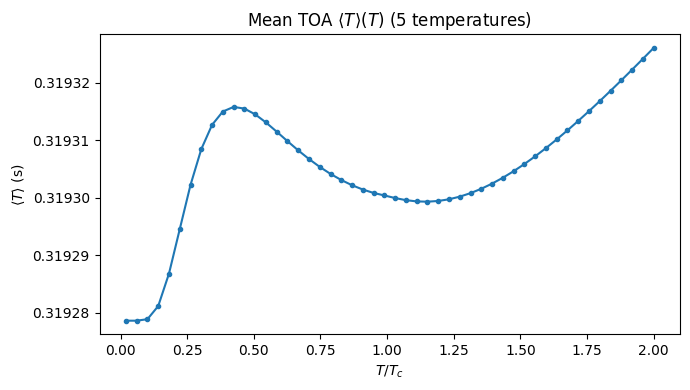

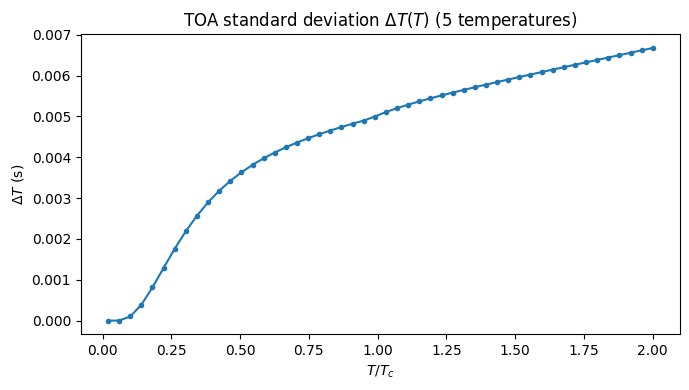

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp
from scipy.integrate import simpson

# =========================
# Parameters (edit if needed)
# =========================
hbar = const.hbar
kB   = const.Boltzmann
g    = 9.81

m    = 6.64e-27       # kg
H    = 0.50           # m
wz   = 2*math.pi*100  # rad/s
Tc   = 1.0e-6         # K (reference Tc)

# Transverse trap frequencies (needed for Eq.(12) prefactor)
wx   = 2*math.pi*1000
wy   = 2*math.pi*1000
wperp = math.sqrt(wx*wy)
wbar  = (wx*wy*wz)**(1.0/3.0)

N_target = 1e5

# =========================
# Time grid for Π(t)
# Use odd Nt for Simpson
# =========================
tc = math.sqrt(2.0*H/g)
tmin, tmax = 1e-5*tc, 100.0*tc
Nt = 5001
t_grid = np.linspace(tmin, tmax, Nt)

def z_c(t): return H - 0.5*g*t**2
def scale_t(t): return 1.0 / math.sqrt(1.0 + (wz*t)**2)
def z_tilde_of_t(t): return z_c(t) * scale_t(t)

def v_z(t):
    return (1.0/t) * (H + 0.5*g*t**2 - (H - 0.5*g*t**2)/(1.0 + (wz*t)**2))

# =========================
# Fast μ(T) (semiclassical trap inversion)
# N ≈ (kBT/ħ wbar)^3 Li_3(z), z=exp(beta μ)
# Below Tc: μ=0
# =========================
def mu_from_N_semiclassical(T, N=N_target):
    beta = 1.0/(kB*T)
    A = (kB*T/(hbar*wbar))**3
    Nmax = A * float(mp.zeta(3))  # Li_3(1)=ζ(3)

    if N >= Nmax:
        return 0.0

    target = N / A  # want Li_3(z)=target
    z_lo, z_hi = 1e-30, 1.0 - 1e-14
    for _ in range(80):
        z_mid = 0.5*(z_lo + z_hi)
        val = float(mp.polylog(3, z_mid))
        if val > target:
            z_hi = z_mid
        else:
            z_lo = z_mid
    z = 0.5*(z_lo + z_hi)
    return (1.0/beta) * math.log(z)

# =========================
# Eq.(12) density (polylog)
# =========================
def pref12(T):
    beta = 1.0/(kB*T)
    return (1.0 / (beta*hbar*wperp)**2) * (1.0 / math.sqrt(2.0*math.pi*(hbar**2)*beta/m))

def rho_eq1D_eq12(z_tilde, T, mu):
    beta = 1.0/(kB*T)
    A = 0.5 * m * beta * (wz**2) * (z_tilde**2)
    q = mp.e**(beta*mu - A)
    return float(pref12(T) * mp.polylog(2.5, q))

# =========================
# Compute Π(t), normalize, and moments for one T
# =========================
def toa_moments_one_T(T):
    mu = mu_from_N_semiclassical(T)

    J = np.empty_like(t_grid, dtype=float)
    for i, t in enumerate(t_grid):
        zt  = z_tilde_of_t(t)
        jac = scale_t(t)
        rho = rho_eq1D_eq12(zt, T, mu)
        J[i] = v_z(t) * jac * rho

    Pi = np.abs(J)

    # Normalize Π(t) numerically (Simpson)
    Z = simpson(Pi, x=t_grid)
    if (not np.isfinite(Z)) or (Z <= 0.0):
        raise RuntimeError(f"Normalization failed at T={T:.3e}. Increase tmax or Nt.")
    Pi /= Z

    # Verify normalization
    norm_check = simpson(Pi, x=t_grid)

    # Moments (Simpson)
    meanT  = simpson(t_grid * Pi, x=t_grid)
    meanT2 = simpson((t_grid**2) * Pi, x=t_grid)
    stdT   = math.sqrt(max(0.0, meanT2 - meanT**2))

    return meanT, stdT, norm_check, mu

# =========================
# 5 temperatures in [0.02Tc, 2Tc]
# =========================
T_list = np.linspace(0.02*Tc, 2.0*Tc, 50)
x_list = T_list / Tc

mean_TOA = np.zeros_like(T_list, dtype=float)
std_TOA  = np.zeros_like(T_list, dtype=float)
norms    = np.zeros_like(T_list, dtype=float)

for k, T in enumerate(T_list):
    meanT, stdT, norm_check, mu = toa_moments_one_T(T)
    mean_TOA[k] = meanT
    std_TOA[k]  = stdT
    norms[k]    = norm_check
    print(f"[{k+1}/{len(T_list)}] T/Tc={T/Tc:.3f}  ∫Πdt={norm_check:.12f}  <T>={meanT:.6g}s  ΔT={stdT:.6g}s  mu/(kBT)={mu/(kB*T):.3g}")

# =========================
# Produce ONLY the two plots requested:
# <T>(T) and ΔT(T)
# =========================
plt.figure(figsize=(7,4))
plt.plot(x_list, mean_TOA, marker='.', linewidth=1.5)
plt.xlabel(r"$T/T_c$")
plt.ylabel(r"$\langle T \rangle$ (s)")
plt.title(r"Mean TOA $\langle T\rangle(T)$ (5 temperatures)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(x_list, std_TOA, marker='.', linewidth=1.5)
plt.xlabel(r"$T/T_c$")
plt.ylabel(r"$\Delta T$ (s)")
plt.title(r"TOA standard deviation $\Delta T(T)$ (5 temperatures)")
plt.tight_layout()
plt.show()

# **PAST trial and error**

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp

# Physical constants (SI units)
hbar = const.hbar
kB   = const.Boltzmann
g    = const.g

# System parameters
m = 4 * 1.66e-27   # mass of He-4 atom [kg]

# Trap frequencies (rad/s)
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z =  100 * 2 * math.pi
w_perp = np.sqrt(w_x * w_y)
w_bar  = (w_x * w_y * w_z) ** (1.0/3.0)

# Oscillator lengths
o_x = math.sqrt(hbar / (m * w_x))
o_y = math.sqrt(hbar / (m * w_y))
o_z = math.sqrt(hbar / (m * w_z))

# Experimental parameters
N_target = 1e5
T        = 1e-6                    # Kelvin
beta     = 1.0 / (kB * T)          # inverse temperature
sigma_z  = np.sqrt(hbar / (m * w_z))
j_max    = 100                     # truncation of sum

# Time and initial height
t = 0.1   # seconds
H = 0.4   # meters

# ---------------------------------------------------------
# Eq. (5): N(mu_tilde) for a trapped ideal Bose gas / vetted
# ---------------------------------------------------------
def N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z, tol=1e-12, j_max=200000):
    beta = 1.0/(kB*T)
    ax, ay, az = beta*hbar*w_x, beta*hbar*w_y, beta*hbar*w_z
    S = mp.mpf('0.0')
    for j in range(1, j_max+1):
        num   = mp.e**(j*beta*mu_tilde)
        denom = (1 - mp.e**(-j*ax))*(1 - mp.e**(-j*ay))*(1 - mp.e**(-j*az))
        term  = num/denom
        S += term
        # early stop once tail is tiny
        if j > 10 and abs(term) < tol*max(1, abs(S)):
            break
    return float(S)

def solve_mu_tilde(N_target, T, w_x, w_y, w_z,
                   regime="auto",     # "auto" | "thermal-only" | "force-bec"
                   margin=1e-3,       # require N > (1+margin)*N_th_max to enter BEC
                   tol=1e-12, max_iter=200):

    N_th_max = N_of_mu_tilde(0.0, T, w_x, w_y, w_z)

    if regime == "force-bec":
        mu_tilde = 0.0
        N0 = max(0.0, N_target - N_th_max)
        w_bar = (w_x*w_y*w_z)**(1/3)
        T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
        return mu_tilde, N0, N_th_max, T_c_est

    if regime == "thermal-only":
        # Always solve for μ̃<0 and never create a condensate term
        mu_tilde = _solve_mu_negative(N_target, T, w_x, w_y, w_z, tol, max_iter)
        w_bar = (w_x*w_y*w_z)**(1/3)
        T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
        return mu_tilde, 0.0, N_target, T_c_est

    # AUTO mode (default): only enter BEC if *clearly* necessary
    if N_target > (1.0 + margin) * N_th_max:
        mu_tilde = 0.0
        N0 = N_target - N_th_max
        w_bar = (w_x*w_y*w_z)**(1/3)
        T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
        return mu_tilde, N0, N_th_max, T_c_est

    # Otherwise stay thermal and solve μ̃<0
    mu_tilde = _solve_mu_negative(N_target, T, w_x, w_y, w_z, tol, max_iter)
    w_bar = (w_x*w_y*w_z)**(1/3)
    T_c_est = (hbar*w_bar/kB) * (N_target/float(mp.zeta(3)))**(1/3)
    return mu_tilde, N0, N_th_max, T_c_est


def _solve_mu_negative(N_target, T, w_x, w_y, w_z, tol, max_iter):
    # Bracketed bisection on μ̃ ≤ 0 to avoid divergence
    beta = 1.0/(kB*T)
    def f(mu): return N_of_mu_tilde(mu, T, w_x, w_y, w_z) - N_target
    mu_hi = -1e-14 * kB*T  # just below 0
    mu_lo = -50.0 * kB*T
    while f(mu_lo) >= 0:
        mu_lo *= 2.0
        if mu_lo < -1e6*kB*T:
            raise RuntimeError("Failed to bracket μ̃.")
    for _ in range(max_iter):
        mid = 0.5*(mu_lo + mu_hi)
        val = f(mid)
        if abs(val) < max(1.0, N_target)*tol or abs(mu_hi-mu_lo) < abs(mu_hi)*1e-12:
            return float(mid)
        if val > 0: mu_hi = mid
        else:       mu_lo = mid
    raise RuntimeError("Bisection did not converge.")


mu_tilde, N0, N_th, T_c_est = solve_mu_tilde(N_target, T, w_x, w_y, w_z)

# Sanity check
N_check = N_of_mu_tilde(mu_tilde, T, w_x, w_y, w_z)
print(f"[Sanity check] Target N={N_target:.6g},  from Eq.(5) with mu_tilde -> N={N_check:.6g},  ΔN={N_check-N_target:.3g}")
print(f"mu_tilde / (kB T) = {mu_tilde/(kB*T):.6g}")
print(f"Estimated Tc (harmonic trap, Eq. (6)) = {T_c_est:.3e} K")
if N0>0:
    print(f"Condensate present: N0 = {N0:.3g} ({100*N0/N_target:.2f}% of atoms). Using mu_tilde=0.")


def v_z():
    return (1/t)*(H + (0.5 * g * t**2) - ((H - 0.5 * g * t**2)/(1 + w_z**2 * t**2)))
def z_c():
    return H - 0.5 * g * t**2
def z_tilde():
    return z_c() / np.sqrt(1 + ((w_z**2) * (t**2)))

def rho_eq_near():
    pref = (1 / ((beta * hbar * w_perp)**2)) * (1 / np.sqrt(2 * np.pi * (hbar**2) * beta / m))
    A = m * beta * (w_z**2) * (z_tilde()**2) / 2
    q = np.exp(beta * mu_tilde - A)
    final = pref * mp.polylog(2.5,q)
    return final

def J_final():
    result = (v_z() / np.sqrt(1 + ((w_z**2)*t**2))) * rho_eq_near() # add normalization factor later dont forget
    return result

# Time grid
tc   = np.sqrt(2.0 * H / g)          # classical free-fall time
tmin = max(1e-6, 1e-3 * tc)              # small positive start
tmax = 2.0 * tc                          # extend beyond arrival
Nt   = 2000
t_grid = np.linspace(tmin, tmax, Nt)

# Prefactor that doesn't depend on t
pref = (1.0 / ((beta * hbar * w_perp)**2)) * (1.0 / np.sqrt(2.0 * np.pi * (hbar**2) * beta / m))

J_t = np.zeros_like(t_grid, dtype=float)

for i, tj in enumerate(t_grid):
    scale_t = 1.0 / np.sqrt(1.0 + (w_z**2) * (tj**2))
    zc = H - 0.5 * g * tj**2
    zt = zc * scale_t
    A  = 0.5 * m * beta * (w_z**2) * (zt**2)
    q  = mp.e**(beta * mu_tilde - A)
    rho = pref * mp.polylog(2.5, q)

    # v_z(t) (expanded here)
    vz = (1.0/tj) * (H + 0.5*g*tj**2 - (H - 0.5*g*tj**2) / (1.0 + (w_z**2) * (tj**2)))

    J_t[i] = (vz * scale_t) * float(rho)

plt.figure(figsize=(7,4))
plt.plot(t_grid, J_t)
plt.xlabel("Time $t$ (s)")
plt.ylabel(r"$\langle J(H_{\mathrm{fix}},t)\rangle$")
plt.title(fr"Current vs time at fixed $H$ m")
plt.tight_layout()
plt.show()


UnboundLocalError: cannot access local variable 'N0' where it is not associated with a value

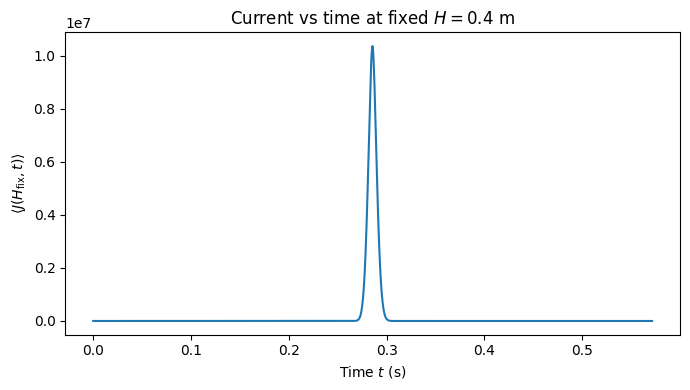

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp

# Physical constants (SI units)
hbar = const.hbar
kB   = const.Boltzmann
g    = const.g

# System parameters
m = 4 * 1.66e-27   # mass of He-4 atom [kg]

# Trap frequencies (rad/s)
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z =  100 * 2 * math.pi
w_perp = np.sqrt(w_x * w_y)
w_bar  = (w_x * w_y * w_z) ** (1.0/3.0)

# Oscillator lengths
o_x = math.sqrt(hbar / (m * w_x))
o_y = math.sqrt(hbar / (m * w_y))
o_z = math.sqrt(hbar / (m * w_z))

# Experimental parameters
N_target = 1e5
T        = 1e-6                    # Kelvin
beta     = 1.0 / (kB * T)          # inverse temperature
mu_tilde = -0.5 * hbar * w_z       # shifted chemical potential
sigma_z  = np.sqrt(hbar / (m * w_z))
j_max    = 100                     # truncation of sum

# Time and initial height
t = 0.1   # seconds
H = 0.4   # meters

def v_z():
    	return (1/t)*(H + (0.5 * g * t**2) - ((H - 0.5 * g * t**2)/(1 + w_z**2 * t**2)))

def z_c():
    return H - 0.5 * g * t**2

def z_tilde():
    return z_c() / np.sqrt(1 + ((w_z**2) * (t**2)))


def rho_eq_near():
    pref = (1 / ((beta * hbar * w_perp)**2)) * (1 / np.sqrt(2 * np.pi * (hbar**2) * beta / m))
    A = m * beta * (w_z**2) * (z_tilde()**2) / 2
    q = np.exp(beta * mu_tilde - A)
    final = pref * mp.polylog(2.5,q)
    return final

def J_final():
    result = (v_z() / np.sqrt(1 + ((w_z**2)*t**2))) * rho_eq_near() # add normalization factor later dont forget
    return result

# Fixed initial height
H_fix = H

# Time grid
tc   = np.sqrt(2.0 * H_fix / g)          # classical free-fall time
tmin = max(1e-6, 1e-3 * tc)              # small positive start
tmax = 2.0 * tc                          # extend beyond arrival
Nt   = 2000
t_grid = np.linspace(tmin, tmax, Nt)

# Prefactor that doesn't depend on t
pref = (1.0 / ((beta * hbar * w_perp)**2)) * (1.0 / np.sqrt(2.0 * np.pi * (hbar**2) * beta / m))

J_t = np.zeros_like(t_grid, dtype=float)

for i, tj in enumerate(t_grid):
    scale_t = 1.0 / np.sqrt(1.0 + (w_z**2) * (tj**2))
    zc = H_fix - 0.5 * g * tj**2
    zt = zc * scale_t
    A  = 0.5 * m * beta * (w_z**2) * (zt**2)
    q  = mp.e**(beta * mu_tilde - A)
    rho = pref * mp.polylog(2.5, q)

    # v_z(t) (expanded here)
    vz = (1.0/tj) * (H_fix + 0.5*g*tj**2 - (H_fix - 0.5*g*tj**2) / (1.0 + (w_z**2) * (tj**2)))

    J_t[i] = (vz * scale_t) * float(rho)

plt.figure(figsize=(7,4))
plt.plot(t_grid, J_t)
plt.xlabel("Time $t$ (s)")
plt.ylabel(r"$\langle J(H_{\mathrm{fix}},t)\rangle$")
plt.title(fr"Current vs time at fixed $H={H_fix}$ m")
plt.tight_layout()
plt.show()


/tmp/ipython-input-4083265545.py:88: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  Z = np.trapz(rho_wide, z_wide)  # scalar


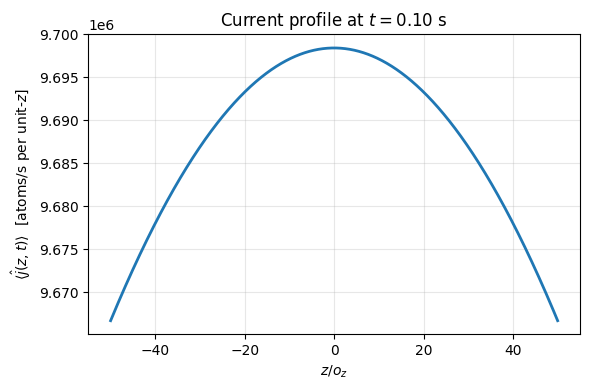

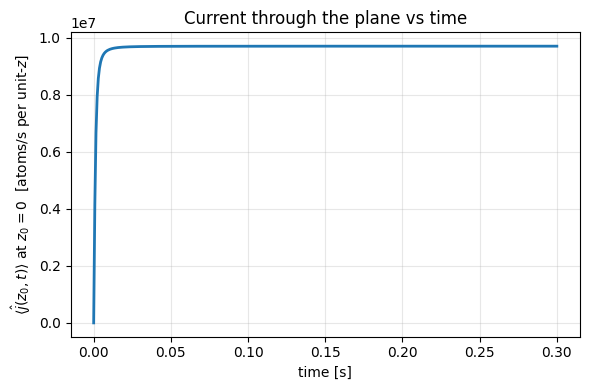

TypeError: z_tilde() takes 0 positional arguments but 4 were given

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import mpmath as mp

# -----------------------------
# Physical constants (SI units)
# -----------------------------
hbar = const.hbar
kB   = const.Boltzmann
g    = const.g

# -----------------------------
# System parameters
# -----------------------------
m = 4 * 1.66e-27   # mass of He-4 atom [kg]

# Trap frequencies (rad/s)
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z =  100 * 2 * math.pi

# -----------------------------
# Oscillator lengths
# -----------------------------
o_x = math.sqrt(hbar / (m * w_x))
o_y = math.sqrt(hbar / (m * w_y))
o_z = math.sqrt(hbar / (m * w_z))

# -----------------------------
# Experimental parameters
# -----------------------------
T        = 1e-6                    # Kelvin
beta     = 1.0 / (kB * T)          # inverse temperature
mu_tilde = -0.5 * hbar * w_z       # shifted chemical potential
sigma_z  = np.sqrt(hbar / (m * w_z))
j_max    = 100                     # truncation of sum

# -----------------------------
# Time and initial height
# -----------------------------
t = 0.1   # seconds
H = 0.4   # meters  (not used here; keep if needed elsewhere)

# -----------------------------
# z grid (meters) for plotting
# -----------------------------
z_values = np.linspace(-50 * o_z, 50 * o_z, 5000)

# -----------------------------
# ρ_eq,1(z̃) with μ̃  (unnormalized line density)
# -----------------------------
def rho_eq1_mu_tilde(z, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=100):
    j = np.arange(1, j_max + 1, dtype=float)[:, None]   # shape (j_max, 1)
    z = np.atleast_1d(z)[None, :]                       # shape (1, Nz)

    tau_y = j * beta * hbar * w_y
    tau_z = j * beta * hbar * w_z

    pref_exp   = np.exp(j * beta * mu_tilde)
    den_y      = -np.expm1(-tau_y)
    den_z      = -np.expm1(-tau_z)
    prod_alpha = 1.0 / (den_y * den_z)
    gauss_pref = 1.0 / (sigma_z * np.sqrt(np.pi * (-np.expm1(-2.0 * tau_z))))
    exp_factor = np.exp(-np.tanh(0.5 * tau_z) * (z**2 / sigma_z**2))

    terms = pref_exp * prod_alpha * gauss_pref * exp_factor
    rho = np.sum(terms, axis=0)
    return rho if rho.size > 1 else rho.item()

# -----------------------------
# Scaling & velocity
# -----------------------------
def b_t(t, w_z):
    return np.sqrt(1.0 + (w_z * np.asarray(t))**2)

def v_z_of_t(t):
    # center-of-mass velocity along z; edit if needed
    return g * np.asarray(t)

# -----------------------------
# Normalize ρ_eq,1(z): compute Z = ∫ ρ(z) dz once
# -----------------------------
# Use a *wide* grid to capture the tails well
z_wide = np.linspace(-200 * o_z, 200 * o_z, 40001)
rho_wide = rho_eq1_mu_tilde(z_wide, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=j_max)
Z = np.trapz(rho_wide, z_wide)  # scalar

# -----------------------------
# Current through a plane (normalized)
# j(z,t) = N_atoms * [v_z(t)/b(t)] * [ρ_eq,1(z/b(t)) / Z]
# With this normalization, ∫ j(z,t) dz = N_atoms * v_z(t).
# -----------------------------
def j_current_norm(z, t, N_atoms, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=100):
    b = b_t(t, w_z)
    rho_scaled = rho_eq1_mu_tilde(np.asarray(z) / b, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=j_max) / Z
    return N_atoms * (v_z_of_t(t) / b) * rho_scaled


# -----------------------------
# Compute & plot CURRENT profile at fixed time t
# -----------------------------
N_atoms = 1.0e5  # set to your total atom number

j_profile = j_current_norm(z_values, t, N_atoms, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=j_max)

plt.figure(figsize=(6, 4))
plt.plot(z_values / o_z, j_profile, lw=2)
plt.xlabel(r"$z / o_z$")
plt.ylabel(r"$\langle \hat{j}(z,t)\rangle$  [atoms/s per unit-$z$]")
plt.title(fr"Current profile at $t={t:.2f}$ s")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# -----------------------------
# (Optional) current through a fixed plane z0 vs time
# -----------------------------
z0 = 0.0
t_array = np.linspace(0, 0.3, 400)  # seconds

# Vectorized over t_array: z0 is scalar, so j_current_norm returns a 1D array
j_vs_t = j_current_norm(z0, t_array, N_atoms, beta, mu_tilde, hbar, w_y, w_z, sigma_z, j_max=j_max)

plt.figure(figsize=(6,4))
plt.plot(t_array, j_vs_t, lw=2)
plt.xlabel("time [s]")
plt.ylabel(r"$\langle \hat{j}(z_0,t)\rangle$ at $z_0=0$  [atoms/s per unit-$z$]")
plt.title("Current through the plane vs time")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(z_tilde(1,2,3,4))


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma
import scipy.constants as const


# -----------------------------
# Parameters (fill these in later)
# -----------------------------
beta = None      # inverse temperature, 1 / (k_B * T)
mu = None        # chemical potential
hbar = None      # reduced Planck constant
omega_y = None   # trap frequency along y
omega_z = None   # trap frequency along z
sigma_z = None   # characteristic length along z

# Example grid for z (you can adjust the range/resolution)
z_values = np.linspace(-5, 5, 500)  # dimensionless, or in meters depending on sigma_z

# -----------------------------
# Function definition
# -----------------------------
def rho_eq1(z, beta, mu, hbar, omega_y, omega_z, sigma_z, j_max=500, use_mu_tilde=True):
    # guardrails
    for name, val in dict(beta=beta, mu=mu, hbar=hbar, omega_y=omega_y, omega_z=omega_z, sigma_z=sigma_z).items():
        if val is None:
            raise ValueError(f"Parameter '{name}' is None. Please set it before calling rho_eq1().")

    # optional μ̃ = μ - ħωz/2 (recommended per your definitions)
    mu_eff = mu - 0.5*hbar*omega_z if use_mu_tilde else mu

    j = np.arange(1, j_max+1, dtype=float)[:, None]  # (j_max, 1)
    z = np.atleast_1d(z)[None, :]                     # (1, M)

    # τ_y = j β ħ ω_y, τ_z = j β ħ ω_z
    tau_y = j * beta * hbar * omega_y
    tau_z = j * beta * hbar * omega_z

    # prefactor e^{j β μ̃}
    pref_exp = np.exp(j * beta * mu_eff)

    # product over α=y,z : 1 / (1 - e^{-τ_α})  -> use -expm1(-τ) for stability
    den_y = -np.expm1(-tau_y)
    den_z = -np.expm1(-tau_z)
    prod_alpha = 1.0 / (den_y * den_z)

    # Gaussian prefactor: 1 / [σ_z √(π (1 - e^{-2 τ_z}))]  (use -expm1(-2τ) for stability)
    gauss_pref = 1.0 / (sigma_z * np.sqrt(np.pi * (-np.expm1(-2.0 * tau_z))))

    # exponential factor: exp( -tanh(τ_z/2) * (z^2/σ_z^2) )
    exp_factor = np.exp(-np.tanh(0.5 * tau_z) * (z**2 / sigma_z**2))

    terms = pref_exp * prod_alpha * gauss_pref * exp_factor
    rho = np.sum(terms, axis=0)
    return rho if rho.size > 1 else rho.item()


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import gamma
import scipy.constants as const





rho_eq_perp =

def rho_eq_perp_loop(N,w_x,w_y,w_z,o_z,mu):


current_z_H = N * (v_z/math.sqrt(1 + w_z**2 * t**2)) * rho_eq_perp


# Constants
hbar = const.hbar
kB = const.Boltzmann
m = 4 * 1.66*10**-27  # mass of He 4
g = const.g  # gravity

# Trap frequencies (Hz)
w_x = 1000 * 2 * math.pi
w_y = 1000 * 2 * math.pi
w_z = 100 * 2 * math.pi

# Oscillator lengths
o_x = math.sqrt(hbar / (m*w_x))
o_y = math.sqrt(hbar / (m*w_y))
o_z = math.sqrt(hbar / (m*w_z))

# Experimental parameters
T = 1e-6  # Kelvin
beta = 1 / (kB * T)
mu_tilde = -0.5 * hbar * w_z
sigma_z = np.sqrt(hbar / (m * w_z))
j_max = 100  # max summation index

# Time and initial height
t = 0.1  # seconds
H = 0.4  # initial height in meters

# v_z(t)
def v_z(t, H, g, w_z):
    return (1/t)*(H + (0.5 * g * t**2) - ((H - 0.5 * g * t**2)/(1 + w_z**2 * t**2)))

# rho_eq_perp
def rho_eq_perp(z, beta, mu_tilde, sigma_z, w_y, w_z, j_max=100):
    rho_eq_perp = 0
    for j in range(1, N + 1):
        exp_factor = np.exp(j * beta * mu_tilde)
        partition_y = 1 / (1 - np.exp(-j * beta * hbar * w_y))
        partition_z = 1 / (1 - np.exp(-j * beta * hbar * w_z))
        gauss_prefactor = 1 / (sigma_z * np.sqrt(np.pi * (1 - np.exp(-2 * j * beta * hbar * w_z))))
        exponent = -np.tanh(j * beta * hbar * w_z / 2) * (z**2 / sigma_z**2)
        rho_eq_perp += exp_factor * partition_y * partition_z * gauss_prefactor * np.exp(exponent)
    return rho_eq_perp

# Wrapper for evaluating at a range of z positions
def rho_eq_perp_loop(N, w_x, w_y, w_z, mu_tilde, H, t, g):
    z_c = H - 0.5 * g * t**2
    z_tilde = z_c / np.sqrt(1 + w_z**2 * t**2)
    vz = v_z(t, H, g, w_z)
    scaling = vz / np.sqrt(1 + w_z**2 * t**2)
    rho_val = rho_eq_perp(z_tilde, beta, mu_tilde, sigma_z, w_y, w_z, j_max)
    return N * scaling * rho_val

# Example call
N = 1e6  # Total atom number
current_z_H = rho_eq_perp_loop(N, w_x, w_y, w_z, mu_tilde, H, t, g)
current_z_H


SyntaxError: invalid syntax (ipython-input-2606735050.py, line 12)